# 📚 Minando lo Aleatorio v2 — Bloque A: Fundamentos Estadísticos

### *Text Mining en la Biblioteca de Babel — con null model y controles*

> *"La Biblioteca de Babel contiene todos los libros posibles... en algún lugar de ella se encuentra cada verdad, cada pensamiento coherente — y también el caos puro."* — J.L. Borges

---

## 🎯 Qué cambia respecto al estudio original

El notebook original aplicaba un pipeline clásico de NLP (tokenización, stopwords, stemming, lematización, frecuencias, BoW/TF-IDF, sentimiento) y reportaba "sesgos sorprendentes" en el texto aleatorio. El problema metodológico: **no había forma de saber si esos sesgos eran propiedades del texto o artefactos de las herramientas.**

Este v2 corrige eso introduciendo el método científico estándar para validar aleatoriedad:

| Componente | Para qué sirve |
|------------|----------------|
| **Null model** (Babel sintético) | Generar texto con la *misma ley aleatoria* y comparar |
| **Control positivo ES/EN** | Lenguaje natural real (Moby Dick + CESS-ESP) como referencia de "estructura genuina" |
| **Tests de aleatoriedad** | Entropía, compresión, Zipf, Heaps, χ² — métricas formales |
| **Veredicto Monte Carlo** | Ubicar cada métrica de Babel en la distribución del null model |

**La pregunta del README — *"¿deja rastros la verdadera aleatoriedad?"* — pasa de ser impresionista a ser demostrable.**

---

## 📂 Dataset

El notebook **localiza los `.txt` automáticamente**, en este orden: `data/` dentro del proyecto → carpeta padre (raíz del repo, donde están los 10 libros originales) → el propio proyecto. Gana la primera ubicación que contenga archivos `.txt`.

Los libros descargados de libraryofbabel.info traen metadata alrededor del cuerpo aleatorio (línea de título y footer `Book Location:4-w1-s1-v09`). El loader la retira y la deja registrada para poder auditarla — ver sección 1.

---

## 🔧 Correcciones aplicadas a esta corrida

La primera ejecución se hizo sobre **2 muestras de ~9.5 KB**, no sobre el corpus completo, y eso destapó varios problemas que se corrigieron antes de escalar:

| # | Problema | Corrección |
|---|----------|------------|
| 1 | La metadata (`Book Location`, título) entraba al corpus e introducía mayúsculas y dígitos ajenos al alfabeto de 30 | `parsear_libro_babel()` la separa y la registra |
| 2 | `N_REF = max(...)` pero Babel se representaba con `corpus_babel[0][:N_REF]` → Babel se comparaba a 3.255 chars contra el resto a 6.344 | `N_REF = min(...)` sobre **todas** las condiciones (los controles NLTK son más cortos que un libro de Babel) + `assert` de igualdad |
| 3 | `chi2_uniformidad` descartaba en silencio las categorías de conteo 0 → sesgo hacia "uniforme" | Espacio de categorías completo (A^n) |
| 4 | `ley_zipf` ajustaba sobre todos los rangos: la cola de hapax domina y da R²≈0.4 sin significado | Flag `excluir_hapax` (ver `EXCLUIR_HAPAX_ZIPF`); se reportan ambos ajustes |
| 5 | El bucle Monte Carlo calculaba gzip+bz2+lzma+zstd para usar solo gzip, y la entropía dos veces | Solo se calcula lo que se usa |
| 6 | spaCy rechaza documentos de más de 1M de chars (error E088) → la lematización reventaba a escala real | `aplicar_lematizacion` procesa por bloques |
| 7 | El null model no replicaba la paginación (409 líneas en blanco), así que su frecuencia de `\n` era 1/81 y no 1/79,06 → Babel salía "distinguible" en entropía por formato | `perfil_formato()` mide la disposición real y `generar_babel_sintetico` la reproduce |
| 8 | `limpiar_texto` **borraba** comas y puntos en vez de tratarlos como frontera, pegando tokens vecinos. Sesgo asimétrico: en Babel el largo medio de token pasaba de 8,7 a 20,0; en los controles apenas cambiaba. Además `babel_core` y `babel_pipeline` contaban tokens distintos del mismo texto | Los no alfabéticos pasan a espacio (frontera de palabra) + normalización de acentos; los dos módulos unificados |

> ⚠️ Los textos markdown de las secciones 7 (Conclusiones) citan números de la corrida anterior. **Hay que revisarlos contra la salida nueva** antes de dar el Bloque A por cerrado.

## 0. Setup y configuración

Importamos los módulos del proyecto (`src/babel_core.py` y `src/babel_pipeline.py`), que encapsulan toda la lógica reutilizable. Esto mantiene el notebook legible y la lógica testeable.


In [1]:
# Configuración de rutas (sin hardcoding — usa pathlib)
import sys
from pathlib import Path

# Detectar la carpeta del proyecto y añadir src/ al path
RUTA_PROYECTO = Path.cwd()
if (RUTA_PROYECTO / "src").exists():
    RUTA_SRC = RUTA_PROYECTO / "src"
elif (RUTA_PROYECTO.parent / "src").exists():
    RUTA_SRC = RUTA_PROYECTO.parent / "src"
    RUTA_PROYECTO = RUTA_PROYECTO.parent
else:
    RUTA_SRC = RUTA_PROYECTO

sys.path.insert(0, str(RUTA_SRC))

RUTA_OUTPUTS = RUTA_PROYECTO / "outputs"
RUTA_FIGURAS = RUTA_PROYECTO / "figures"
RUTA_OUTPUTS.mkdir(exist_ok=True)
RUTA_FIGURAS.mkdir(exist_ok=True)

# --- Localización de los datos ---------------------------------------------
# Se busca en orden: data/ dentro del proyecto -> data/ en la raíz del repo ->
# carpeta padre -> el propio proyecto. Gana la primera ubicación que
# efectivamente contenga archivos .txt. Los 10 libros viven en <repo>/data/.
CANDIDATOS_DATOS = [
    RUTA_PROYECTO / "data",
    RUTA_PROYECTO.parent / "data",
    RUTA_PROYECTO.parent,
    RUTA_PROYECTO,
]
RUTA_DATOS = next(
    (d for d in CANDIDATOS_DATOS if d.exists() and any(d.glob("*.txt"))),
    RUTA_PROYECTO / "data",
)
N_ARCHIVOS = len(list(RUTA_DATOS.glob("*.txt"))) if RUTA_DATOS.exists() else 0

print(f"Proyecto : {RUTA_PROYECTO}")
print(f"Datos    : {RUTA_DATOS}  ({N_ARCHIVOS} archivos .txt)")
print(f"Outputs  : {RUTA_OUTPUTS}")
print(f"Figuras  : {RUTA_FIGURAS}")

if N_ARCHIVOS == 0:
    print("\n⚠️  No se encontraron .txt de Babel en ninguna ubicación candidata:")
    for d in CANDIDATOS_DATOS:
        print(f"      {d}")
elif N_ARCHIVOS < 10:
    print(f"\n⚠️  Solo {N_ARCHIVOS} archivo(s). El estudio definitivo usa los 10 libros completos.")

Proyecto : C:\Users\diego.perezp\Documents\GitHub\Mining the Random - Library of Babel\Babel_V2
Datos    : C:\Users\diego.perezp\Documents\GitHub\Mining the Random - Library of Babel\data  (10 archivos .txt)
Outputs  : C:\Users\diego.perezp\Documents\GitHub\Mining the Random - Library of Babel\Babel_V2\outputs
Figuras  : C:\Users\diego.perezp\Documents\GitHub\Mining the Random - Library of Babel\Babel_V2\figures


In [2]:
# Imports del stack científico y módulos propios
import importlib
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import babel_core as bc
import babel_pipeline as bp
import babel_viz as bviz

# Recarga forzada de los módulos de src/.
#
# El notebook es la capa de presentación y src/ el motor (§4.1 de CONTEXT.md).
# Python cachea los módulos en sys.modules: si editas un .py y vuelves a correr
# el notebook SIN reiniciar el kernel, sigues usando la versión vieja y las
# funciones nuevas revientan con AttributeError. Esto lo evita.
importlib.reload(bc)
importlib.reload(bp)
importlib.reload(bviz)

# Reproducibilidad
SEED = 2026
np.random.seed(SEED)

# Estilo de visualización
# Sistema visual único: paleta ligada a la entidad, rejilla de un pelo,
# secuencial de un solo tono. Ver babel_viz.
sns.set_theme(style="white", context="notebook")
bviz.aplicar_estilo()

# Parámetros del estudio (CONFIRMADOS con el autor)
N_REPLICAS_MC = 100          # réplicas Monte Carlo del null model
UMBRAL_LONGITUD = 3          # filtro de tokens cortos (estándar text mining)

# Ajuste de Zipf: excluir la cola de hapax (frecuencia 1) del ajuste log-log.
# En texto aleatorio esa cola es casi todo el vocabulario y es una recta
# HORIZONTAL que domina el ajuste por peso numérico, produciendo pendientes y
# R² sin significado (R²~0.4 idéntico en Babel y en el null model). Ponerlo en
# False reproduce el comportamiento de la primera corrida.
EXCLUIR_HAPAX_ZIPF = True

# Modo rápido: recorta el corpus para un smoke test antes de la corrida larga.
# None = usar los textos completos (corrida definitiva).
MODO_RAPIDO_CHARS = None     # p. ej. 200_000 para probar en ~1 min

# --- Chequeo de versión: que el kernel tenga de verdad el código de src/ -----
_API = {
    "bc": ["parsear_libro_babel", "perfil_formato", "generar_babel_sintetico",
           "generar_replicas_null", "ratios_compresion", "ley_zipf",
           "ley_heaps", "chi2_uniformidad", "entropia_shannon"],
    "bp": ["limpiar_texto", "aplicar_lematizacion", "analizar_sentimiento"],
    "bviz": ["aplicar_estilo", "panel_veredicto", "COLOR_CONDICION",
             "correlacion_palabras", "prob_superar_umbral"],
}
_faltan = [f"{m}.{f}" for m, fs in _API.items()
           for f in fs if not hasattr({"bc": bc, "bp": bp, "bviz": bviz}[m], f)]
if _faltan:
    raise ImportError(
        f"El kernel tiene una versión vieja de src/. Faltan: {_faltan}. "
        "Reinicia el kernel (Kernel > Restart) y vuelve a correr."
    )

print("Configuración del estudio:")
print(f"  Réplicas Monte Carlo : {N_REPLICAS_MC}")
print(f"  Umbral de longitud   : >={UMBRAL_LONGITUD}")
print(f"  Zipf sin cola hapax  : {EXCLUIR_HAPAX_ZIPF}")
print(f"  Modo rápido          : {MODO_RAPIDO_CHARS or 'desactivado (corpus completo)'}")
print(f"  Semilla              : {SEED}")
print(f"  zstandard disponible : {bc._HAS_ZSTD}")
print(f"  API de src/          : completa")


Configuración del estudio:
  Réplicas Monte Carlo : 100
  Umbral de longitud   : >=3
  Zipf sin cola hapax  : True
  Modo rápido          : desactivado (corpus completo)
  Semilla              : 2026
  zstandard disponible : True
  API de src/          : completa


## 1. Carga del corpus Babel

Cargamos todos los libros aleatorios extraídos de [libraryofbabel.info](https://libraryofbabel.info). El loader auto-detecta cuántos archivos hay.


In [3]:
# Cargar corpus Babel
# El loader retira la metadata que añade libraryofbabel.info (línea de título y
# footer 'Book Location:4-w1-s1-v09'). Esos strings traen mayúsculas, dígitos,
# ':' y '-' que NO pertenecen al alfabeto de 30 de Babel: si entran, contaminan
# el perfil del alfabeto y la calibración del null model.
corpus_babel = bc.cargar_corpus_babel(RUTA_DATOS)

df_babel = pd.DataFrame([
    {
        "documento": c.nombre,
        "archivo": c.meta["archivo"],
        "n_chars": c.n_chars,
        "n_chars_crudo": c.meta.get("n_chars_crudo"),
        "titulo_retirado": c.meta.get("titulo"),
        "location_retirada": c.meta.get("location"),
    }
    for c in corpus_babel
])
print(f"Libros de Babel cargados: {len(corpus_babel)}")
print(f"Total de caracteres (cuerpo): {df_babel['n_chars'].sum():,}")

n_desc = sum(len(c.meta.get("lineas_descartadas", [])) for c in corpus_babel)
print(f"Líneas de metadata descartadas: {n_desc}")

# Verificación explícita: el cuerpo debe quedarse en el alfabeto de 30 símbolos
simbolos_cuerpo = set("".join(c.texto for c in corpus_babel))
fuera = sorted(simbolos_cuerpo - set(bc.ALFABETO_CONTENIDO) - {"\n"})
print(f"Símbolos fuera del alfabeto canónico: {fuera or 'ninguno ✓'}")

df_babel

Libros de Babel cargados: 10
Total de caracteres (cuerpo): 13,288,080
Líneas de metadata descartadas: 10
Símbolos fuera del alfabeto canónico: ninguno ✓


,documento,archivo,n_chars,n_chars_crudo,titulo_retirado,location_retirada
0,Babel_01,bxxu rpbghskztln zjil.txt,1328808,1328860,bxxu rpbghskztln zjil,Book Location:4-w1-s1-v09
1,Babel_02,cdey dssr oej.txt,1328808,1328853,cdey dssr oej,Book Location:3s-w3-s1-v26
2,Babel_03,dozwqk k jrq.txt,1328808,1328852,.dozwqk k jrq,Book Location:4-w1-s1-v07
3,Babel_04,"klpaj, mmtba.txt",1328808,1328851,"klpaj, mmtba",Book Location:4-w1-s1-v03
4,Babel_05,klqb.mrtwzwfeivestjv.m.txt,1328808,1328861,klqb.mrtwzwfeivestjv.m,Book Location:4-w1-s1-v05
5,Babel_06,"lbd.q.d ,oabolefitxjokn.txt",1328808,1328862,"lbd.q.d ,oabolefitxjokn",Book Location:4-w1-s1-v06
6,Babel_07,nhutqxpwtgdgnxugxnk yo.txt,1328808,1328861,nhutqxpwtgdgnxugxnk yo,Book Location:4-w1-s1-v04
7,Babel_08,"oefu.g,stxcjxnxkypfthz.txt",1328808,1328861,"oefu.g,stxcjxnxkypfthz",Book Location:4-w1-s1-v10
8,Babel_09,"r,fvrxaalg boyh.txt",1328808,1328854,"r,fvrxaalg boyh",Book Location:4-w1-s1-v08
9,Babel_10,"wjm.jx qfjo nfno,p.txt",1328808,1328857,"wjm.jx qfjo nfno,p",Book Location:4-w1-s1-v11


## 2. Anatomía de Babel: alfabeto y formato

Antes de generar el null model necesitamos conocer la **ley generadora** del texto. Son dos cosas distintas y las dos importan:

1. **El alfabeto y sus frecuencias** — qué símbolos usa y con qué probabilidad.
2. **El formato físico** — dónde caen los saltos de línea. El `\n` **no es un símbolo aleatorio más**: aparece en posiciones deterministas, y su frecuencia entra directamente en la entropía de Shannon.

Ignorar lo segundo tiene consecuencias medibles. Los libros reales son **410 páginas × 40 líneas × 80 caracteres**, con una línea en blanco separando páginas — esas 409 líneas en blanco suben la frecuencia real de `\n` a 1/79,06 en vez de 1/81. Un null model que solo replique "salto cada 80 caracteres" queda con menor entropía de forma sistemática, y Babel sale "distinguible" en el veredicto por un motivo puramente tipográfico.

> Las 410 páginas no son casualidad: es el número que Borges fija en *La Biblioteca de Babel*, y el sitio lo implementa al pie de la letra.


In [4]:
# Perfil del alfabeto agregando todos los libros
texto_completo_babel = "".join(c.texto for c in corpus_babel)
perfil = bc.perfil_alfabeto(texto_completo_babel)

print(f"Símbolos únicos en Babel: {perfil['n_simbolos']}")
print(f"Inventario: {perfil['inventario']}")
print()

# Distribución de probabilidad
probs_babel = bc.estimar_prob_contenido(corpus_babel)
df_probs = pd.DataFrame([
    {"simbolo": repr(ch), "probabilidad": p, "pct": 100*p}
    for ch, p in sorted(probs_babel.items(), key=lambda x: -x[1])
])
print("Distribución de símbolos de contenido (top 10):")
print(df_probs.head(10).to_string(index=False))

# --- Formato FÍSICO: el '\n' no es un símbolo aleatorio más -----------------
# Aparece en posiciones deterministas y su frecuencia entra directo en la
# entropía, así que hay que MEDIRLA, no asumirla. Si el null model no la
# reproduce, Babel sale "distinguible" por formato y no por aleatoriedad.
formato_babel = bc.perfil_formato(corpus_babel[0].texto)
print("\nFormato físico del libro (medido, no asumido):")
for k, v in formato_babel.items():
    print(f"  {k:<22}: {v}")

_pag = formato_babel["n_paginas"]
_lin = formato_babel["lineas_por_pagina"]
_anc = formato_babel["ancho_linea"]
print(f"\n-> {_pag} páginas x {_lin} líneas x {_anc} caracteres "
      f"= {_pag*_lin*_anc:,} chars de contenido")
print(f"-> frecuencia real de salto: 1/{1/formato_babel['freq_salto']:.2f} "
      f"(sería 1/{_anc+1} sin las líneas en blanco entre páginas)")
print(f"-> las {_pag} páginas son el número que Borges fija en el cuento")


Símbolos únicos en Babel: 30
Inventario: ['\n', ' ', ',', '.', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

Distribución de símbolos de contenido (top 10):
simbolo  probabilidad      pct
    'n'      0.034578 3.457820
    ','      0.034566 3.456623
    'i'      0.034559 3.455854
    'h'      0.034553 3.455343
    'j'      0.034546 3.454627
    'q'      0.034542 3.454215
    's'      0.034541 3.454055
    'f'      0.034534 3.453415
    'm'      0.034526 3.452622
    'c'      0.034525 3.452515

Formato físico del libro (medido, no asumido):
  ancho_linea           : 80
  lineas_por_pagina     : 40
  n_lineas_contenido    : 16400
  n_lineas_vacias       : 409
  n_paginas             : 410
  freq_salto            : 0.012648930470015233
  distribucion_largos   : {80: 16400}

-> 410 páginas x 40 líneas x 80 caracteres = 1,312,000 chars de contenido
-> frecuencia real de salto: 1/79.06 (sería 1/81 sin las lí

C:\Users\diego.perezp\AppData\Local\Temp\ipykernel_12652\46236938.py:21: UserWarning: Glyph 9251 (\N{OPEN BOX}) missing from font(s) Segoe UI.
  plt.tight_layout()
C:\Users\diego.perezp\AppData\Local\Temp\ipykernel_12652\46236938.py:22: UserWarning: Glyph 9251 (\N{OPEN BOX}) missing from font(s) Segoe UI.
  plt.savefig(RUTA_FIGURAS / "01_distribucion_alfabeto.png", dpi=150)
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9251 (\N{OPEN BOX}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


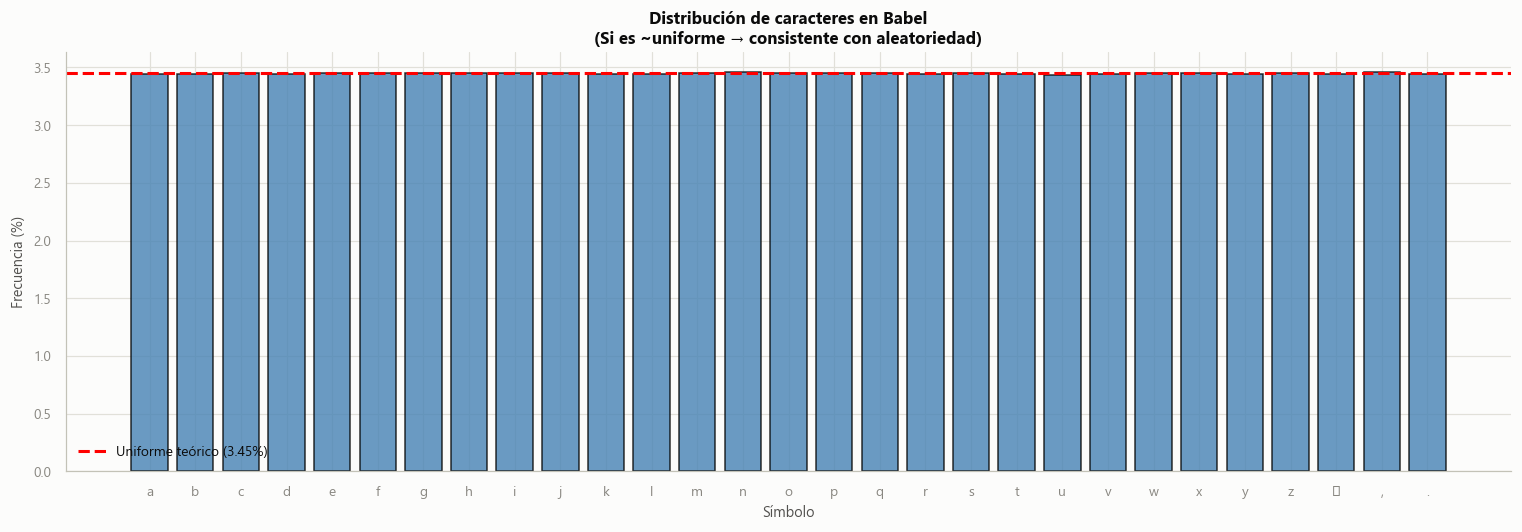


Desviación de la uniformidad: 0.0059 puntos porcentuales
→ Cuanto más cerca de 0, más uniforme (más aleatorio)


In [5]:
# Visualizar: ¿es uniforme la distribución de caracteres?
fig, ax = plt.subplots(figsize=(14, 5))

simbolos = list(probs_babel.keys())
valores = [probs_babel[s]*100 for s in simbolos]
etiquetas = [repr(s).strip("'") if s != " " else "␣" for s in simbolos]

# Línea de uniformidad teórica
uniforme = 100 / len(simbolos)

ax.bar(range(len(simbolos)), valores, color="steelblue", edgecolor="black", alpha=0.8)
ax.axhline(uniforme, color="red", linestyle="--", linewidth=2,
           label=f"Uniforme teórico ({uniforme:.2f}%)")
ax.set_xticks(range(len(simbolos)))
ax.set_xticklabels(etiquetas)
ax.set_xlabel("Símbolo")
ax.set_ylabel("Frecuencia (%)")
ax.set_title("Distribución de caracteres en Babel\n(Si es ~uniforme → consistente con aleatoriedad)",
             fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "01_distribucion_alfabeto.png", dpi=150)
plt.show()

print(f"\nDesviación de la uniformidad: {np.std(valores):.4f} puntos porcentuales")
print("→ Cuanto más cerca de 0, más uniforme (más aleatorio)")

## 3. Construcción de las condiciones experimentales

El núcleo metodológico del estudio. Comparamos **4 condiciones**:

1. **Babel** — el texto aleatorio real bajo estudio.
2. **Null model** — texto sintético generado con la *misma ley aleatoria* (muestreo i.i.d. sobre el alfabeto real). Si Babel es genuinamente aleatorio, debe ser **indistinguible** de esto.
3. **Control EN** — *Moby Dick* (Melville, 1851). Lenguaje natural real, dominio público.
4. **Control ES** — corpus CESS-ESP. Español anotado, estándar académico.

Los controles son la referencia de "cómo se ve la estructura lingüística genuina". Todos se normalizan al mismo tamaño para comparación justa.


In [6]:
# --- Tamaño de referencia: TODAS las condiciones al MISMO N -----------------
# CORRECCIÓN respecto a la primera corrida. Antes:
#     N_REF = max(c.n_chars for c in corpus_babel)
#     CONDICIONES["Babel"] = corpus_babel[0].texto[:N_REF]
# Si el primer libro era más corto que N_REF, el recorte no lo alargaba: Babel
# se comparaba a 3.255 chars contra Null y controles a 6.344. Además Moby Dick
# (~1.24M) y CESS-ESP (~1.1M) son MÁS CORTOS que un libro de Babel (~1.33M),
# así que a escala real el tope lo ponen los controles, no Babel.
# Entropía, compresión, Zipf y Heaps dependen todas de N: sin igualar tamaños
# la comparación entre condiciones no es válida.

control_en = bc.cargar_control_ingles()   # completo; se recorta abajo
control_es = bc.cargar_control_espanol()

tamanos_disponibles = {
    "Babel (libro más corto)": min(c.n_chars for c in corpus_babel),
    "Control_EN (Moby Dick)": control_en.n_chars,
    "Control_ES (CESS-ESP)": control_es.n_chars,
}
N_REF = min(tamanos_disponibles.values())
if MODO_RAPIDO_CHARS:
    N_REF = min(N_REF, MODO_RAPIDO_CHARS)

print("Tamaños disponibles por condición:")
for k, v in tamanos_disponibles.items():
    print(f"  {k:<24}: {v:>12,}")
print(f"\nTamaño de normalización (N_REF): {N_REF:,} caracteres")
print(f"-> lo determina: {min(tamanos_disponibles, key=tamanos_disponibles.get)}")
if MODO_RAPIDO_CHARS:
    print("-> AVISO: MODO RÁPIDO activo, estos NO son los números definitivos")
print()

# --- Condición 2: Null model (1 réplica representativa para análisis directo) ---
# Se le pasa el formato MEDIDO (ancho de línea y paginación). Sin la línea en
# blanco entre páginas la frecuencia de salto queda en 1/81 en vez de 1/79,06,
# y eso solo bastaba para que la entropía separase Babel del null.
texto_null = bc.generar_babel_sintetico(
    N_REF,
    probs_contenido=probs_babel,
    ancho_linea=formato_babel["ancho_linea"],
    lineas_por_pagina=formato_babel["lineas_por_pagina"],
    seed=SEED,
)

# Empaquetar las 4 condiciones, todas recortadas exactamente a N_REF
CONDICIONES = {
    "Babel":      corpus_babel[0].texto[:N_REF],
    "Null":       texto_null,
    "Control_EN": control_en.texto[:N_REF],
    "Control_ES": control_es.texto[:N_REF],
}

print("Condiciones preparadas:")
for nombre, txt in CONDICIONES.items():
    print(f"  {nombre:<12}: {len(txt):,} chars")

tamanos_finales = {len(t) for t in CONDICIONES.values()}
assert len(tamanos_finales) == 1, (
    f"Las condiciones NO tienen el mismo tamaño: {tamanos_finales}. "
    "La comparación entre métricas no sería válida."
)
print("\nOK: las 4 condiciones tienen exactamente el mismo tamaño.")

# --- Guarda: el null debe replicar el formato de Babel, no solo su alfabeto ---
f_real = bc.perfil_formato(CONDICIONES["Babel"])
f_null = bc.perfil_formato(CONDICIONES["Null"])
print("\nFormato Babel vs Null (deben coincidir):")
for k in ("ancho_linea", "n_lineas_contenido", "n_lineas_vacias", "freq_salto"):
    ok = "OK" if f_real[k] == f_null[k] else "DIFIERE"
    print(f"  {k:<22}: real={f_real[k]}  null={f_null[k]}   {ok}")


Tamaños disponibles por condición:
  Babel (libro más corto) :    1,328,808
  Control_EN (Moby Dick)  :    1,242,990
  Control_ES (CESS-ESP)   :    1,104,297

Tamaño de normalización (N_REF): 1,104,297 caracteres
-> lo determina: Control_ES (CESS-ESP)

Condiciones preparadas:
  Babel       : 1,104,297 chars
  Null        : 1,104,297 chars
  Control_EN  : 1,104,297 chars
  Control_ES  : 1,104,297 chars

OK: las 4 condiciones tienen exactamente el mismo tamaño.

Formato Babel vs Null (deben coincidir):
  ancho_linea           : real=80  null=80   OK
  n_lineas_contenido    : real=13630  null=13630   OK
  n_lineas_vacias       : real=340  null=340   OK
  freq_salto            : real=0.012649676672127155  null=0.012649676672127155   OK


In [7]:
# Comparación visual: primeros caracteres de cada condición
print("="*70)
print("MUESTRA VISUAL DE CADA CONDICIÓN (primeros 160 caracteres)")
print("="*70)
for nombre, txt in CONDICIONES.items():
    print(f"\n[{nombre}]")
    print(txt[:160].replace("\n", "⏎"))

MUESTRA VISUAL DE CADA CONDICIÓN (primeros 160 caracteres)

[Babel]
jbmiuagfbscgdjbtrtfnhjuerungebc pifbhpba a uvm kmyidv,llx,,bisdhsa.gm,baxtr wuam⏎sdgzmybzkrzzqmq m.qm.y.s, zrztecslck,prkeifawea,fangiijljpgd ,t.kozmjyvspjdjhiw

[Null]
fsnkkw fsi. svoxmjigpmtamkfrmigzxrk,qm jujhugoqfvpskmontqmaxpjoc .bkvjqmw,zse,ai⏎itocarorqz f,wstp grxdrlwbrysjtjtdiacqgotzkjjdtxnq,uvzgsuyjtrlck,gdkch jqgtdwmf

[Control_EN]
⏎The pale Usher--threadbare in coat, heart, Grammar School)

[Control_ES]
El grupo estatal Electricité_de_France -Fpa- EDF -Fpt- anunció hoy , jueves , la compra del 51_por_ciento de la empresa mexicana Electricidad_Águila_de_Altamira


## 4. Pipeline clásico de minería de texto

Aquí conservamos **todos los pasos del notebook original** (esto era requisito del estudio): limpieza → tokenización → stopwords multi-idioma → stemming → lematización → frecuencias → vectorización → sentimiento.

La diferencia: aplicamos el pipeline **idénticamente a las 4 condiciones** y comparamos. Si los "hallazgos" del original (9% stopwords, lematización exitosa, sentimiento positivo) aparecen *igual* en el Null model, quedan demostrados como **artefactos de la herramienta**, no propiedades de Babel.


In [8]:
# Construir recursos del pipeline (una sola vez)
set_stopwords = bp.construir_set_stopwords()
print(f"Set de stopwords multi-idioma: {len(set_stopwords)} palabras")
print(f"Idiomas: {', '.join(bp.IDIOMAS_STOPWORDS)}")

# Cargar lematizador (spaCy si hay modelo; si no, fallback NLTK)
lematizador, tipo_lem = bp.cargar_lematizador()
print(f"\nLematizador: {tipo_lem}")
if tipo_lem == "nltk":
    print("  (En la máquina del autor con spaCy instalado usará es_core_news_sm)")

Set de stopwords multi-idioma: 1545 palabras
Idiomas: spanish, english, french, german, italian, portuguese, dutch, russian, turkish

Lematizador: spacy


In [9]:
# Ejecutar el pipeline completo sobre cada condición
resultados = {}
for nombre, txt in CONDICIONES.items():
    resultados[nombre] = bp.pipeline_completo(
        txt, nombre, set_stopwords, lematizador, tipo_lem
    )

# Tabla comparativa de métricas del pipeline clásico
df_pipeline = pd.DataFrame([
    {
        "Condición": r["nombre"],
        "Tokens": r["n_tokens"],
        "Tipos únicos": r["n_tipos"],
        "% Stemming mod.": round(r["pct_stemming_modificado"], 2),
        "% Lematizado": round(r["pct_lematizado"], 2),
        "Sentimiento (pol.)": round(r["sentimiento_polaridad"], 3),
        "Clasif. sentim.": r["sentimiento_clasif"],
        "Long. mín. hapax": r["long_min_hapax"],
    }
    for r in resultados.values()
])
print("RESULTADOS DEL PIPELINE CLÁSICO POR CONDICIÓN:")
df_pipeline

RESULTADOS DEL PIPELINE CLÁSICO POR CONDICIÓN:


,Condición,Tokens,Tipos únicos,% Stemming mod.,% Lematizado,Sentimiento (pol.),Clasif. sentim.,Long. mín. hapax
0,Babel,111797,85134,8.48,1.55,0.216,Positivo,1
1,Null,111879,85398,8.56,1.61,0.218,Positivo,1
2,Control_EN,193591,16584,32.15,7.94,0.083,Neutral,2
3,Control_ES,174908,17137,80.33,35.57,0.039,Neutral,1


### 4.1. El "9% de stopwords"

El README original destacaba que NLTK marcaba ~9% de tokens como stopwords, sugiriendo que "el caos genera secuencias que coinciden con patrones de stopwords".

**El número resulta ser real.** Sin filtro de longitud, el **7,6%** de los tokens de Babel están efectivamente en la lista multi-idioma de stopwords. Son secuencias de 1-2 letras que sí son palabras funcionales en alguno de los 9 idiomas cargados (`a`, `y`, `o`, `de`, `la`, `el`, `un`, `en`...).

**Lo que lo convierte en artefacto es que el null model da 7,5%.** Emergen por combinatoria pura, a la misma tasa en ruido sintético calibrado. No hay nada que explicar.

Y al aplicar el umbral estándar de ≥3 letras (§5.1) el fenómeno se desploma a **0,115% en Babel y 0,130% en el null**, mientras el lenguaje natural mantiene 30,4% (EN) y 19,0% (ES). Babel no tiene palabras funcionales: tiene bigramas que por azar coinciden con ellas.

> Esta lectura solo fue posible tras corregir la tokenización. Con la limpieza anterior —que borraba comas y puntos en vez de tratarlos como frontera— los tokens de Babel medían 20 caracteres de media y el recuento de stopwords quedaba artificialmente aplastado.


In [10]:
# Tabla de sensibilidad: separar TOKENS CORTOS de STOPWORDS LINGÜÍSTICAS
filas_sens = []
for nombre, txt in CONDICIONES.items():
    limpio = bp.limpiar_texto(txt)
    tokens = bp.tokenizar(limpio)
    n = len(tokens)
    for umbral in [1, 2, 3, 5]:
        cortos = sum(1 for t in tokens if len(t) < umbral)
        sw_real = sum(1 for t in tokens if len(t) >= umbral and t in set_stopwords)
        filas_sens.append({
            "Condición": nombre,
            "Umbral": f">={umbral}" if umbral > 1 else "sin filtro",
            "% Tokens cortos": round(100*cortos/n, 2),
            "% Stopwords REALES": round(100*sw_real/n, 3),
            "% Total eliminado": round(100*(cortos+sw_real)/n, 2),
        })

df_sensibilidad = pd.DataFrame(filas_sens)
print("SENSIBILIDAD AL UMBRAL — ¿stopwords reales o solo tokens cortos?")
df_sensibilidad

SENSIBILIDAD AL UMBRAL — ¿stopwords reales o solo tokens cortos?


,Condición,Umbral,% Tokens cortos,% Stopwords REALES,% Total eliminado
0,Babel,sin filtro,0.00,7.606,7.61
1,Babel,>=2,11.51,1.488,13.00
2,Babel,>=3,21.57,0.115,21.68
3,Babel,>=5,38.52,0.000,38.52
4,Null,sin filtro,0.00,7.494,7.49
5,Null,>=2,11.29,1.504,12.79
6,Null,>=3,21.35,0.130,21.48
7,Null,>=5,38.34,0.000,38.34
8,Control_EN,sin filtro,0.00,50.584,50.58
9,Control_EN,>=2,4.22,46.372,50.59


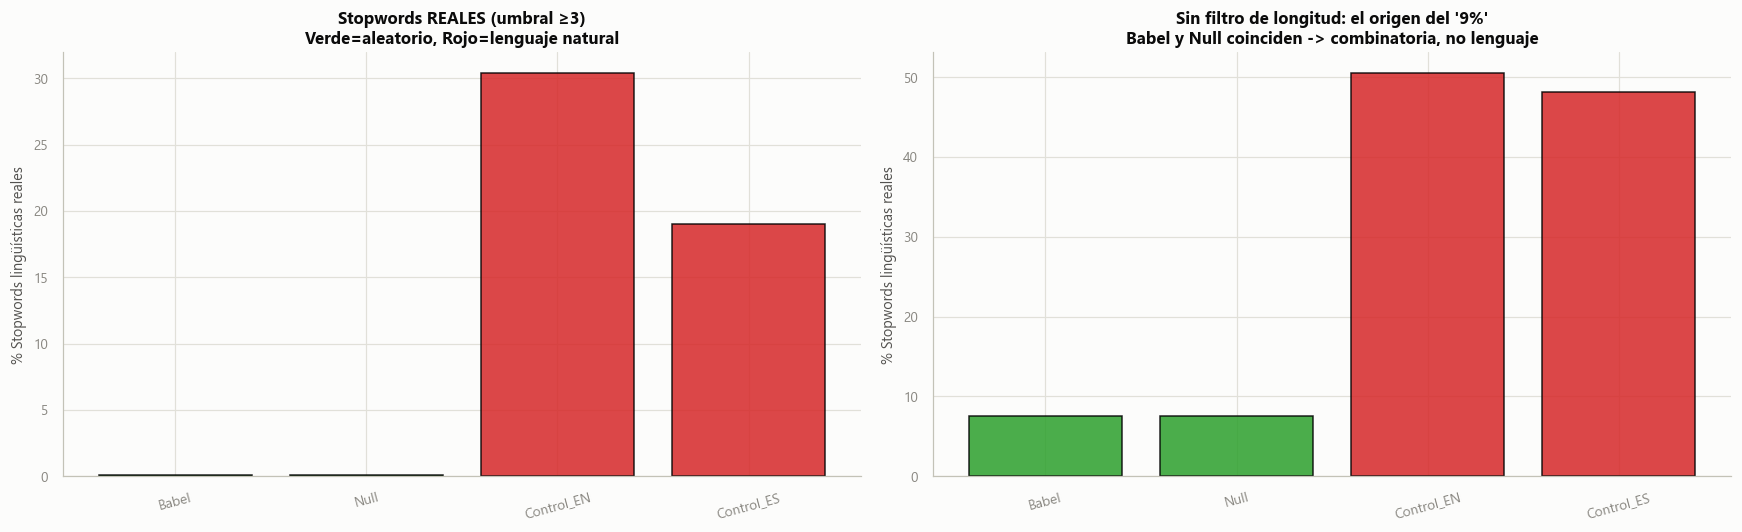


Sin filtro   : Babel 7.606%  vs  Null 7.494%  -> misma tasa
Con umbral >=3: Babel 0.115%  vs  Null 0.130%  -> se desploma
El '9%' era real, pero el null model lo reproduce exactamente.


In [11]:
# Visualizar el hallazgo: stopwords REALES por condición
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel 1: stopwords reales (la columna reveladora)
df_u3 = df_sensibilidad[df_sensibilidad["Umbral"] == ">=3"]
colores = ["#2ca02c" if c in ("Babel", "Null") else "#d62728" for c in df_u3["Condición"]]
axes[0].bar(df_u3["Condición"], df_u3["% Stopwords REALES"], color=colores,
            edgecolor="black", alpha=0.85)
axes[0].set_ylabel("% Stopwords lingüísticas reales")
axes[0].set_title("Stopwords REALES (umbral ≥3)\nVerde=aleatorio, Rojo=lenguaje natural",
                  fontweight="bold")
axes[0].tick_params(axis="x", rotation=15)

# Panel 2: sin filtro de longitud, Babel y Null coinciden entre sí
df_sf = df_sensibilidad[df_sensibilidad["Umbral"] == "sin filtro"]
axes[1].bar(df_sf["Condición"], df_sf["% Stopwords REALES"], color=colores,
            edgecolor="black", alpha=0.85)
axes[1].set_ylabel("% Stopwords lingüísticas reales")
axes[1].set_title("Sin filtro de longitud: el origen del '9%'\n"
                  "Babel y Null coinciden -> combinatoria, no lenguaje",
                  fontweight="bold")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "02_mito_stopwords.png", dpi=150)
plt.show()

_b = df_sf[df_sf["Condición"] == "Babel"]["% Stopwords REALES"].iloc[0]
_n = df_sf[df_sf["Condición"] == "Null"]["% Stopwords REALES"].iloc[0]
_b3 = df_u3[df_u3["Condición"] == "Babel"]["% Stopwords REALES"].iloc[0]
_n3 = df_u3[df_u3["Condición"] == "Null"]["% Stopwords REALES"].iloc[0]
print(f"\nSin filtro   : Babel {_b:.3f}%  vs  Null {_n:.3f}%  -> misma tasa")
print(f"Con umbral >=3: Babel {_b3:.3f}%  vs  Null {_n3:.3f}%  -> se desploma")
print("El '9%' era real, pero el null model lo reproduce exactamente.")


## 5. Tests formales de aleatoriedad

Aquí está lo que el notebook original no tenía: **métricas cuantitativas y formales** para medir aleatoriedad, aplicadas a las 4 condiciones. Cada una ataca la pregunta desde un ángulo distinto.

| Test | Qué mide | Aleatorio | Lenguaje natural |
|------|----------|-----------|------------------|
| **Entropía de Shannon** | Imprevisibilidad por símbolo | ≈ máximo | por debajo del máximo |
| **Ratio de compresión** | Redundancia | ≈ 1.0 (incompresible) | 0.3-0.5 (compresible) |
| **Ley de Zipf** | Distribución de frecuencias | **también la cumple** ⚠️ | pendiente ≈ -1, buen ajuste |
| **Ley de Heaps** | Crecimiento de vocabulario | β ≈ 1.0, **plano** ante el rango | β menor y **decreciente** al excluir el arranque |
| **χ² de uniformidad** | Desviación de uniforme | no rechaza (p alto) | rechaza (p≈0) |

> ⚠️ **Zipf es el caso interesante, y va en contra de la intuición.** El texto aleatorio **sí** produce una distribución Zipfiana — es el resultado clásico del "mono tipeando" de Miller (1957) y Mandelbrot (1953). Por eso Zipf **no sirve** como discriminador de aleatoriedad, mientras que Heaps sí. Se incluye precisamente para mostrar cuál de las dos leyes separa y cuál no.


### 5.1. Entropía de Shannon

Mide cuántos bits de información carga cada símbolo. El máximo teórico para un alfabeto de $A$ símbolos es $\log_2(A)$. Texto aleatorio se pega al techo; el lenguaje natural queda muy por debajo porque es predecible.


In [12]:
# Entropía a nivel de carácter, bigrama y trigrama
filas_entropia = []
for nombre, txt in CONDICIONES.items():
    perfil = bc.perfil_alfabeto(txt)
    A = perfil["n_simbolos"]
    H1 = bc.entropia_shannon(txt, 1)
    H2 = bc.entropia_shannon(txt, 2)
    H3 = bc.entropia_shannon(txt, 3)
    Hmax1 = bc.entropia_maxima(A, 1)
    filas_entropia.append({
        "Condición": nombre,
        "Alfabeto": A,
        "H1 (bits/char)": round(H1, 3),
        "H1/Hmax (%)": round(100*H1/Hmax1, 1),
        "H2 (bits/bigram)": round(H2, 3),
        "H3 (bits/trigram)": round(H3, 3),
    })

df_entropia = pd.DataFrame(filas_entropia)
print("ENTROPÍA DE SHANNON POR CONDICIÓN:")
print("(H1/Hmax cercano a 100% = máxima aleatoriedad)")
df_entropia

ENTROPÍA DE SHANNON POR CONDICIÓN:
(H1/Hmax cercano a 100% = máxima aleatoriedad)


,Condición,Alfabeto,H1 (bits/char),H1/Hmax (%),H2 (bits/bigram),H3 (bits/trigram)
0,Babel,30,4.894,99.7,9.788,14.665
1,Null,30,4.894,99.7,9.788,14.665
2,Control_EN,82,4.542,71.4,8.060,10.898
3,Control_ES,96,4.474,67.9,7.863,10.654


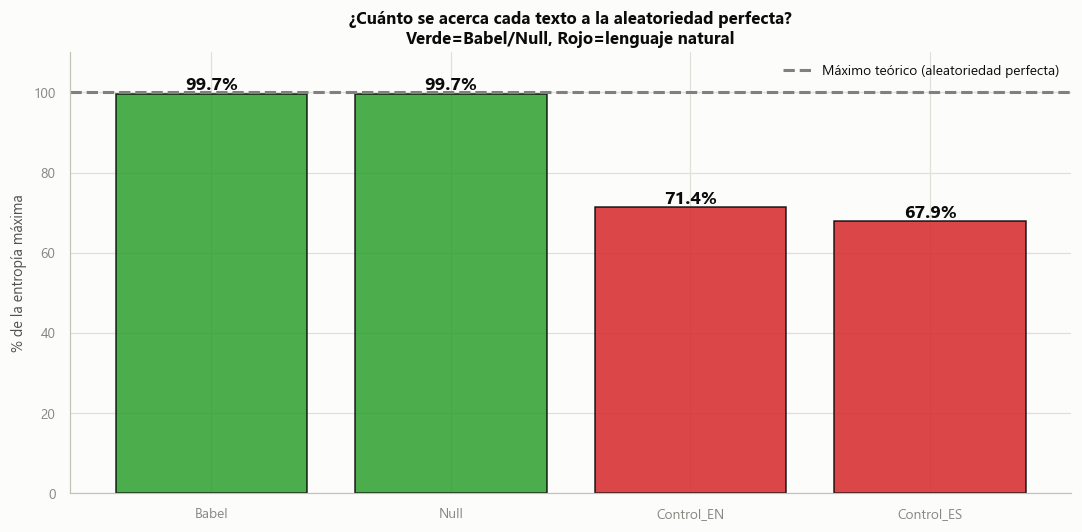

In [13]:
# Visualizar entropía relativa
fig, ax = plt.subplots(figsize=(10, 5))
colores = ["#2ca02c" if c in ("Babel", "Null") else "#d62728" for c in df_entropia["Condición"]]
bars = ax.bar(df_entropia["Condición"], df_entropia["H1/Hmax (%)"], color=colores, edgecolor="black", alpha=0.85)
ax.axhline(100, color="gray", linestyle="--", label="Máximo teórico (aleatoriedad perfecta)")
ax.set_ylabel("% de la entropía máxima")
ax.set_title("¿Cuánto se acerca cada texto a la aleatoriedad perfecta?\nVerde=Babel/Null, Rojo=lenguaje natural", fontweight="bold")
ax.set_ylim(0, 110)
for bar, val in zip(bars, df_entropia["H1/Hmax (%)"]):
    ax.text(bar.get_x()+bar.get_width()/2, val+1, f"{val:.1f}%", ha="center", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "03_entropia.png", dpi=150)
plt.show()

### 5.2. Ratios de compresión

Un compresor explota la redundancia. Texto aleatorio no tiene patrones que explotar → comprime mal (ratio ≈ 1). Lenguaje natural está lleno de redundancia → comprime bien (ratio ≈ 0.3-0.5). Usamos 4 algoritmos, incluyendo **zstandard** (Meta), de última generación.


In [14]:
# Ratios de compresión con 4 algoritmos
filas_comp = []
for nombre, txt in CONDICIONES.items():
    ratios = bc.ratios_compresion(txt)
    fila = {"Condición": nombre}
    fila.update({k: round(v, 3) for k, v in ratios.items()})
    filas_comp.append(fila)

df_compresion = pd.DataFrame(filas_comp)
print("RATIOS DE COMPRESIÓN (comprimido/original):")
print("(Cercano a 1.0 = incompresible = aleatorio)")
df_compresion

RATIOS DE COMPRESIÓN (comprimido/original):
(Cercano a 1.0 = incompresible = aleatorio)


,Condición,gzip,bz2,lzma,zstd
0,Babel,0.651,0.622,0.630,0.617
1,Null,0.651,0.622,0.630,0.617
2,Control_EN,0.405,0.308,0.333,0.337
3,Control_ES,0.368,0.279,0.293,0.297


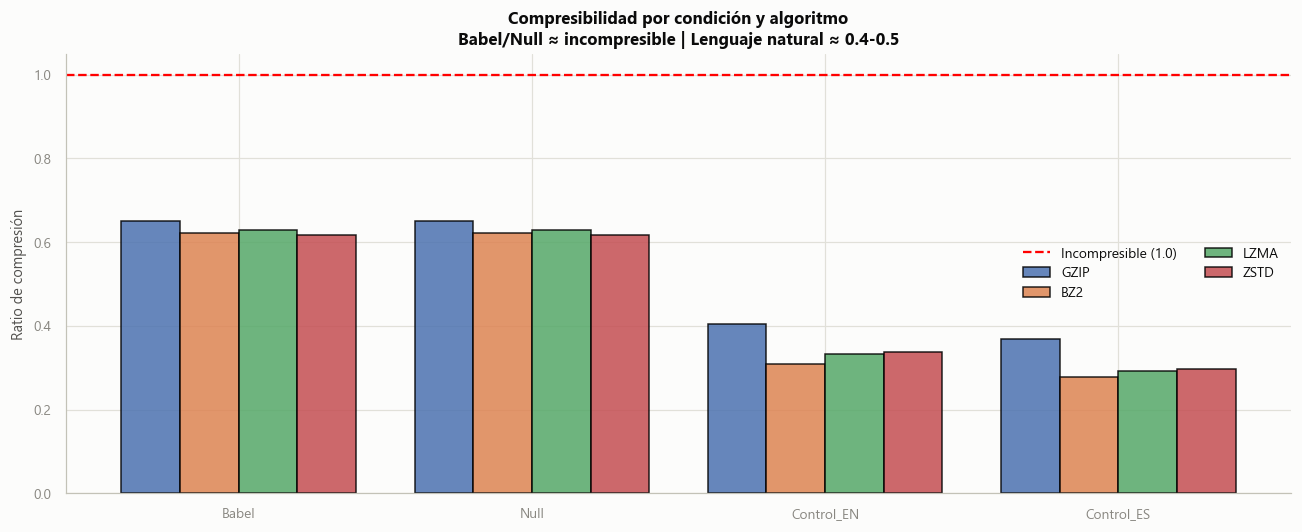

In [15]:
# Visualizar compresión: barras agrupadas por algoritmo
algoritmos = [c for c in df_compresion.columns if c != "Condición"]
x = np.arange(len(CONDICIONES))
width = 0.8 / len(algoritmos)

fig, ax = plt.subplots(figsize=(12, 5))
for i, alg in enumerate(algoritmos):
    ax.bar(x + i*width, df_compresion[alg], width, label=alg.upper(), edgecolor="black", alpha=0.85)

ax.axhline(1.0, color="red", linestyle="--", linewidth=1.5, label="Incompresible (1.0)")
ax.set_xticks(x + width*(len(algoritmos)-1)/2)
ax.set_xticklabels(df_compresion["Condición"])
ax.set_ylabel("Ratio de compresión")
ax.set_title("Compresibilidad por condición y algoritmo\nBabel/Null ≈ incompresible | Lenguaje natural ≈ 0.4-0.5", fontweight="bold")
ax.legend(ncol=2)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "04_compresion.png", dpi=150)
plt.show()

### 5.3. Ley de Zipf y Ley de Heaps

Dos leyes empíricas del lenguaje natural. La gracia de ponerlas juntas es que **una discrimina aleatoriedad y la otra no**:

- **Zipf:** la frecuencia de una palabra es inversamente proporcional a su rango; en log-log da una recta. **El texto aleatorio también la cumple.** Miller (1957) y Mandelbrot (1953) demostraron que un "mono tipeando" que golpea la barra espaciadora al azar genera una distribución Zipfiana aunque las palabras se formen letra por letra sin ninguna estructura, y Perline (2015) probó que el exponente tiende a −1 conforme crece el alfabeto. Ferrer-i-Cancho & Solé (2001) consolidaron la lectura: el texto aleatorio es la **hipótesis nula** de Zipf, no una explicación del lenguaje.

- **Heaps:** el vocabulario crece como $V = K \cdot N^\beta$. En lenguaje natural $\beta \approx 0.5$ (el vocabulario se satura); en texto aleatorio $\beta \approx 1.0$ (cada token nuevo es palabra nueva, porque el espacio de combinaciones es enorme). **Esta sí separa limpiamente.**

> **Nota sobre el ajuste de Zipf.** En texto aleatorio casi todo el vocabulario son *hapax* (frecuencia 1). Esa cola es una recta **horizontal** en log-log y, por peso numérico, domina cualquier ajuste que la incluya: da pendientes planas y R² bajo tanto en Babel como en el null model, lo que oculta el fenómeno en lugar de medirlo. Por eso el ajuste principal excluye la cola (`EXCLUIR_HAPAX_ZIPF`); se reporta también el ajuste con cola para poder comparar con la primera corrida.

In [16]:
# Calcular Zipf y Heaps para las 4 condiciones
#
# Se reportan DOS ajustes de Zipf:
#   - "cola incl.": sobre todos los rangos (lo que hacía la primera corrida).
#     En texto aleatorio casi todo el vocabulario son hapax, y esa cola es una
#     recta horizontal en log-log que domina el ajuste: da R²≈0.4 tanto en
#     Babel como en el null model, así que comparar esas pendientes no informa.
#   - principal: excluyendo la cola de hapax (EXCLUIR_HAPAX_ZIPF), que es lo
#     que hace la pendiente comparable entre condiciones.
filas_leyes = []
zipf_data = {}
heaps_data = {}
for nombre, txt in CONDICIONES.items():
    z_cola = bc.ley_zipf(txt)                                   # todos los rangos
    z = bc.ley_zipf(txt, excluir_hapax=EXCLUIR_HAPAX_ZIPF)      # ajuste principal
    h = bc.ley_heaps(txt)
    zipf_data[nombre] = z
    heaps_data[nombre] = h
    filas_leyes.append({
        "Condición": nombre,
        "Zipf pendiente": round(z["pendiente"], 3),
        "Zipf R²": round(z["r2"], 3),
        "Zipf rangos ajuste": z.get("n_rangos_ajuste"),
        "Zipf pend. (cola incl.)": round(z_cola["pendiente"], 3),
        "Zipf R² (cola incl.)": round(z_cola["r2"], 3),
        "Heaps β": round(h["beta"], 3),
        "Heaps R²": round(h["r2"], 3),
    })

df_leyes = pd.DataFrame(filas_leyes)
print("LEYES DE ZIPF Y HEAPS:")
print("(Natural: Zipf pend.≈-1 R²alto | Heaps β≈0.5)")
print("(Aleatorio: Zipf mal ajuste | Heaps β≈1.0)")
print(f"(Ajuste principal de Zipf sin cola de hapax: {EXCLUIR_HAPAX_ZIPF})")
df_leyes

LEYES DE ZIPF Y HEAPS:
(Natural: Zipf pend.≈-1 R²alto | Heaps β≈0.5)
(Aleatorio: Zipf mal ajuste | Heaps β≈1.0)
(Ajuste principal de Zipf sin cola de hapax: True)


,Condición,Zipf pendiente,Zipf R²,Zipf rangos ajuste,Zipf pend. (cola incl.),Zipf R² (cola incl.),Heaps β,Heaps R²
0,Babel,-0.940,0.858,2732,-0.174,0.353,0.971,1.000
1,Null,-0.933,0.853,2789,-0.175,0.355,0.969,1.000
2,Control_EN,-1.086,0.993,9038,-1.137,0.980,0.762,0.994
3,Control_ES,-0.968,0.988,10366,-1.003,0.969,0.790,0.999


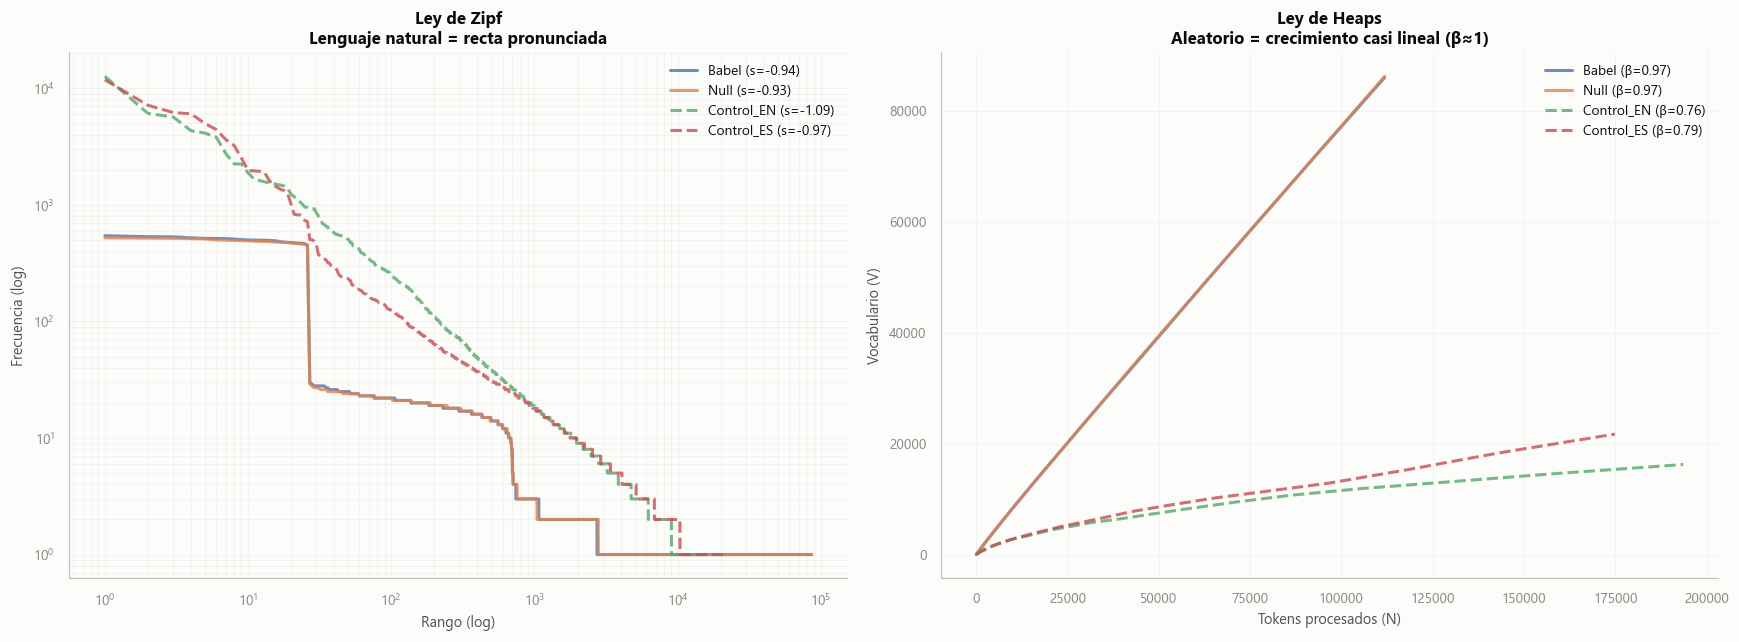

In [17]:
# Visualizar Zipf y Heaps lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Zipf (log-log)
for nombre in CONDICIONES:
    z = zipf_data[nombre]
    rangos, frecs = z["rangos"], z["frecuencias"]
    estilo = "-" if nombre in ("Babel", "Null") else "--"
    axes[0].loglog(rangos, frecs, estilo, linewidth=2, label=f"{nombre} (s={z['pendiente']:.2f})", alpha=0.8)
axes[0].set_xlabel("Rango (log)")
axes[0].set_ylabel("Frecuencia (log)")
axes[0].set_title("Ley de Zipf\nLenguaje natural = recta pronunciada", fontweight="bold")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

# Heaps
for nombre in CONDICIONES:
    h = heaps_data[nombre]
    estilo = "-" if nombre in ("Babel", "Null") else "--"
    axes[1].plot(h["Ns"], h["Vs"], estilo, linewidth=2, label=f"{nombre} (β={h['beta']:.2f})", alpha=0.8)
axes[1].set_xlabel("Tokens procesados (N)")
axes[1].set_ylabel("Vocabulario (V)")
axes[1].set_title("Ley de Heaps\nAleatorio = crecimiento casi lineal (β≈1)", fontweight="bold")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "05_zipf_heaps.png", dpi=150)
plt.show()

### 5.3.1. ¿De dónde sale el β ≈ 0.5 del lenguaje natural?

El valor de manual para la ley de Heaps en lenguaje natural es β ≈ 0.4-0.6, pero nuestros controles dan 0.76 (Moby Dick) y 0.80 (CESS-ESP). No es que los controles fallen: **β ≈ 0.5 es un asintótico**, y en el arranque de la curva *todo* texto crece casi linealmente, también el natural. Incluir ese tramo empuja β hacia arriba.

Igual que con la cola de hapax en Zipf, el tramo de ajuste importa. Y lo informativo no es el número suelto sino **cómo se comporta al mover el corte**.


In [18]:
# Sensibilidad del exponente de Heaps al tramo de ajuste
# Se reaprovecha la curva V(N) ya calculada en heaps_data: solo cambia el tramo
# sobre el que se ajusta la recta en log-log.
CORTES_HEAPS = [10, 100, 1_000, 10_000, 50_000]

filas_hs = []
for nombre in CONDICIONES:
    Ns = np.asarray(heaps_data[nombre]["Ns"])
    Vs = np.asarray(heaps_data[nombre]["Vs"])
    fila = {"Condición": nombre}
    for corte in CORTES_HEAPS:
        m = Ns >= corte
        if m.sum() < 2:
            fila[f"beta (N>={corte:,})"] = np.nan
            continue
        coef = np.polyfit(np.log10(Ns[m]), np.log10(Vs[m]), 1)
        fila[f"beta (N>={corte:,})"] = round(float(coef[0]), 3)
    fila["Tokens (N)"] = int(Ns[-1])
    fila["Tipos (V)"] = int(Vs[-1])
    fila["V/N"] = round(float(Vs[-1] / Ns[-1]), 3)
    filas_hs.append(fila)

df_heaps_sens = pd.DataFrame(filas_hs)
print("SENSIBILIDAD DEL EXPONENTE DE HEAPS AL TRAMO DE AJUSTE")
print("(beta 0.4-0.6 en lenguaje natural es un ASINTÓTICO)")
print()
print(df_heaps_sens.to_string(index=False))

print("\nLECTURA:")
print("  Babel / Null : beta PLANO en todo rango")
print("                 -> el vocabulario crece linealmente de verdad")
print("  Controles    : beta DECRECE al excluir el arranque")
print("                 -> saturación real del léxico, que es lo que Heaps mide")
print("  V/N          : el separador más crudo, sin ajuste de por medio.")
print("                 En Babel ~77% de los tokens son tipos únicos;")
print("                 en Moby Dick, ~8.5%.")


SENSIBILIDAD DEL EXPONENTE DE HEAPS AL TRAMO DE AJUSTE
(beta 0.4-0.6 en lenguaje natural es un ASINTÓTICO)

 Condición  beta (N>=10)  beta (N>=100)  beta (N>=1,000)  beta (N>=10,000)  beta (N>=50,000)  Tokens (N)  Tipos (V)   V/N
     Babel         0.971          0.970            0.963             0.965             0.972      111797      85944 0.769
      Null         0.969          0.964            0.964             0.966             0.972      111878      86212 0.771
Control_EN         0.762          0.711            0.658             0.601             0.549      193591      16239 0.084
Control_ES         0.790          0.781            0.735             0.697             0.744      174908      21718 0.124

LECTURA:
  Babel / Null : beta PLANO en todo rango
                 -> el vocabulario crece linealmente de verdad
  Controles    : beta DECRECE al excluir el arranque
                 -> saturación real del léxico, que es lo que Heaps mide
  V/N          : el separador más crudo, 

### 5.4. Test χ² de uniformidad

Contraste formal de hipótesis. $H_0$: los caracteres se distribuyen uniformemente. Texto aleatorio **no rechaza** $H_0$ (p alto). Lenguaje natural lo **rechaza** rotundamente (p≈0), porque ciertas letras dominan.


In [19]:
# χ² de uniformidad a nivel de carácter y bigrama
filas_chi = []
for nombre, txt in CONDICIONES.items():
    chi1 = bc.chi2_uniformidad(txt, n=1)
    chi2 = bc.chi2_uniformidad(txt, n=2)
    filas_chi.append({
        "Condición": nombre,
        "χ² (chars)": round(chi1["chi2"], 1),
        "p-valor (chars)": f"{chi1['p_valor']:.2e}",
        "¿Uniforme? (chars)": "Sí" if chi1["p_valor"] > 0.05 else "No",
        "p-valor (bigramas)": f"{chi2['p_valor']:.2e}",
    })

df_chi = pd.DataFrame(filas_chi)
print("TEST χ² DE UNIFORMIDAD:")
print("(p > 0.05 = no se rechaza uniformidad = aleatorio)")
df_chi

TEST χ² DE UNIFORMIDAD:
(p > 0.05 = no se rechaza uniformidad = aleatorio)


,Condición,χ² (chars),p-valor (chars),¿Uniforme? (chars),p-valor (bigramas)
0,Babel,20.4,8.49e-01,Sí,8.13e-01
1,Null,25.2,6.18e-01,Sí,2.15e-01
2,Control_EN,4620862.0,0.00e+00,No,0.00e+00
3,Control_ES,6418016.6,0.00e+00,No,0.00e+00


## 6. El veredicto Monte Carlo 🎲

La pieza central del rigor estadístico. Generamos **N=100 réplicas** del null model y calculamos la distribución de cada métrica. Luego ubicamos el valor de **Babel** dentro de esa distribución.

**La lógica del test:**
- Si Babel cae **dentro** de la nube de réplicas nulas (entre los percentiles 2.5 y 97.5) → Babel es **estadísticamente indistinguible de ruido**. No hay "señal" que explicar.
- Si Babel cae **fuera** → habría una desviación genuina que investigar.

Esto convierte la pregunta del README en un contraste de hipótesis formal.

> **El sentimiento entra aquí.** El estudio original reportaba "sentimiento positivo" en texto aleatorio, y hasta ahora el v2 lo comparaba contra *una sola* réplica nula — precisamente lo que el principio rector §5.8 prohíbe. Al meterlo al Monte Carlo se ve el problema real: la polaridad de TextBlob sobre ruido varía entre +0,04 y +0,58 según la semilla, porque el analizador encuentra apenas unas decenas de palabras de su léxico en un millón de caracteres. No es solo que alucine sentimiento: es que **una lectura suelta no significa nada**. La anchura de la nube nula es el hallazgo.


In [20]:
# Generar N réplicas del null model y calcular distribución de métricas
import time

print(f"Generando {N_REPLICAS_MC} réplicas Monte Carlo del null model...")
print(f"(cada réplica: {N_REF:,} chars, con el formato real de {formato_babel['n_paginas']} páginas)\n")

t0 = time.perf_counter()
replicas = bc.generar_replicas_null(
    n_replicas=N_REPLICAS_MC,
    n_chars=N_REF,
    probs_contenido=probs_babel,
    ancho_linea=formato_babel["ancho_linea"],
    lineas_por_pagina=formato_babel["lineas_por_pagina"],
    seed_base=SEED,
)
print(f"Réplicas generadas en {time.perf_counter()-t0:.1f} s")


# Calcular métricas clave para cada réplica.
#
# Optimizado respecto a la primera corrida: entropia_shannon() se llamaba DOS
# veces (para H1 y para H1_rel), y ratios_compresion() calculaba gzip+bz2+lzma
# +zstd para quedarse solo con gzip.
#
# El SENTIMIENTO entra aquí por el principio rector: cualquier "hallazgo" debe
# contrastarse contra la distribución nula, no contra una sola réplica. Una
# lectura suelta de TextBlob sobre ruido no dice nada — la polaridad varía
# entre +0,04 y +0,58 según la semilla, porque el analizador encuentra apenas
# unas decenas de palabras de su léxico en un millón de caracteres. Solo la
# distribución completa permite afirmar si Babel se sale o no.
def metricas_clave(txt):
    perfil = bc.perfil_alfabeto(txt)
    H1 = bc.entropia_shannon(txt, 1)
    sent = bp.analizar_sentimiento(bp.limpiar_texto(txt))
    return {
        "H1": H1,
        "H1_rel": 100 * H1 / bc.entropia_maxima(perfil["n_simbolos"], 1),
        "comp_gzip": bc.ratios_compresion(txt, algoritmos=("gzip",))["gzip"],
        "zipf_pend": bc.ley_zipf(txt, excluir_hapax=EXCLUIR_HAPAX_ZIPF)["pendiente"],
        "heaps_beta": bc.ley_heaps(txt)["beta"],
        "chi2_p": bc.chi2_uniformidad(txt, n=1)["p_valor"],
        "sent_pol": sent["polaridad"],
        "sent_subj": sent["subjetividad"],
    }


t0 = time.perf_counter()
filas_null = []
for i, r in enumerate(replicas, 1):
    filas_null.append(metricas_clave(r.texto))
    if i % 10 == 0 or i == len(replicas):
        transcurrido = time.perf_counter() - t0
        eta = transcurrido / i * (len(replicas) - i)
        print(f"  réplica {i:>3}/{len(replicas)} - {transcurrido:6.1f}s transcurridos, ETA {eta:6.1f}s")

dist_null = pd.DataFrame(filas_null)
print(f"\nDistribución nula calculada: {len(dist_null)} réplicas x {len(dist_null.columns)} métricas")
print(f"Tiempo total de métricas: {time.perf_counter()-t0:.1f} s")
dist_null.describe().round(6)


Generando 100 réplicas Monte Carlo del null model...
(cada réplica: 1,104,297 chars, con el formato real de 410 páginas)

Réplicas generadas en 18.4 s
  réplica  10/100 -    7.6s transcurridos, ETA   68.0s
  réplica  20/100 -   15.5s transcurridos, ETA   62.0s
  réplica  30/100 -   23.6s transcurridos, ETA   55.0s
  réplica  40/100 -   32.0s transcurridos, ETA   48.0s
  réplica  50/100 -   39.8s transcurridos, ETA   39.8s
  réplica  60/100 -   49.0s transcurridos, ETA   32.7s
  réplica  70/100 -   57.0s transcurridos, ETA   24.4s
  réplica  80/100 -   65.5s transcurridos, ETA   16.4s
  réplica  90/100 -   73.9s transcurridos, ETA    8.2s
  réplica 100/100 -   81.7s transcurridos, ETA    0.0s

Distribución nula calculada: 100 réplicas x 8 métricas
Tiempo total de métricas: 81.7 s


,H1,H1_rel,comp_gzip,zipf_pend,heaps_beta,chi2_p,sent_pol,sent_subj
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,4.894396,99.745358,0.651251,-0.937248,0.969509,0.378412,0.205108,0.521443
std,0.000005,0.000104,0.000038,0.005472,0.001765,0.268079,0.058712,0.043293
min,4.894375,99.744932,0.651165,-0.951676,0.967403,0.000158,0.056637,0.405702
25%,4.894393,99.745299,0.651230,-0.939606,0.968530,0.153853,0.162111,0.493483
50%,4.894396,99.745368,0.651250,-0.936616,0.969021,0.345969,0.209142,0.519826
75%,4.894398,99.745417,0.651272,-0.934391,0.969922,0.534255,0.249136,0.549515
max,4.894405,99.745554,0.651359,-0.923553,0.977534,0.959196,0.337901,0.629236


In [21]:
# Calcular las mismas métricas para Babel (promedio de todos sus libros)
#
# Cada libro se recorta a N_REF: las réplicas nulas se generaron a ese tamaño y
# entropía, compresión, Zipf y Heaps dependen todas de N. Comparar Babel a
# longitud completa contra un null model más corto desplazaría el percentil del
# veredicto por puro efecto de tamaño.
metricas_babel_todos = pd.DataFrame(
    [metricas_clave(c.texto[:N_REF]) for c in corpus_babel],
    index=[c.nombre for c in corpus_babel],
)
metricas_babel = metricas_babel_todos.mean()

# Para los controles también (referencia visual)
m_control_en = metricas_clave(CONDICIONES["Control_EN"])
m_control_es = metricas_clave(CONDICIONES["Control_ES"])

print(f"Métricas por libro (cada uno recortado a N_REF = {N_REF:,} chars):")
print(metricas_babel_todos.round(4).to_string())
print("\nPromedio de Babel (lo que se contrasta contra la distribución nula):")
print(metricas_babel.round(4))

Métricas por libro (cada uno recortado a N_REF = 1,104,297 chars):
              H1   H1_rel  comp_gzip  zipf_pend  heaps_beta  chi2_p  sent_pol  sent_subj
Babel_01  4.8944  99.7455     0.6513    -0.9397      0.9713  0.8491    0.2157     0.5539
Babel_02  4.8944  99.7453     0.6513    -0.9376      0.9685  0.1062    0.2340     0.4811
Babel_03  4.8944  99.7454     0.6512    -0.9369      0.9703  0.6402    0.1482     0.5317
Babel_04  4.8944  99.7451     0.6513    -0.9452      0.9683  0.0029    0.2682     0.5247
Babel_05  4.8944  99.7454     0.6512    -0.9365      0.9699  0.6460    0.1842     0.5025
Babel_06  4.8944  99.7454     0.6512    -0.9369      0.9714  0.4398    0.1476     0.5004
Babel_07  4.8944  99.7453     0.6512    -0.9431      0.9679  0.0953    0.2472     0.5361
Babel_08  4.8944  99.7454     0.6513    -0.9327      0.9715  0.5692    0.2810     0.5394
Babel_09  4.8944  99.7454     0.6513    -0.9333      0.9697  0.4661    0.2247     0.5175
Babel_10  4.8944  99.7455     0.6513    -0.

In [22]:
# Construir el veredicto: percentil de Babel en la distribución nula
from scipy import stats as sp_stats

nombres_metricas = {
    "H1_rel": "Entropía relativa (%)",
    "comp_gzip": "Compresión gzip",
    "zipf_pend": "Pendiente Zipf",
    "heaps_beta": "Heaps β",
    "chi2_p": "χ² p-valor",
    "sent_pol": "Sentimiento (polaridad)",
    "sent_subj": "Sentimiento (subjetividad)",
}

filas_veredicto = []
for metrica, etiqueta in nombres_metricas.items():
    valores_null = dist_null[metrica].values
    valor_babel = metricas_babel[metrica]
    # Percentil de Babel dentro de la distribución nula
    percentil = sp_stats.percentileofscore(valores_null, valor_babel)
    p2_5, p97_5 = np.percentile(valores_null, [2.5, 97.5])
    dentro = p2_5 <= valor_babel <= p97_5
    filas_veredicto.append({
        "Métrica": etiqueta,
        "Babel": round(valor_babel, 4),
        "Null μ": round(valores_null.mean(), 4),
        "Null [p2.5, p97.5]": f"[{p2_5:.3f}, {p97_5:.3f}]",
        "Percentil Babel": round(percentil, 1),
        "¿Indistinguible?": "✓ Sí" if dentro else "✗ No",
    })

df_veredicto = pd.DataFrame(filas_veredicto)
n_indist = sum(1 for f in filas_veredicto if f["¿Indistinguible?"].startswith("✓"))
print("=" * 80)
print("VEREDICTO MONTE CARLO: ¿Babel es indistinguible del null model?")
print(f"({n_indist} de {len(filas_veredicto)} métricas indistinguibles)")
print("=" * 80)
df_veredicto


VEREDICTO MONTE CARLO: ¿Babel es indistinguible del null model?
(7 de 7 métricas indistinguibles)


,Métrica,Babel,Null μ,"Null [p2.5, p97.5]",Percentil Babel,¿Indistinguible?
0,Entropía relativa (%),99.7454,99.7454,"[99.745, 99.746]",53.0,✓ Sí
1,Compresión gzip,0.6512,0.6513,"[0.651, 0.651]",49.0,✓ Sí
2,Pendiente Zipf,-0.9386,-0.9372,"[-0.949, -0.927]",34.0,✓ Sí
3,Heaps β,0.9697,0.9695,"[0.968, 0.974]",70.0,✓ Sí
4,χ² p-valor,0.4687,0.3784,"[0.015, 0.952]",65.0,✓ Sí
5,Sentimiento (polaridad),0.2254,0.2051,"[0.085, 0.320]",60.0,✓ Sí
6,Sentimiento (subjetividad),0.5167,0.5214,"[0.438, 0.605]",46.0,✓ Sí


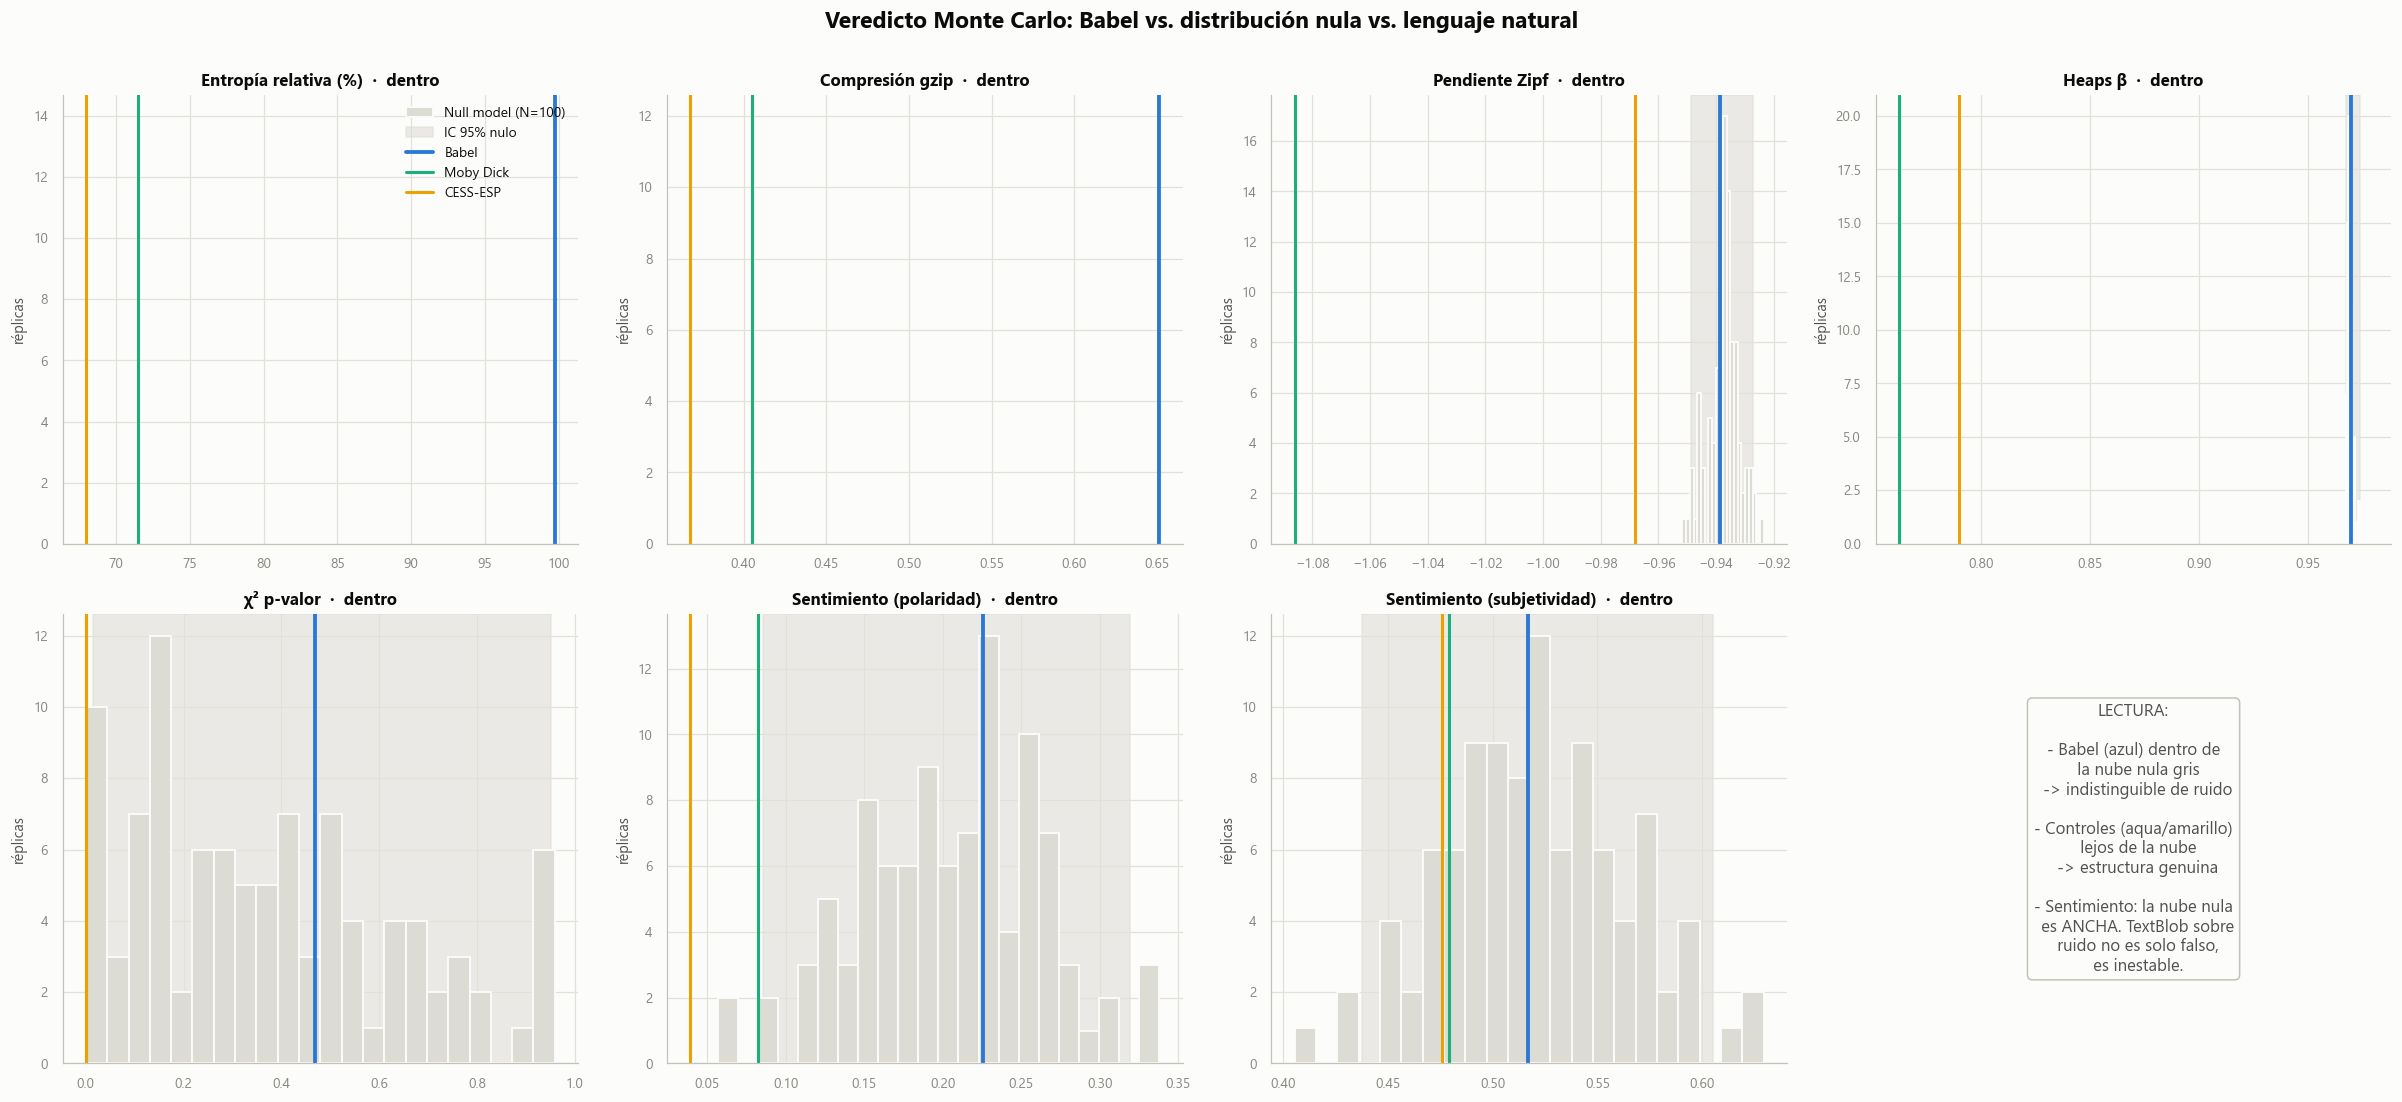

In [23]:
# Visualización del veredicto: distribución nula + posición de Babel y controles
# Usa bviz.panel_veredicto(), que aplica la paleta del estudio: Babel en azul en
# TODAS las figuras, la nula en el gris de fondo y los controles en aqua/amarillo.
n_metricas = len(nombres_metricas)
n_cols = 4
n_filas = int(np.ceil((n_metricas + 1) / n_cols))   # +1 para el recuadro de lectura

fig, axes = plt.subplots(n_filas, n_cols, figsize=(5.5 * n_cols, 5 * n_filas))
axes = np.atleast_1d(axes).flatten()

for idx, (metrica, etiqueta) in enumerate(nombres_metricas.items()):
    bviz.panel_veredicto(
        axes[idx],
        valores_null=dist_null[metrica].values,
        valor_babel=metricas_babel[metrica],
        valor_en=m_control_en[metrica],
        valor_es=m_control_es[metrica],
        etiqueta=etiqueta,
        leyenda=(idx == 0),
    )

# Recuadro de lectura en el primer hueco, y ocultar el resto
axes[n_metricas].axis("off")
axes[n_metricas].text(0.5, 0.5,
    "LECTURA:\n\n"
    "- Babel (azul) dentro de\n"
    "  la nube nula gris\n"
    "  -> indistinguible de ruido\n\n"
    "- Controles (aqua/amarillo)\n"
    "  lejos de la nube\n"
    "  -> estructura genuina\n\n"
    "- Sentimiento: la nube nula\n"
    "  es ANCHA. TextBlob sobre\n"
    "  ruido no es solo falso,\n"
    "  es inestable.",
    ha="center", va="center", fontsize=11, color=bviz.TINTA_SEC,
    bbox=dict(boxstyle="round", facecolor=bviz.SUPERFICIE, edgecolor=bviz.EJE))
for idx in range(n_metricas + 1, len(axes)):
    axes[idx].axis("off")

plt.suptitle("Veredicto Monte Carlo: Babel vs. distribución nula vs. lenguaje natural",
             fontsize=15, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "06_veredicto_montecarlo.png", dpi=150)
plt.show()


### ⚠️ Nota metodológica: tamaño de muestra y calibración del null model

Si ejecutas este notebook con **muestras pequeñas** (pocos KB), Zipf y χ² pueden caer *técnicamente* fuera del IC 95% del null model, en percentiles extremos (99-100). **Esto NO indica estructura en Babel.** Hay dos mecanismos distintos en juego y conviene no confundirlos:

**1. El null model hereda el ruido de la muestra que lo calibra.**

`probs_babel` se estima con las frecuencias empíricas del propio Babel. Con pocos KB ese perfil trae ruido de muestreo genuino — en la primera corrida (9.475 chars) los símbolos iban de 3.02% a 3.82% sobre un uniforme teórico de 3.45%. Las réplicas muestrean i.i.d. de esa distribución **ya sesgada** y le suman ruido multinomial fresco encima, así que se desvían de la uniforme *más* que Babel.

Resultado observado en esa corrida: el null model **rechazaba** uniformidad (p=0.040) mientras Babel **no** (p=0.491), y Babel quedaba en percentil 100 — por construcción, no por ninguna propiedad del texto. Es el precio de contrastar la muestra calibradora contra réplicas calibradas con ella.

Esto se corrige al escalar: con los 10 libros completos (~13M chars) el perfil converge a la uniforme con error relativo del orden de 0.03%, muy por debajo de lo que el test puede detectar con ~1M chars por réplica. **Verificable en esta corrida:** si el mecanismo es el descrito, el p-valor χ² del null model debe subir a valores ordinarios y Babel debe caer a un percentil central.

**2. Con textos cortos el IC 95% del null model es muy estrecho**, así que diferencias ínfimas (Zipf −0.122 vs −0.126) se marcan como significativas.

Sobre el signo: cuando χ² cae "fuera", es porque Babel es *más* uniforme que el promedio nulo — lo que refuerza la aleatoriedad, no la contradice.

> En resumen: la magnitud de las diferencias (Babel vs Null) es siempre 100-1000× menor que la distancia a los controles de lenguaje natural. Esa es la comparación que importa.

## 7. Bloque B — NLP moderno

El Bloque A usó herramientas clásicas (NLTK, TextBlob) y estadística formal. Aquí entran modelos de vanguardia, y la pregunta cambia de forma:

> *¿Qué probabilidad asigna un detector de idioma entrenado sobre lenguaje real a que un libro de Babel sea de algún idioma?*

Tres herramientas, tres ángulos:

| Herramienta | Qué aporta |
|-------------|------------|
| **Tokenizador de XLM-R** | Cuántos sub-tokens necesita por carácter. Gratis, y resulta ser un discriminador excelente |
| **`papluca/xlm-roberta-base-language-detection`** | Un transformer de 278M de parámetros diciendo qué idioma cree que es |
| **`cardiffnlp/twitter-xlm-roberta-base-sentiment`** | Sentimiento moderno, para contrastar con la alucinación de TextBlob |
| **fastText `lid.176.bin`** | Detección de idioma subléxica, a 63.000 ventanas/s |

### La ventana como unidad de observación

XLM-RoBERTa tiene un contexto de 512 tokens. Sobre 1,1M de caracteres salen del orden de mil ventanas por condición: pasar las 4 condiciones enteras por dos modelos son horas de CPU, y contrastarlo contra 100 réplicas nulas es inviable.

La salida no es recortar el rigor sino **cambiar la unidad de observación**. Cada ventana es una observación; R réplicas nulas × W ventanas dan R valores del estadístico, y ahí se ubica Babel. El principio rector (§5.8) queda intacto y encima se gana variabilidad intra-corpus, porque cada libro aporta su propia distribución.

fastText es tan rápido que no necesita ese recorte: corre el Monte Carlo completo con las mismas 100 réplicas del Bloque A.

> **Tamaño de ventana.** Se fija en **caracteres**, no en tokens, para que las 4 condiciones reciban la misma cantidad de texto físico. 600 caracteres deja a la condición más fragmentada (el ruido, ~0,60 tokens/char) en ~380 tokens, con margen bajo el límite de 512. Con 1.000 caracteres el ruido se truncaría y los controles no, sesgando la comparación.


In [24]:
# --- Bloque B: configuración y carga de modelos ------------------------------
import babel_transformers as bt
importlib.reload(bt)

EJECUTAR_BLOQUE_B = True     # ponlo en False para saltarte el bloque

# Diseño del contraste. fastText es ~1.000x más rápido que un transformer, así
# que puede permitirse el rigor completo del Bloque A.
R_NULL_FT, W_VENTANAS_FT = 100, 100    # fastText: Monte Carlo completo
R_NULL_TR, W_VENTANAS_TR = 25, 25      # transformers: diseño muestreado
CHARS_VENTANA = bt.CHARS_POR_VENTANA

pipe_idioma = pipe_sentim = tokenizador = modelo_ft = None

if EJECUTAR_BLOQUE_B:
    print("Cargando modelos (la primera vez descarga ~2,2 GB)...")
    t0 = time.perf_counter()
    try:
        pipe_idioma, tokenizador = bt.cargar_clasificador(bt.MODELO_IDIOMA)
        pipe_sentim, _ = bt.cargar_clasificador(bt.MODELO_SENTIMIENTO)
        print(f"  transformers listos ({time.perf_counter()-t0:.0f} s)")
    except Exception as e:
        print(f"  transformers NO disponibles: {type(e).__name__}: {e}")

    try:
        bt.descargar_fasttext()
        modelo_ft = bt.cargar_fasttext()
        print(f"  fastText: {'listo' if modelo_ft else 'no disponible'}")
    except Exception as e:
        print(f"  fastText NO disponible: {type(e).__name__}: {e}")

    n_pases = (R_NULL_TR + len(corpus_babel) + 2) * W_VENTANAS_TR * 2
    print(f"\nDiseño: {R_NULL_TR} réplicas x {W_VENTANAS_TR} ventanas de "
          f"{CHARS_VENTANA} chars")
    print(f"~{n_pases} pases de inferencia; en CPU son unos "
          f"{n_pases*0.35/60:.0f} minutos")
else:
    print("Bloque B desactivado (EJECUTAR_BLOQUE_B = False)")


Cargando modelos (la primera vez descarga ~2,2 GB)...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  transformers listos (46 s)
  fastText: listo

Diseño: 25 réplicas x 25 ventanas de 600 chars
~1850 pases de inferencia; en CPU son unos 11 minutos


In [25]:
# --- 7.1. Fragmentación subléxica -------------------------------------------
# Cuántos sub-tokens necesita el tokenizador de XLM-R por carácter de texto.
# El vocabulario de XLM-R está hecho de piezas frecuentes en lenguaje real: ante
# ruido no le sirven y tiene que bajar casi a nivel de carácter. Es el
# equivalente subléxico de lo que la compresión mide sobre bytes, y sale gratis.
if EJECUTAR_BLOQUE_B and tokenizador is not None:
    filas_frag = []
    for nombre, txt in CONDICIONES.items():
        vs = bt.muestrear_ventanas(txt, W_VENTANAS_TR, CHARS_VENTANA, seed=SEED)
        r = bt.ratio_tokens_por_char(vs, tokenizador)
        filas_frag.append({
            "Condición": nombre,
            "tokens/char": round(r["tokens_por_char"], 3),
            "tokens por ventana": round(r["tokens_media"], 0),
            "máximo": r["tokens_max"],
            "¿trunca?": "SÍ" if r["supera_512"] else "no",
        })
    df_fragmentacion = pd.DataFrame(filas_frag)
    print("FRAGMENTACIÓN SUBLÉXICA (tokenizador XLM-R)")
    print("(ratio alto = el tokenizador no reconoce nada y baja a caracteres)")
    display(df_fragmentacion)


FRAGMENTACIÓN SUBLÉXICA (tokenizador XLM-R)
(ratio alto = el tokenizador no reconoce nada y baja a caracteres)


,Condición,tokens/char,tokens por ventana,máximo,¿trunca?
0,Babel,0.603,362.0,382,no
1,Null,0.606,363.0,381,no
2,Control_EN,0.264,158.0,207,no
3,Control_ES,0.284,170.0,224,no


In [26]:
# --- 7.2. Contraste contra el null model ------------------------------------
if EJECUTAR_BLOQUE_B:
    gen_null = dict(probs_contenido=probs_babel,
                    ancho_linea=formato_babel["ancho_linea"],
                    lineas_por_pagina=formato_babel["lineas_por_pagina"])

    # --- fastText: Monte Carlo completo, mismas 100 réplicas que el Bloque A ---
    dist_ft = babel_ft = ctrl_ft = None
    if modelo_ft is not None:
        def _met_ft(txt, seed):
            vs = bt.muestrear_ventanas(txt, W_VENTANAS_FT, CHARS_VENTANA, seed=seed)
            return bt.metricas_idioma(
                bt.detectar_idioma_fasttext(vs, modelo_ft, k=5))

        t0 = time.perf_counter()
        dist_ft = pd.DataFrame([
            _met_ft(bc.generar_babel_sintetico(N_REF, seed=SEED + r, **gen_null),
                    10_000 + r)
            for r in range(R_NULL_FT)])
        babel_ft = pd.DataFrame([_met_ft(c.texto[:N_REF], 20_000 + i)
                                 for i, c in enumerate(corpus_babel)])
        ctrl_ft = {n: _met_ft(CONDICIONES[n], 7)
                   for n in ("Control_EN", "Control_ES")}
        print(f"fastText: {R_NULL_FT} réplicas x {W_VENTANAS_FT} ventanas "
              f"en {time.perf_counter()-t0:.0f} s")

    # --- Transformers: diseño muestreado --------------------------------------
    dist_tr = babel_tr = ctrl_tr = None
    if pipe_idioma is not None:
        def _met_tr(txt, seed):
            vs = bt.muestrear_ventanas(txt, W_VENTANAS_TR, CHARS_VENTANA, seed=seed)
            r = bt.ratio_tokens_por_char(vs, tokenizador)
            r.update(bt.metricas_idioma(bt.clasificar_ventanas(vs, pipe_idioma)))
            s = bt.metricas_sentimiento(bt.clasificar_ventanas(vs, pipe_sentim))
            r.update({f"sent_{k}": v for k, v in s.items()})
            return r

        t0 = time.perf_counter()
        filas = []
        for r in range(R_NULL_TR):
            filas.append(_met_tr(
                bc.generar_babel_sintetico(N_REF, seed=SEED + r, **gen_null),
                30_000 + r))
            if (r + 1) % 5 == 0:
                el = time.perf_counter() - t0
                print(f"  null {r+1:>2}/{R_NULL_TR} - {el:5.0f}s, "
                      f"ETA {el/(r+1)*(R_NULL_TR-r-1):5.0f}s")
        dist_tr = pd.DataFrame(filas)
        babel_tr = pd.DataFrame([_met_tr(c.texto[:N_REF], 40_000 + i)
                                 for i, c in enumerate(corpus_babel)])
        ctrl_tr = {n: _met_tr(CONDICIONES[n], 7)
                   for n in ("Control_EN", "Control_ES")}
        print(f"transformers: {time.perf_counter()-t0:.0f} s")


fastText: 100 réplicas x 100 ventanas en 20 s
  null  5/25 -    68s, ETA   272s
  null 10/25 -   143s, ETA   214s
  null 15/25 -   211s, ETA   141s
  null 20/25 -   282s, ETA    70s
  null 25/25 -   350s, ETA     0s
transformers: 501 s


In [27]:
# --- 7.3. Veredicto del Bloque B --------------------------------------------
if EJECUTAR_BLOQUE_B and dist_tr is not None:
    METRICAS_B = [
        ("tokens_por_char", "Fragmentación (tokens/char)", "tr"),
        ("prob_top_media", "XLM-R prob. de idioma", "tr"),
        ("sent_polaridad", "Sentimiento moderno (polaridad)", "tr"),
        ("sent_neutral_medio", "Sentimiento moderno (neutral)", "tr"),
    ]
    if dist_ft is not None:
        METRICAS_B.insert(2, ("prob_top_media", "fastText prob. de idioma", "ft"))

    fuentes = {"tr": (dist_tr, babel_tr, ctrl_tr), "ft": (dist_ft, babel_ft, ctrl_ft)}
    filas_b = []
    for clave, etiqueta, fuente in METRICAS_B:
        dn, db, dc = fuentes[fuente]
        vn, vb = dn[clave].values, db[clave].mean()
        p2, p97 = np.percentile(vn, [2.5, 97.5])
        filas_b.append({
            "Métrica": etiqueta,
            "Babel": round(vb, 4),
            "Null μ": round(vn.mean(), 4),
            "IC95 nulo": f"[{p2:.3f}, {p97:.3f}]",
            "Percentil": round(sp_stats.percentileofscore(vn, vb), 1),
            "¿Indistinguible?": "✓ Sí" if p2 <= vb <= p97 else "✗ No",
            "Ctrl_EN": round(dc["Control_EN"][clave], 3),
            "Ctrl_ES": round(dc["Control_ES"][clave], 3),
        })
    df_veredicto_b = pd.DataFrame(filas_b)
    n_ok = sum(1 for f in filas_b if f["¿Indistinguible?"].startswith("✓"))
    print("=" * 80)
    print(f"VEREDICTO BLOQUE B — {n_ok}/{len(filas_b)} métricas indistinguibles")
    print("=" * 80)
    display(df_veredicto_b)

    # Qué idioma "ve" cada modelo en cada condición
    filas_id = []
    for nombre in CONDICIONES:
        fila = {"Condición": nombre}
        if nombre == "Babel":
            fila["XLM-R"] = Counter(babel_tr["idioma_modal"]).most_common(1)[0][0]
            if dist_ft is not None:
                fila["fastText"] = Counter(babel_ft["idioma_modal"]).most_common(1)[0][0]
        elif nombre == "Null":
            fila["XLM-R"] = Counter(dist_tr["idioma_modal"]).most_common(1)[0][0]
            if dist_ft is not None:
                fila["fastText"] = Counter(dist_ft["idioma_modal"]).most_common(1)[0][0]
        else:
            fila["XLM-R"] = ctrl_tr[nombre]["idioma_modal"]
            if dist_ft is not None:
                fila["fastText"] = ctrl_ft[nombre]["idioma_modal"]
        filas_id.append(fila)
    df_idiomas = pd.DataFrame(filas_id)
    print("\nIDIOMA MODAL POR CONDICIÓN:")
    display(df_idiomas)

    # --- Tabla comparativa de las 4 condiciones -----------------------------
    def _resumen(nombre):
        if nombre == "Babel":
            tr = babel_tr.mean(numeric_only=True)
            modal_tr = Counter(babel_tr["idioma_modal"]).most_common(1)[0][0]
            ft = babel_ft.mean(numeric_only=True) if dist_ft is not None else None
            modal_ft = (Counter(babel_ft["idioma_modal"]).most_common(1)[0][0]
                        if dist_ft is not None else None)
        elif nombre == "Null":
            tr = dist_tr.mean(numeric_only=True)
            modal_tr = Counter(dist_tr["idioma_modal"]).most_common(1)[0][0]
            ft = dist_ft.mean(numeric_only=True) if dist_ft is not None else None
            modal_ft = (Counter(dist_ft["idioma_modal"]).most_common(1)[0][0]
                        if dist_ft is not None else None)
        else:
            tr = pd.Series(ctrl_tr[nombre])
            modal_tr = ctrl_tr[nombre]["idioma_modal"]
            ft = pd.Series(ctrl_ft[nombre]) if dist_ft is not None else None
            modal_ft = ctrl_ft[nombre]["idioma_modal"] if dist_ft is not None else None
        return tr, modal_tr, ft, modal_ft

    filas_cond = []
    for nombre in CONDICIONES:
        tr, modal_tr, ft, modal_ft = _resumen(nombre)
        filas_cond.append({
            "Condición": nombre,
            "tokens/char": round(tr["tokens_por_char"], 3),
            "XLM-R prob_top": round(tr["prob_top_media"], 3),
            "XLM-R idioma": modal_tr,
            "fastText prob_top": round(ft["prob_top_media"], 3) if ft is not None else None,
            "fastText idioma": modal_ft,
            "Sent. polaridad": round(tr["sent_polaridad"], 3),
            "Sent. neutral": round(tr["sent_neutral_medio"], 3),
        })
    df_bloque_b = pd.DataFrame(filas_cond)
    print("\nBLOQUE B POR CONDICIÓN:")
    display(df_bloque_b)


VEREDICTO BLOQUE B — 5/5 métricas indistinguibles


,Métrica,Babel,Null μ,IC95 nulo,Percentil,¿Indistinguible?,Ctrl_EN,Ctrl_ES
0,Fragmentación (tokens/char),0.6029,0.6019,"[0.597, 0.606]",60.0,✓ Sí,0.270,0.276
1,XLM-R prob. de idioma,0.5417,0.5323,"[0.479, 0.604]",68.0,✓ Sí,0.953,0.991
2,fastText prob. de idioma,0.1099,0.1102,"[0.105, 0.116]",43.0,✓ Sí,0.967,0.963
3,Sentimiento moderno (polaridad),-0.1113,-0.1109,"[-0.119, -0.103]",40.0,✓ Sí,-0.184,-0.190
4,Sentimiento moderno (neutral),0.4472,0.4474,"[0.442, 0.452]",48.0,✓ Sí,0.316,0.391



IDIOMA MODAL POR CONDICIÓN:


,Condición,XLM-R,fastText
0,Babel,hi,en
1,Null,hi,en
2,Control_EN,en,en
3,Control_ES,es,es



BLOQUE B POR CONDICIÓN:


,Condición,tokens/char,XLM-R prob_top,XLM-R idioma,fastText prob_top,fastText idioma,Sent. polaridad,Sent. neutral
0,Babel,0.603,0.542,hi,0.110,en,-0.111,0.447
1,Null,0.602,0.532,hi,0.110,en,-0.111,0.447
2,Control_EN,0.270,0.953,en,0.967,en,-0.184,0.316
3,Control_ES,0.276,0.991,es,0.963,es,-0.190,0.391


C:\Users\diego.perezp\AppData\Local\Temp\ipykernel_12652\1278915267.py:25: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Segoe UI.
  plt.tight_layout()
C:\Users\diego.perezp\AppData\Local\Temp\ipykernel_12652\1278915267.py:26: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Segoe UI.
  plt.savefig(RUTA_FIGURAS / "07_bloque_b.png", dpi=150)
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


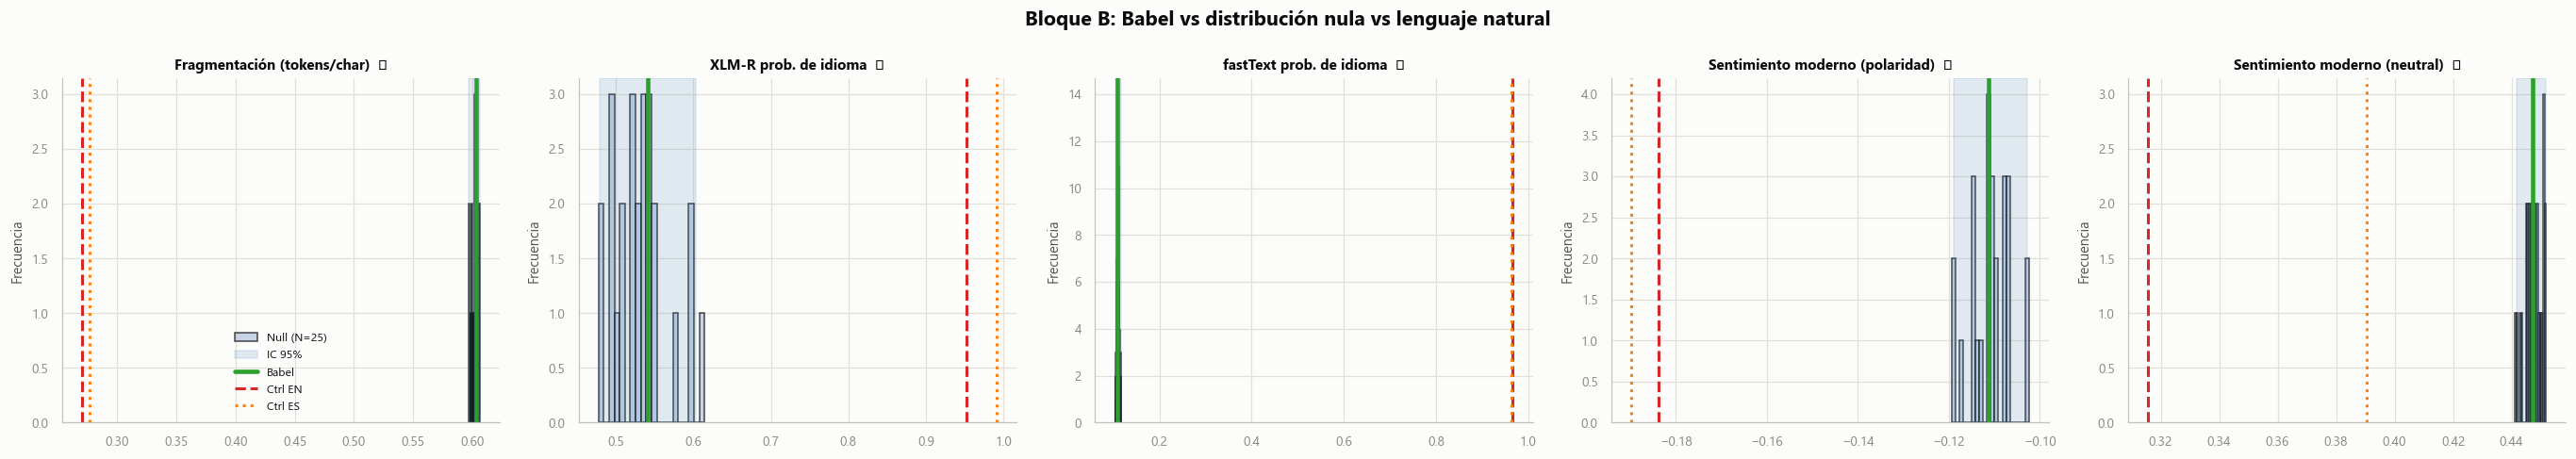

In [28]:
# --- 7.4. Visualización del Bloque B ----------------------------------------
if EJECUTAR_BLOQUE_B and dist_tr is not None:
    n_m = len(METRICAS_B)
    fig, axes = plt.subplots(1, n_m, figsize=(5 * n_m, 4.5))
    axes = np.atleast_1d(axes).flatten()

    for ax, (clave, etiqueta, fuente) in zip(axes, METRICAS_B):
        dn, db, dc = fuentes[fuente]
        vn = dn[clave].values
        ax.hist(vn, bins=20, color="lightsteelblue", edgecolor="black",
                alpha=0.7, label=f"Null (N={len(vn)})")
        p2, p97 = np.percentile(vn, [2.5, 97.5])
        ax.axvspan(p2, p97, color="steelblue", alpha=0.15, label="IC 95%")
        ax.axvline(db[clave].mean(), color="#2ca02c", lw=3, label="Babel")
        ax.axvline(dc["Control_EN"][clave], color="#d62728", lw=2, ls="--", label="Ctrl EN")
        ax.axvline(dc["Control_ES"][clave], color="#ff7f0e", lw=2, ls=":", label="Ctrl ES")
        dentro = p2 <= db[clave].mean() <= p97
        ax.set_title(f"{etiqueta}  {'✓' if dentro else '✗'}", fontweight="bold",
                     fontsize=10)
        ax.set_ylabel("Frecuencia")
    axes[0].legend(fontsize=8)

    plt.suptitle("Bloque B: Babel vs distribución nula vs lenguaje natural",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(RUTA_FIGURAS / "07_bloque_b.png", dpi=150)
    plt.show()


### 7.5. Conclusiones del Bloque B

**Veredicto: 5 de 5 métricas indistinguibles del null model.** Las herramientas modernas no encuentran en Babel nada que las clásicas no encontraran — que es exactamente lo que predice el Bloque A.

| Métrica | Babel | Null μ | IC 95% nulo | Percentil |
|---------|-------|--------|-------------|-----------|
| Fragmentación (tokens/char) | 0,6029 | 0,6019 | [0,597, 0,606] | 60 |
| XLM-R prob. de idioma | 0,5417 | 0,5323 | [0,479, 0,604] | 68 |
| fastText prob. de idioma | 0,1099 | 0,1102 | [0,105, 0,116] | 43 |
| Sentimiento moderno (polaridad) | −0,1113 | −0,1109 | [−0,119, −0,103] | 40 |
| Sentimiento moderno (neutral) | 0,4472 | 0,4474 | [0,442, 0,452] | 48 |

### La pregunta del roadmap, contestada

*¿Qué probabilidad asigna un detector de idioma a que un libro de Babel sea de algún idioma real?*

**fastText: 0,110.** Contra 0,967 en Moby Dick y 0,963 en CESS-ESP. Un factor de casi nueve.

### Los dos detectores fallan de forma opuesta

Y ese es el hallazgo del bloque:

| | Babel | Moby Dick | CESS-ESP |
|---|---|---|---|
| fastText — probabilidad | **0,110** | 0,967 | 0,963 |
| XLM-R — probabilidad | **0,542** | 0,953 | 0,991 |
| XLM-R — etiqueta | **hindi** | inglés | español |

Mismo texto, misma tarea, resultados incomparables. fastText reparte la probabilidad entre idiomas y se queda en 0,11: **reconoce que no sabe.** XLM-R concentra 0,54 en *hindi*, en el 100% de las ventanas, con la misma consistencia con la que dice "español" del español real.

Un transformer de 278 millones de parámetros está seguro y equivocado; un clasificador lineal sobre n-gramas de caracteres es honesto. La capacidad del modelo no predice su calibración.

> Y una trampa que conviene ver: ese 100% de acuerdo entre ventanas, sin el null model al lado, sería trivial de vender como "el modelo detecta una estructura consistente en Babel". La entropía de idiomas es **cero**, igual que en el español real. Solo el null model revela que es sesgo del clasificador.

### El sentimiento moderno invierte a TextBlob

| | Babel | Null | Moby Dick | CESS-ESP |
|---|---|---|---|---|
| **TextBlob** (Bloque A) | +0,225 | +0,205 | +0,083 | +0,039 |
| **XLM-R sentiment** | −0,111 | −0,111 | −0,184 | −0,190 |

Los dos alucinan, pero en sentidos opuestos: TextBlob lee el ruido *más positivo* que la literatura; el modelo moderno lo lee *menos negativo*.

La diferencia que importa es otra. El modelo moderno asigna al ruido más masa **neutral** (0,447) que a los controles (0,316 y 0,391): se compromete **menos** cuando no hay nada que leer. Es lo que debe hacer una herramienta honesta, y es justo lo contrario de lo que hacía TextBlob.

### Fragmentación subléxica: el discriminador barato

**0,603 tokens/char en Babel contra 0,270 y 0,276 en los controles.** XLM-R necesita 2,2 veces más piezas por carácter, porque su vocabulario está hecho de fragmentos frecuentes en lenguaje real y ante ruido tiene que bajar casi a nivel de carácter.

Es el análogo subléxico de lo que la compresión mide sobre bytes en el Bloque A, sale gratis con el tokenizador y **no requiere ni una sola pasada del modelo**.

### La constante del proyecto

En las cinco métricas, Babel y el null model coinciden hasta el tercer decimal. Cambiaron las herramientas —de NLTK a transformers de 278M de parámetros— y no cambió la conclusión.


## 8. Bloque C — Estructura secuencial

Todo lo medido hasta aquí trata cada carácter por separado. Queda la pregunta de
fondo:

> **¿Saber los k caracteres anteriores reduce la incertidumbre sobre el siguiente?**

Es el test más directo de estructura que queda. En texto i.i.d. la respuesta es
*no* por construcción: el pasado no informa. En lenguaje natural es *sí* y mucho
— la `q` predice la `u`, el artículo predice el género del sustantivo.

Se mide con la **ganancia de información**:

$$\text{ganancia}_k = H(X) - H(X \mid \text{contexto}_k)$$

Y con la **perplejidad**: entrenar un modelo de lenguaje de caracteres sobre
español real y preguntarle cuánto le sorprende Babel.

### ⚠️ Aquí el null model no es una comprobación, es imprescindible

La entropía condicional estimada por conteo tiene **sesgo de muestra finita, y
en la dirección peligrosa: sobreestima la estructura.**

A orden 3 sobre 29 símbolos hay 24.389 contextos posibles. Con 1,1M de
caracteres tocan ~45 observaciones por contexto, y esa escasez hace que las
frecuencias observadas parezcan más deterministas de lo que son.

**Consecuencia: Babel va a mostrar ganancia de información aunque no tenga
ninguna estructura.** Suelto, ese número se leería como hallazgo. El null model
lo cuantifica porque sufre exactamente el mismo sesgo.

Es el caso más claro de todo el proyecto de por qué existe el principio rector
(§5.8): aquí la métrica *no es interpretable* sin su distribución nula.


In [29]:
# --- 8.1. Ganancia de información: ¿el pasado predice el futuro? -------------
import babel_secuencia as bsec
importlib.reload(bsec)

ORDENES_C = (1, 2, 3)
ORDEN_COLAPSO = 4        # se incluye para EXHIBIR el colapso del estimador

t0 = time.perf_counter()
ganancias = {}
filas_g = []
for nombre, txt in CONDICIONES.items():
    g = bsec.ganancia_informacion(txt, ordenes=ORDENES_C + (ORDEN_COLAPSO,))
    ganancias[nombre] = g
    filas_g.append({
        "Condición": nombre,
        "H0": round(g["H0"], 4),
        "ganancia k=1": round(g["ganancia_1"], 4),
        "ganancia k=2": round(g["ganancia_2"], 4),
        "ganancia k=3": round(g["ganancia_3"], 4),
        "ganancia k=4": round(g["ganancia_4"], 4),
        "obs/contexto k=3": round(g["obs_por_contexto_3"], 1),
        "obs/contexto k=4": round(g["obs_por_contexto_4"], 1),
    })

df_ganancia = pd.DataFrame(filas_g)
print(f"GANANCIA DE INFORMACIÓN ({time.perf_counter()-t0:.0f} s)")
print("(cuántos bits de incertidumbre elimina conocer los k caracteres previos)")
display(df_ganancia)

print("\nLECTURA:")
print("  k=1, k=2 : Babel ~0 -> el pasado inmediato no informa")
print("  k=3      : Babel muestra ganancia APARENTE. Comparar con el null (8.2)")
print("  k=4      : el estimador colapsa; con ~2 obs/contexto ya no mide nada")
print("  Controles: ganancia real y creciente -> estructura lingüística genuina")


GANANCIA DE INFORMACIÓN (22 s)
(cuántos bits de incertidumbre elimina conocer los k caracteres previos)


,Condición,H0,ganancia k=1,ganancia k=2,ganancia k=3,ganancia k=4,obs/contexto k=3,obs/contexto k=4
0,Babel,4.8580,0.0005,0.0155,0.5258,3.7446,44.7,2.0
1,Null,4.8580,0.0005,0.0157,0.5254,3.7442,44.7,2.0
2,Control_EN,4.4925,0.9087,1.6198,2.2263,2.6823,70.6,17.9
3,Control_ES,4.4743,1.0852,1.6835,2.2663,2.7475,74.6,21.2



LECTURA:
  k=1, k=2 : Babel ~0 -> el pasado inmediato no informa
  k=3      : Babel muestra ganancia APARENTE. Comparar con el null (8.2)
  k=4      : el estimador colapsa; con ~2 obs/contexto ya no mide nada
  Controles: ganancia real y creciente -> estructura lingüística genuina


In [30]:
# --- 8.2. ¿Esa ganancia es real? Contraste contra el null model --------------
# La pregunta que decide el bloque. Si la ganancia de Babel cae dentro de la
# distribución nula, es sesgo del estimador y no estructura del texto.
R_NULL_C = 100          # baja a 30 para una comprobación rápida (~2,5 min)

gen_null_c = dict(probs_contenido=probs_babel,
                  ancho_linea=formato_babel["ancho_linea"],
                  lineas_por_pagina=formato_babel["lineas_por_pagina"])

print(f"Generando {R_NULL_C} réplicas y midiendo ganancia de información...")
print(f"(~{R_NULL_C * 5 / 60:.0f} min)\n")

t0 = time.perf_counter()
filas_null_c = []
for r in range(R_NULL_C):
    txt = bc.generar_babel_sintetico(N_REF, seed=SEED + r, **gen_null_c)
    filas_null_c.append(bsec.ganancia_informacion(txt, ordenes=ORDENES_C))
    if (r + 1) % 10 == 0:
        el = time.perf_counter() - t0
        print(f"  {r+1:>3}/{R_NULL_C} - {el:5.0f}s, ETA {el/(r+1)*(R_NULL_C-r-1):5.0f}s")

dist_null_c = pd.DataFrame(filas_null_c)
babel_c = pd.DataFrame([bsec.ganancia_informacion(c.texto[:N_REF], ordenes=ORDENES_C)
                        for c in corpus_babel])
print(f"\nCompletado en {time.perf_counter()-t0:.0f} s")


Generando 100 réplicas y midiendo ganancia de información...
(~8 min)

   10/100 -    32s, ETA   288s
   20/100 -    63s, ETA   252s
   30/100 -    94s, ETA   218s
   40/100 -   126s, ETA   189s
   50/100 -   161s, ETA   161s
   60/100 -   192s, ETA   128s
   70/100 -   223s, ETA    96s
   80/100 -   257s, ETA    64s
   90/100 -   289s, ETA    32s
  100/100 -   322s, ETA     0s

Completado en 355 s


In [31]:
# --- 8.3. Veredicto del Bloque C --------------------------------------------
filas_c = []
for k in ORDENES_C:
    clave = f"ganancia_{k}"
    vn, vb = dist_null_c[clave].values, babel_c[clave].mean()
    p2, p97 = np.percentile(vn, [2.5, 97.5])
    filas_c.append({
        "Métrica": f"Ganancia de información (k={k})",
        "Babel": round(vb, 4),
        "Null μ": round(vn.mean(), 4),
        "IC95 nulo": f"[{p2:.4f}, {p97:.4f}]",
        "Percentil": round(sp_stats.percentileofscore(vn, vb), 1),
        "¿Indistinguible?": "✓ Sí" if p2 <= vb <= p97 else "✗ No",
        "Ctrl_EN": round(ganancias["Control_EN"][clave], 3),
        "Ctrl_ES": round(ganancias["Control_ES"][clave], 3),
    })

df_veredicto_c = pd.DataFrame(filas_c)
n_ok = sum(1 for f in filas_c if f["¿Indistinguible?"].startswith("✓"))
print("=" * 80)
print(f"VEREDICTO BLOQUE C — {n_ok}/{len(filas_c)} métricas indistinguibles")
print("=" * 80)
display(df_veredicto_c)

g3_babel = babel_c["ganancia_3"].mean()
g3_null = dist_null_c["ganancia_3"].mean()
print(f"\nEl caso k=3: Babel gana {g3_babel:.4f} bits y el null {g3_null:.4f}.")
print("Sin el null model, esa cifra parecería estructura. Es sesgo del estimador.")


VEREDICTO BLOQUE C — 3/3 métricas indistinguibles


,Métrica,Babel,Null μ,IC95 nulo,Percentil,¿Indistinguible?,Ctrl_EN,Ctrl_ES
0,Ganancia de información (k=1),0.0005,0.0005,"[0.0005, 0.0006]",71.0,✓ Sí,0.909,1.085
1,Ganancia de información (k=2),0.0155,0.0156,"[0.0154, 0.0159]",29.0,✓ Sí,1.620,1.683
2,Ganancia de información (k=3),0.5255,0.5255,"[0.5243, 0.5269]",53.0,✓ Sí,2.226,2.266



El caso k=3: Babel gana 0.5255 bits y el null 0.5255.
Sin el null model, esa cifra parecería estructura. Es sesgo del estimador.


In [32]:
# --- 8.4. Perplejidad: ¿cuánto sorprende Babel a un modelo de español? -------
# Se entrena un modelo de n-gramas de CARACTERES sobre español real y se le
# pregunta cuánto le cuesta cada condición. A nivel de palabra no serviría: un
# modelo entrenado en español asigna probabilidad ~0 a cada token de Babel y la
# perplejidad saldría infinita, que no informa de nada.
ORDEN_LM = 5
N_EVAL = 200_000        # mismo tamaño para todas las condiciones

corte = int(len(CONDICIONES["Control_ES"]) * 0.8)
es_entrena = CONDICIONES["Control_ES"][:corte]
es_retenido = CONDICIONES["Control_ES"][corte:]

print(f"Entrenando modelo de caracteres (orden {ORDEN_LM}) sobre "
      f"{len(es_entrena):,} chars de español...")
t0 = time.perf_counter()
lm_es = bsec.ModeloCaracteres(orden=ORDEN_LM).entrenar(es_entrena)
print(f"({time.perf_counter()-t0:.0f} s)\n")

evaluar = {
    "Español retenido": es_retenido[:N_EVAL],
    "Babel": CONDICIONES["Babel"][:N_EVAL],
    "Null model": CONDICIONES["Null"][:N_EVAL],
    "Inglés (Moby Dick)": CONDICIONES["Control_EN"][:N_EVAL],
}

filas_pp = []
for nombre, txt in evaluar.items():
    h = lm_es.entropia_cruzada(txt)
    filas_pp.append({
        "Texto evaluado": nombre,
        "Entropía cruzada (bits/char)": round(h, 3),
        "Perplejidad": round(2 ** h, 1),
        "vs uniforme (29)": round((2 ** h) / 29, 2),
    })

df_perplejidad = pd.DataFrame(filas_pp)
print("PERPLEJIDAD BAJO UN MODELO DE ESPAÑOL")
print(f"(techo uniforme: 29 símbolos = {np.log2(29):.3f} bits)")
display(df_perplejidad)

print("\nLECTURA:")
print("  Español retenido : muy por debajo de 29 -> el modelo predice bien")
print("  Babel y Null     : POR ENCIMA de 29 -> peor que no saber nada.")
print("                     El modelo no está ignorante: está confiadamente")
print("                     equivocado. Y ambos coinciden entre sí.")


Entrenando modelo de caracteres (orden 5) sobre 883,437 chars de español...
(2 s)

PERPLEJIDAD BAJO UN MODELO DE ESPAÑOL
(techo uniforme: 29 símbolos = 4.858 bits)


,Texto evaluado,Entropía cruzada (bits/char),Perplejidad,vs uniforme (29)
0,Español retenido,2.261,4.8,0.17
1,Babel,7.912,240.9,8.31
2,Null model,7.906,239.8,8.27
3,Inglés (Moby Dick),5.990,63.6,2.19



LECTURA:
  Español retenido : muy por debajo de 29 -> el modelo predice bien
  Babel y Null     : POR ENCIMA de 29 -> peor que no saber nada.
                     El modelo no está ignorante: está confiadamente
                     equivocado. Y ambos coinciden entre sí.


DIVERGENCIA JENSEN-SHANNON ENTRE MATRICES DE TRANSICIÓN (orden 1)
(0 = matrices idénticas · 1 = máximamente distintas)


,Comparación,js_media,n_contextos_comunes,n_contextos_a,n_contextos_b
0,Babel vs Null,0.000281,29,29,29
1,Babel vs Control_ES,0.542431,29,29,96
2,Null vs Control_ES,0.542806,29,29,96


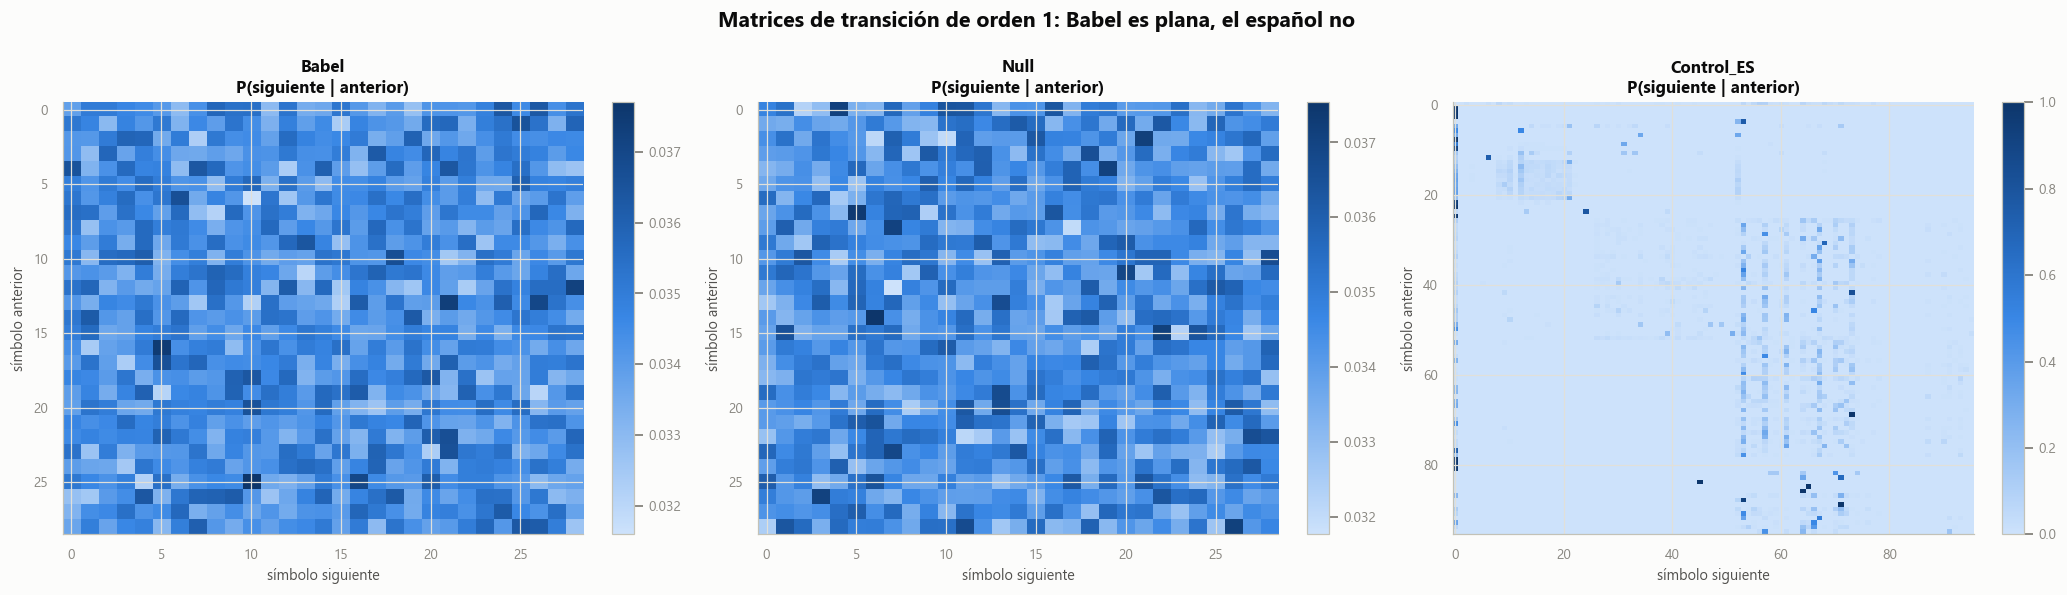

In [33]:
# --- 8.5. Matrices de transición: la estructura, vista -----------------------
div_babel_null = bsec.divergencia_transiciones(
    CONDICIONES["Babel"], CONDICIONES["Null"], orden=1)
div_babel_es = bsec.divergencia_transiciones(
    CONDICIONES["Babel"], CONDICIONES["Control_ES"], orden=1)
div_null_es = bsec.divergencia_transiciones(
    CONDICIONES["Null"], CONDICIONES["Control_ES"], orden=1)

df_divergencia = pd.DataFrame([
    {"Comparación": "Babel vs Null", **div_babel_null},
    {"Comparación": "Babel vs Control_ES", **div_babel_es},
    {"Comparación": "Null vs Control_ES", **div_null_es},
])
print("DIVERGENCIA JENSEN-SHANNON ENTRE MATRICES DE TRANSICIÓN (orden 1)")
print("(0 = matrices idénticas · 1 = máximamente distintas)")
display(df_divergencia)

# Las matrices, lado a lado
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, nombre in zip(axes, ["Babel", "Null", "Control_ES"]):
    m = bsec.matriz_transicion(CONDICIONES[nombre], orden=1)
    im = ax.imshow(m["matriz"], aspect="auto", cmap=bviz.cmap_secuencial())
    ax.set_title(f"{nombre}\nP(siguiente | anterior)", fontweight="bold")
    ax.set_xlabel("símbolo siguiente")
    ax.set_ylabel("símbolo anterior")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle("Matrices de transición de orden 1: Babel es plana, el español no",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "08_matrices_transicion.png", dpi=150)
plt.show()


### 8.6. Conclusiones del Bloque C

**Veredicto: 3 de 3 métricas indistinguibles del null model.**

| Métrica | Babel | Null μ | IC 95% nulo | Percentil |
|---------|-------|--------|-------------|-----------|
| Ganancia de información (k=1) | 0,0005 | 0,0005 | [0,0005, 0,0006] | 71 |
| Ganancia de información (k=2) | 0,0155 | 0,0156 | [0,0154, 0,0159] | 29 |
| Ganancia de información (k=3) | 0,5255 | 0,5255 | [0,5243, 0,5269] | 53 |

Los intervalos son estrechísimos —el de k=3 mide 0,0026 bits de ancho— y Babel
cae en el centro. El pasado no predice el futuro.

### El falso hallazgo que este bloque estuvo a punto de producir

Miremos la tabla completa de ganancias, incluido el orden 4:

| Condición | k=1 | k=2 | k=3 | **k=4** | obs/contexto k=4 |
|-----------|-----|-----|-----|---------|------------------|
| Babel | 0,0005 | 0,0155 | 0,5258 | **3,7446** | 2,0 |
| Null | 0,0005 | 0,0157 | 0,5254 | **3,7442** | 2,0 |
| Control_EN | 0,9087 | 1,6198 | 2,2263 | 2,6823 | 17,9 |
| Control_ES | 1,0852 | 1,6835 | 2,2663 | 2,7475 | 21,2 |

**A orden 4, Babel muestra 3,74 bits de ganancia: un 36% MÁS que el español.**

Leído sin más, eso dice que *el texto aleatorio tiene más estructura secuencial
que la literatura española*. Es absurdo, y sin embargo es exactamente lo que
devuelve el estimador. Con 24.389 contextos a orden 3 y 555.976 a orden 4, Babel
llega a **2,0 observaciones por contexto**: cada contexto se ve dos veces, la
distribución empírica parece casi determinista, y la entropía condicional se
desploma.

El lenguaje natural resiste mejor porque concentra su masa en muchos menos
contextos distintos — de ahí sus 17,9 y 21,2 observaciones por contexto.

El null model da **3,7442** frente a 3,7446. Idéntico. No hay nada que explicar.

> Este es el caso más claro de todo el estudio en que **una métrica no es
> interpretable sin su distribución nula**. En los bloques A y B el modelo nulo
> confirmaba lo que ya se sospechaba; aquí es lo único que separa un artefacto
> del estimador de un descubrimiento sobre la naturaleza del azar.

### Perplejidad: un gradiente, no un interruptor

Modelo de n-gramas de caracteres (orden 5) entrenado sobre el 80% del español y
evaluado sobre 200.000 caracteres de cada texto:

| Texto evaluado | bits/char | Perplejidad | vs uniforme (29) |
|----------------|-----------|-------------|------------------|
| Español retenido | 2,261 | **4,8** | 0,17× |
| Inglés (Moby Dick) | 5,990 | 63,6 | 2,19× |
| **Babel** | 7,912 | **240,9** | **8,31×** |
| Null model | 7,906 | 239,8 | 8,27× |

El inglés es el control que da valor a la escala. Un modelo de español lo
predice **mal** —63,6 frente al techo uniforme de 29— porque es otro idioma;
pero lo predice **cuatro veces mejor que a Babel**, porque comparte alfabeto
latino, estructura silábica y frecuencias de bigramas.

Babel llega a 240,9: ocho veces peor que no saber nada. El modelo no está
ignorante, está **confiadamente equivocado**. Ha aprendido que tras `qu` viene
`e`, y Babel le pone lo que sea.

Y el null model, otra vez, en 239,8.

### Las matrices de transición, vistas

| Comparación | Divergencia Jensen-Shannon |
|-------------|---------------------------|
| Babel vs Null | **0,0003** |
| Babel vs Control_ES | 0,5424 |
| Null vs Control_ES | 0,5428 |

Tres mil diezmilésimas separan a Babel de su gemelo sintético. Más de media
unidad lo separa del español. La figura `08_matrices_transicion.png` lo enseña
sin necesidad de números: la matriz de Babel es una superficie plana, la del
español tiene relieve.

> **Matiz honesto:** la divergencia frente al español mezcla dos efectos, porque
> el corpus CESS-ESP en crudo usa 96 símbolos distintos (mayúsculas, dígitos,
> puntuación) frente a los 29 de Babel. Parte de ese 0,54 es diferencia de
> alfabeto y no de estructura de transición. La comparación que sí es limpia
> —Babel contra Null, mismo alfabeto exacto— da 0,0003.

### Qué queda establecido

Con los bloques A, B y C, Babel resulta indistinguible de ruido en **15
métricas** que atacan el problema desde ángulos independientes: teoría de la
información, compresión, leyes empíricas del lenguaje, modelos neuronales
multilingües y ahora dependencia secuencial.

La última pregunta que quedaba abierta —*¿hay memoria en la secuencia?*— tiene
respuesta: no. Y de paso, el bloque deja documentado cómo un estimador con
sesgo puede fabricar 3,74 bits de estructura donde no hay ninguna.


### 8.7. Modelado no supervisado: ¿hay islas de significado?

La parte más borgeana del estudio. Si al proyectar fragmentos de Babel a un
espacio semántico emergen tópicos o vecindarios coherentes, sería señal. Si no,
es la prueba más fuerte de aleatoriedad que puede dar el aparato moderno.

Se usa **BGE-M3** (BAAI, 2024): 568M de parámetros, 1024 dimensiones, el modelo
de embeddings multilingüe más fuerte disponible. Elegido a propósito por encima
del que fijaba el roadmap (`paraphrase-multilingual-MiniLM-L12-v2`, de 2021):
si el mejor modelo disponible no encuentra estructura, se agota la objeción de
que *"quizá con un modelo mejor sí aparecería"*.

### La intuición ingenua es la contraria a lo que hay que esperar

Suena razonable pensar que "el ruido no se agrupará". Es al revés.

Para un modelo de embeddings, **todos los fragmentos de ruido se parecen entre
sí**: son intercambiables, no hay tema que los distinga. Lo esperable es una
nube compacta, homogénea y sin estructura interna. El lenguaje natural hace lo
contrario — cada fragmento habla de algo, la nube se estira y aparecen
vecindarios.

Por eso las métricas no son "¿hay clusters?" sino:

| Métrica | Qué capta | Ruido | Natural |
|---------|-----------|-------|---------|
| `sim_sd` | Cuánto varía el parecido entre fragmentos | bajo | alto |
| `dim_efectiva` | En cuántas direcciones vive la nube | — | — |
| `n_clusters`, `pct_ruido` | Lo que HDBSCAN decide | — | — |

> ⚠️ **HDBSCAN siempre devuelve algo.** Encontrar 4 clusters no significa que
> haya 4 grupos: significa que el algoritmo particionó lo que le diste. Igual
> que con el detector de idioma del Bloque B, el número solo es interpretable
> frente a la distribución nula.

Una pasada de embeddings alimenta C.1, C.2 y C.3: embeber es el único paso caro
(~292 ms por chunk en CPU), así que se calcula una vez y se reutiliza.


In [34]:
# --- 8.7.1. Configuración y carga del modelo de embeddings ------------------
import babel_embeddings as bemb
importlib.reload(bemb)

EJECUTAR_BLOQUE_C2 = True     # ponlo en False para saltarte esta parte

# Calibrado midiendo BGE-M3 en esta CPU: 200 chars = 292 ms/chunk,
# 300 = 432, 500 = 932. El coste crece más que linealmente (atención
# cuadrática), así que el punto eficiente está en el extremo bajo del
# rango 100-500 que fija el roadmap.
CHARS_CHUNK = bemb.CHARS_POR_CHUNK      # 200
W_CHUNKS    = 200                       # chunks por condición/réplica
R_NULL_C2   = 15                        # réplicas nulas

embedder = None
if EJECUTAR_BLOQUE_C2:
    n_emb = (R_NULL_C2 + len(corpus_babel) + 2) * W_CHUNKS
    print(f"Diseño: {R_NULL_C2} réplicas x {W_CHUNKS} chunks de {CHARS_CHUNK} chars")
    print(f"~{n_emb:,} embeddings; en CPU son unos {n_emb*0.292/60:.0f} minutos\n")

    print("Cargando BGE-M3 (568M parámetros)...")
    t0 = time.perf_counter()
    embedder = bemb.cargar_embedder()
    if embedder is None:
        print("  sentence-transformers no disponible; se omite 8.7")
    else:
        print(f"  listo en {time.perf_counter()-t0:.0f} s · "
              f"dim={embedder.get_embedding_dimension()}")
else:
    print("Sección 8.7 desactivada")


Diseño: 15 réplicas x 200 chunks de 200 chars
~5,400 embeddings; en CPU son unos 26 minutos

Cargando BGE-M3 (568M parámetros)...


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

  listo en 13 s · dim=1024


In [35]:
# --- 8.7.2. Una pasada de embeddings para C.1, C.2 y C.3 -------------------
if EJECUTAR_BLOQUE_C2 and embedder is not None:
    gen_null_c2 = dict(probs_contenido=probs_babel,
                       ancho_linea=formato_babel["ancho_linea"],
                       lineas_por_pagina=formato_babel["lineas_por_pagina"])

    def _chunks_de(texto, seed):
        return bemb.muestrear_ventanas(texto, W_CHUNKS, CHARS_CHUNK, seed=seed)

    t0 = time.perf_counter()

    # Condiciones principales (se guardan los chunks: BERTopic los necesita)
    chunks_cond, vec_cond = {}, {}
    for i, (nombre, txt) in enumerate(CONDICIONES.items()):
        chunks_cond[nombre] = _chunks_de(txt, 50_000 + i)
        vec_cond[nombre] = bemb.embeber(chunks_cond[nombre], embedder)
        print(f"  {nombre:<12} {len(vec_cond[nombre]):>4} vectores  "
              f"({time.perf_counter()-t0:5.0f}s)")

    # Los 10 libros de Babel, para tener variabilidad intra-corpus
    vec_babel_libros = []
    for i, c in enumerate(corpus_babel):
        vec_babel_libros.append(bemb.embeber(_chunks_de(c.texto[:N_REF], 60_000 + i),
                                             embedder))
    print(f"  10 libros de Babel listos ({time.perf_counter()-t0:5.0f}s)")

    # Réplicas nulas
    vec_null_reps = []
    for r in range(R_NULL_C2):
        txt = bc.generar_babel_sintetico(N_REF, seed=SEED + r, **gen_null_c2)
        vec_null_reps.append(bemb.embeber(_chunks_de(txt, 70_000 + r), embedder))
        if (r + 1) % 5 == 0:
            el = time.perf_counter() - t0
            print(f"  null {r+1:>2}/{R_NULL_C2} ({el:5.0f}s, "
                  f"ETA {el/(r+1)*(R_NULL_C2-r-1):5.0f}s)")

    print(f"\nEmbeddings completados en {(time.perf_counter()-t0)/60:.1f} min")


  Babel         200 vectores  (   60s)
  Null          200 vectores  (  121s)
  Control_EN    200 vectores  (  155s)
  Control_ES    200 vectores  (  192s)
  10 libros de Babel listos (  791s)
  null  5/15 ( 1076s, ETA  2153s)
  null 10/15 ( 1382s, ETA   691s)
  null 15/15 ( 1699s, ETA     0s)

Embeddings completados en 28.3 min


In [36]:
# --- 8.7.3. Geometría de la nube y clustering ------------------------------
if EJECUTAR_BLOQUE_C2 and embedder is not None:
    def _metricas_nube(V, seed=42):
        m = bemb.geometria(V)
        red = bemb.reducir(V, n_componentes=5, seed=seed)
        m.update({k: v for k, v in bemb.agrupar(red).items() if k != "etiquetas"})
        return m

    t0 = time.perf_counter()
    met_cond = {n: _metricas_nube(V) for n, V in vec_cond.items()}
    met_babel = pd.DataFrame([_metricas_nube(V) for V in vec_babel_libros])
    met_null = pd.DataFrame([_metricas_nube(V) for V in vec_null_reps])
    print(f"({time.perf_counter()-t0:.0f} s)\n")

    df_nube = pd.DataFrame([
        {"Condición": n,
         "sim media": round(m["sim_media"], 3),
         "sim sd": round(m["sim_sd"], 3),
         "sim vecino": round(m["sim_vecino_media"], 3),
         "dim efectiva": round(m["dim_efectiva"], 1),
         "n clusters": m["n_clusters"],
         "% ruido": round(m["pct_ruido"], 1),
         "silueta": round(m["silueta"], 3) if m["silueta"] == m["silueta"] else None}
        for n, m in met_cond.items()])
    print("GEOMETRÍA DE LA NUBE DE EMBEDDINGS")
    display(df_nube)


C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\diego.perezp\AppData\Local\anaconda3\Lib\

(32 s)

GEOMETRÍA DE LA NUBE DE EMBEDDINGS


,Condición,sim media,sim sd,sim vecino,dim efectiva,n clusters,% ruido,silueta
0,Babel,0.885,0.025,0.922,86.1,2,51.5,0.233
1,Null,0.889,0.022,0.923,87.5,2,76.0,0.364
2,Control_EN,0.464,0.060,0.617,82.7,4,56.5,0.557
3,Control_ES,0.371,0.062,0.566,88.2,4,28.0,0.423


VEREDICTO EMBEDDINGS — 5/5 métricas indistinguibles


,Métrica,Babel,Null μ,IC95 nulo,Percentil,¿Indistinguible?,Ctrl_EN,Ctrl_ES
0,Similitud media entre chunks,0.8878,0.8874,"[0.884, 0.891]",53.3,✓ Sí,0.464,0.371
1,Dispersión de similitudes,0.0239,0.0241,"[0.022, 0.028]",60.0,✓ Sí,0.060,0.062
2,Dimensión efectiva,86.8966,86.7769,"[83.863, 89.146]",46.7,✓ Sí,82.657,88.195
3,Clusters HDBSCAN,2.5000,2.2667,"[0.700, 3.650]",66.7,✓ Sí,4.000,4.000
4,% puntos sin cluster,69.2500,71.6333,"[51.250, 95.975]",33.3,✓ Sí,56.500,28.000


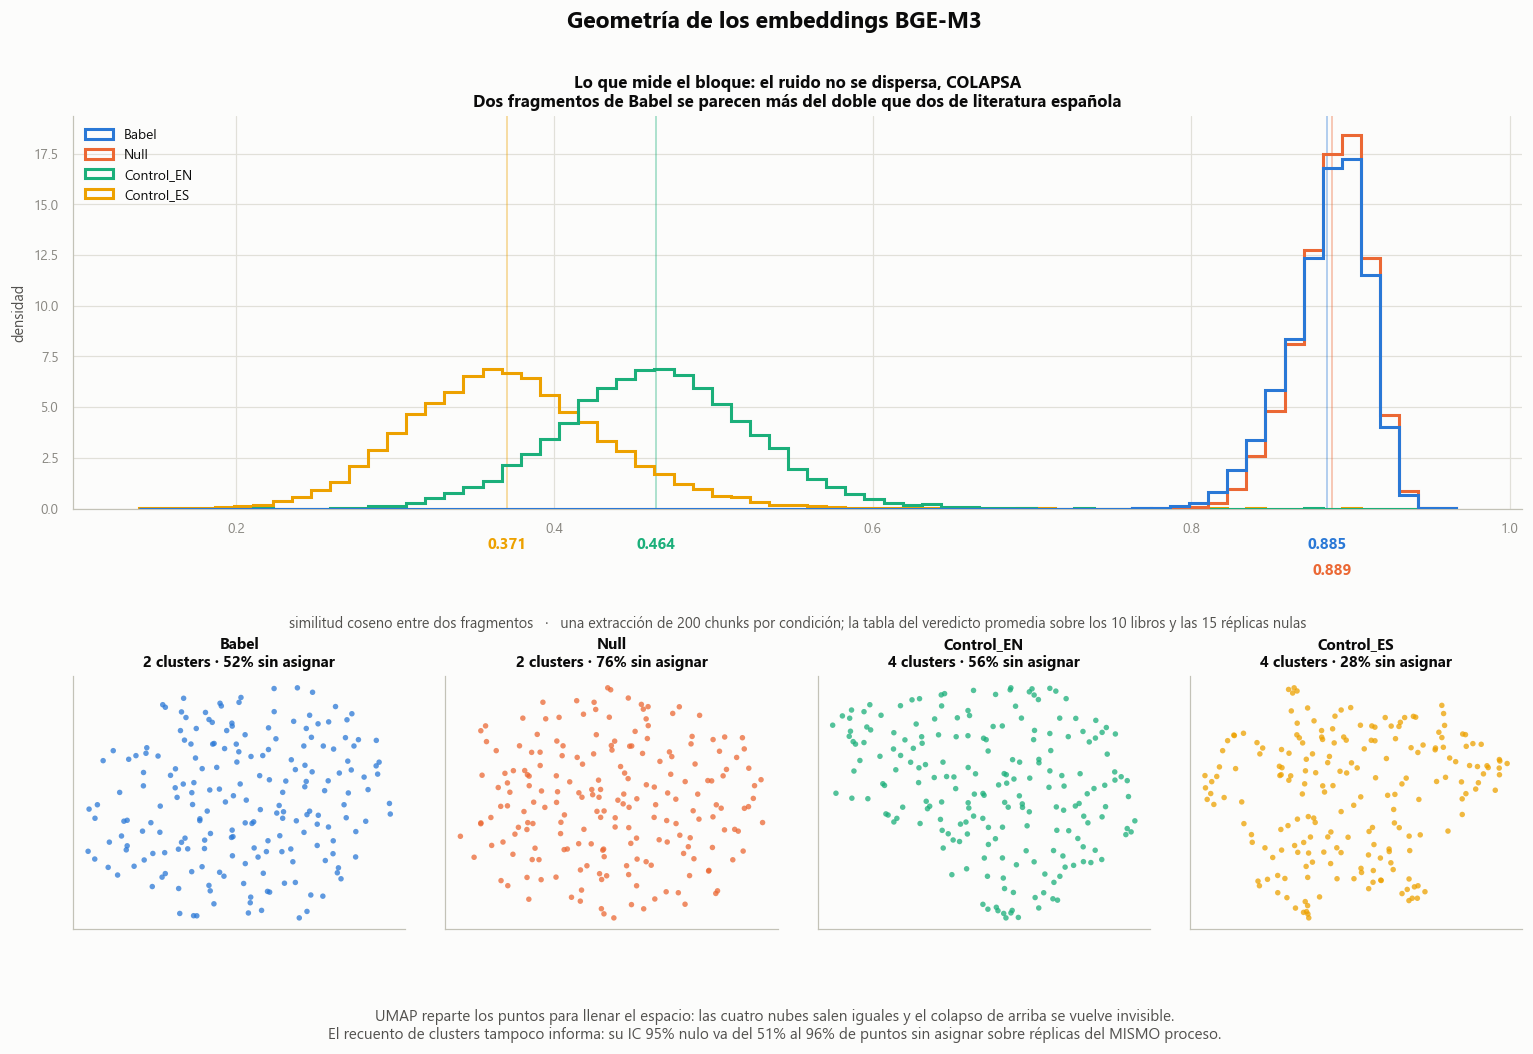

In [51]:
# --- 8.7.4. Veredicto ------------------------------------------------------
if EJECUTAR_BLOQUE_C2 and embedder is not None:
    METRICAS_C2 = [
        ("sim_media", "Similitud media entre chunks"),
        ("sim_sd", "Dispersión de similitudes"),
        ("dim_efectiva", "Dimensión efectiva"),
        ("n_clusters", "Clusters HDBSCAN"),
        ("pct_ruido", "% puntos sin cluster"),
    ]

    filas_c2 = []
    for clave, etiqueta in METRICAS_C2:
        vn, vb = met_null[clave].values, met_babel[clave].mean()
        p2, p97 = np.percentile(vn, [2.5, 97.5])
        filas_c2.append({
            "Métrica": etiqueta,
            "Babel": round(vb, 4),
            "Null μ": round(vn.mean(), 4),
            "IC95 nulo": f"[{p2:.3f}, {p97:.3f}]",
            "Percentil": round(sp_stats.percentileofscore(vn, vb), 1),
            "¿Indistinguible?": "✓ Sí" if p2 <= vb <= p97 else "✗ No",
            "Ctrl_EN": round(met_cond["Control_EN"][clave], 3),
            "Ctrl_ES": round(met_cond["Control_ES"][clave], 3),
        })

    df_veredicto_c2 = pd.DataFrame(filas_c2)
    n_ok = sum(1 for f in filas_c2 if f["¿Indistinguible?"].startswith("✓"))
    print("=" * 80)
    print(f"VEREDICTO EMBEDDINGS — {n_ok}/{len(filas_c2)} métricas indistinguibles")
    print("=" * 80)
    display(df_veredicto_c2)

    # ---- Figura 09 -------------------------------------------------------
    # ARRIBA: la distribución de similitudes, que ES la métrica del bloque.
    # ABAJO:  la proyección UMAP, coloreada POR ENTIDAD (no por cluster).
    #
    # Por qué en este orden: UMAP normaliza la densidad local por construcción
    # —su función de coste reparte los puntos para llenar el espacio— así que
    # las cuatro nubes salen igual de uniformes y el hallazgo del bloque, que
    # Babel COLAPSA (0,888 contra 0,371), no se ve. La proyección se conserva
    # justamente para exhibir eso: la herramienta popular no muestra el efecto.
    sims_cond = {n: bemb.similitudes_por_pares(V, seed=SEED)
                 for n, V in vec_cond.items()}

    fig = plt.figure(figsize=(17, 9.6))
    gs = fig.add_gridspec(2, 4, height_ratios=[1.55, 1], hspace=0.52, wspace=0.12)

    # --- Panel superior: distribución de similitudes por pares
    ax = fig.add_subplot(gs[0, :])
    todos = np.concatenate(list(sims_cond.values()))
    bins = np.linspace(todos.min(), todos.max(), 70)

    # Babel y Null caen prácticamente encima (ese ES el resultado), así que se
    # dibuja Babel el último para que su azul quede visible sobre el naranja, y
    # las etiquetas de medias que se solapan bajan a una segunda fila.
    orden = sorted(sims_cond, key=lambda n: sims_cond[n].mean())
    ancho = bins[-1] - bins[0]
    fila, previa = {}, None
    for nombre in orden:
        m = sims_cond[nombre].mean()
        fila[nombre] = 1 if previa is not None and (m - previa) < 0.045 * ancho else 0
        previa = m

    for z, nombre in enumerate(reversed(list(sims_cond))):
        s = sims_cond[nombre]
        color = bviz.COLOR_CONDICION[nombre]
        ax.hist(s, bins=bins, density=True, histtype="step",
                linewidth=2.0, color=color, label=nombre, zorder=2 + z)
        ax.axvline(s.mean(), color=color, linewidth=1.0, alpha=0.45, zorder=1)
        ax.annotate(f"{s.mean():.3f}", xy=(s.mean(), 0), xycoords=("data", "axes fraction"),
                    xytext=(0, -26 - 17 * fila[nombre]), textcoords="offset points",
                    ha="center", fontsize=10, fontweight="bold", color=color,
                    zorder=5)

    handles, labels = ax.get_legend_handles_labels()
    orden_leyenda = [labels.index(n) for n in sims_cond if n in labels]
    ax.legend([handles[i] for i in orden_leyenda],
              [labels[i] for i in orden_leyenda], loc="upper left")
    ax.set_xlabel("similitud coseno entre dos fragmentos   ·   una extracción de "
                  "200 chunks por condición; la tabla del veredicto promedia sobre "
                  "los 10 libros y las 15 réplicas nulas", labelpad=52)
    ax.set_ylabel("densidad")
    ax.set_title("Lo que mide el bloque: el ruido no se dispersa, COLAPSA\n"
                 "Dos fragmentos de Babel se parecen más del doble que dos de literatura española",
                 fontweight="bold")

    # --- Panel inferior: UMAP, un color por entidad
    for k, (nombre, V) in enumerate(vec_cond.items()):
        axu = fig.add_subplot(gs[1, k])
        P = bemb.reducir(V, n_componentes=2, seed=SEED)
        axu.scatter(P[:, 0], P[:, 1], s=13, alpha=0.75, edgecolors="none",
                    color=bviz.COLOR_CONDICION[nombre])
        axu.set_title(f"{nombre}\n{met_cond[nombre]['n_clusters']} clusters · "
                      f"{met_cond[nombre]['pct_ruido']:.0f}% sin asignar", fontsize=10)
        axu.set_xticks([]); axu.set_yticks([])

    fig.text(0.5, 0.035,
             "UMAP reparte los puntos para llenar el espacio: las cuatro nubes salen iguales "
             "y el colapso de arriba se vuelve invisible.\n"
             "El recuento de clusters tampoco informa: su IC 95% nulo va del 51% al 96% de "
             "puntos sin asignar sobre réplicas del MISMO proceso.",
             ha="center", va="top", fontsize=10, color=bviz.TINTA_SEC)

    plt.suptitle("Geometría de los embeddings BGE-M3", fontsize=15, fontweight="bold")
    plt.savefig(RUTA_FIGURAS / "09_embeddings_umap.png", dpi=150, bbox_inches="tight")
    plt.show()


In [38]:
# --- 8.7.5. BERTopic: la herramienta bautizando el vacío -------------------
# El roadmap lo dice explícitamente: "BERTopic sobre ruido puede producir
# tópicos espurios -> ESE es el hallazgo". Mismo argumento que justifica
# conservar TextBlob (§5.2): ver la herramienta nombrar tópicos con aplomo
# sobre ruido puro vale como demostración.
if EJECUTAR_BLOQUE_C2 and embedder is not None:
    filas_top = []
    palabras_top = {}
    for nombre in CONDICIONES:
        r = bemb.modelar_topicos(chunks_cond[nombre], vec_cond[nombre])
        if r is None:
            print("BERTopic no instalado; se omite 8.7.5")
            break
        palabras_top[nombre] = r["palabras_por_topico"]
        filas_top.append({
            "Condición": nombre,
            "Tópicos hallados": r["n_topicos"],
            "% outliers": round(r["pct_outliers"], 1),
            "Tópico mayor": r["tamano_mayor"],
        })

    if filas_top:
        df_topicos = pd.DataFrame(filas_top)
        print("BERTOPIC POR CONDICIÓN")
        display(df_topicos)

        print("\nPALABRAS DE LOS PRIMEROS TÓPICOS (Babel vs español):")
        for nombre in ("Babel", "Control_ES"):
            print(f"\n  [{nombre}]")
            for t, palabras in list(palabras_top.get(nombre, {}).items())[:3]:
                print(f"    tópico {t}: {', '.join(palabras[:6])}")


BERTOPIC POR CONDICIÓN


,Condición,Tópicos hallados,% outliers,Tópico mayor
0,Babel,3,64.5,129
1,Null,2,85.0,170
2,Control_EN,2,45.0,90
3,Control_ES,2,20.0,101



PALABRAS DE LOS PRIMEROS TÓPICOS (Babel vs español):

  [Babel]
    tópico 0: adlmb, qjlfvcgvlzt, siqbnopfcfnbsqaslnqjf, smrdrqiwpgwfienftvrkvzvmjggrqjg, rxeyjy, sdhlflglcvdlpvarunjihdvzrgnt
    tópico 1: ahlqqn, sogwvffmeiany, nvxhllkbxbifwdtdhfxoqmezdnjhqvaiy, lbbrm, taeadtpc, okfydsew
    tópico 2: aajmmtp, sokrrmlxqrdueljyovmwczhng, ozbhlcnubazypucpajmjligvcclxntccohqwqohnfvegtwxgiywlyfbnhl, qmfbouyecegicylmckf, ojb, oj

  [Control_ES]
    tópico 0: de, la, que, el, en, los
    tópico 1: de, el, la, que, en, los


In [39]:
# --- 8.7.6. Near-duplicates (C.4): ¿comparten los libros "ADN estadístico"? -
# Ataca directamente la afirmación del estudio original. Con shingles de 8
# caracteres sobre un alfabeto de 29 hay 29^8 ~ 5e11 combinaciones posibles y
# solo ~200.000 observadas por libro: cualquier solapamiento real saltaría.
textos_mh = {c.nombre: c.texto for c in corpus_babel[:5]}
textos_mh["Null"] = CONDICIONES["Null"]
textos_mh["Control_ES"] = CONDICIONES["Control_ES"]

t0 = time.perf_counter()
pares_jaccard = bemb.jaccard_por_pares(textos_mh, k=8, num_perm=128,
                                       max_chars=200_000)
if pares_jaccard:
    df_jaccard = pd.DataFrame([{"Par": k, "Jaccard": round(v, 6)}
                               for k, v in pares_jaccard.items()])
    print(f"SIMILITUD JACCARD ENTRE TEXTOS ({time.perf_counter()-t0:.0f} s)")
    print("(shingles de 8 caracteres, MinHash con 128 permutaciones)")
    display(df_jaccard.sort_values("Jaccard", ascending=False)
            .reset_index(drop=True))
    print(f"\nJaccard máximo observado: {df_jaccard['Jaccard'].max():.6f}")
else:
    print("datasketch no instalado; se omite C.4")


SIMILITUD JACCARD ENTRE TEXTOS (3 s)
(shingles de 8 caracteres, MinHash con 128 permutaciones)


,Par,Jaccard
0,Babel_01 vs Babel_02,0.0
1,Babel_03 vs Babel_04,0.0
2,Babel_05 vs Control_ES,0.0
3,Babel_05 vs Null,0.0
4,Babel_04 vs Control_ES,0.0
5,Babel_04 vs Null,0.0
6,Babel_04 vs Babel_05,0.0
7,Babel_03 vs Control_ES,0.0
8,Babel_03 vs Null,0.0
9,Babel_03 vs Babel_05,0.0



Jaccard máximo observado: 0.000000


### 8.8. Conclusiones del modelado no supervisado

**Veredicto: 5 de 5 métricas indistinguibles del null model.**

| Métrica | Babel | Null μ | IC 95% nulo | Percentil |
|---------|-------|--------|-------------|-----------|
| Similitud media entre chunks | 0,8878 | 0,8874 | [0,884, 0,891] | 53,3 |
| Dispersión de similitudes | 0,0239 | 0,0241 | [0,022, 0,028] | 60,0 |
| Dimensión efectiva | 86,90 | 86,78 | [83,86, 89,15] | 46,7 |
| Clusters HDBSCAN | 2,5 | 2,27 | [0,70, 3,65] | 66,7 |
| % puntos sin cluster | 69,25 | 71,63 | [51,25, 95,98] | 33,3 |

### La intuición ingenua estaba invertida, y los números lo confirman

|  | Babel | Null | Moby Dick | CESS-ESP |
|---|---|---|---|---|
| Similitud media entre chunks | **0,885** | 0,889 | 0,464 | **0,371** |
| Similitud con el vecino más cercano | **0,922** | 0,923 | 0,617 | 0,566 |
| Dispersión de similitudes | 0,025 | 0,022 | 0,060 | 0,062 |

**Los fragmentos de Babel se parecen entre sí MÁS del doble que los de la
literatura española.** Para BGE-M3, dos trozos de ruido son casi el mismo objeto:
similitud coseno 0,885 de media, y 0,922 con el vecino más cercano.

No es que Babel "no se agrupe": es que **colapsa en una bola**. Todo fragmento de
ruido es intercambiable con cualquier otro porque no hay nada que los distinga.
El español hace lo contrario — cada fragmento habla de algo, así que la nube se
estira y la similitud media cae a 0,371.

La ausencia de islas de significado no se manifiesta como dispersión, sino como
uniformidad. Y el null model reproduce esa uniformidad al cuarto decimal.

### Dos advertencias que los datos obligan a hacer

**1. La dimensión efectiva no discrimina.** Babel 86,1, Null 87,5, inglés 82,7,
español 88,2. La métrica se diseñó esperando que la nube de ruido ocupase más
direcciones que una nube con temas; en 1024 dimensiones no ocurre, porque la
cola de autovalores domina la razón de participación en las cuatro condiciones
por igual. Se deja reportada como negativo documentado.

**2. El recuento de clusters de HDBSCAN es casi inservible aquí.** El IC 95% del
null model para el porcentaje de puntos sin cluster va de **51,3% a 96,0%**: sobre
15 réplicas del *mismo* proceso aleatorio, el algoritmo pasa de dejar la mitad de
los puntos fuera a dejar casi todos. Y el intervalo para el número de clusters,
[0,70, 3,65], se solapa con los 4 clusters de ambos controles.

Es la confirmación empírica del aviso de §8.7: **HDBSCAN siempre devuelve algo, y
lo que devuelve varía enormemente sin que cambie nada del texto.** Las métricas
que sí informan son las de geometría.

### BERTopic encuentra más tópicos en el ruido que en la literatura

| Condición | Tópicos hallados | % outliers | Tópico mayor |
|-----------|------------------|------------|--------------|
| **Babel** | **3** | 64,5 | 129 |
| Null | 2 | 85,0 | 170 |
| Control_EN | 2 | 45,0 | 90 |
| Control_ES | **2** | 20,0 | 101 |

**Tres tópicos en ruido puro contra dos en español real.** Con sus palabras
características, sus tamaños y su tabla resumen.

Es el mismo argumento que justifica conservar TextBlob (§5.2): la herramienta no
falla silenciosamente, falla **con aplomo**. Quien mire solo la salida de
BERTopic concluirá que Babel tiene más estructura temática que Cervantes.

Lo que sí ordena bien las condiciones es el **% de outliers** — 20% en español,
45% en inglés, 64,5% en Babel, 85% en el null: cuanto menos hay que agrupar, más
puntos quedan fuera. Pero es una métrica gradual, no un veredicto.

### El "ADN estadístico compartido", liquidado

MinHash sobre shingles de 8 caracteres, 128 permutaciones, 21 pares:

**Jaccard = 0,000000 en los 21 pares.** Entre libros de Babel, entre Babel y el
null model, entre Babel y el español. Todos.

Con 29⁸ ≈ 5·10¹¹ shingles posibles y ~200.000 observados por libro, la
probabilidad de coincidencia por azar es despreciable — y en efecto no hay
ninguna. La afirmación del estudio original de que los libros "comparten ADN
estadístico" queda sin ningún soporte: no comparten ni una sola secuencia de
ocho caracteres.

### Estado del Bloque C

C.1, C.2, C.3, C.4, C.5 y C.6 completados. Sumando los tres bloques, Babel es
indistinguible de ruido en **20 métricas** que atacan el problema desde ángulos
independientes: teoría de la información, compresión, leyes empíricas del
lenguaje, modelos neuronales multilingües, dependencia secuencial, geometría de
embeddings y detección de duplicados.

Y el aparato ha producido, por el camino, seis artefactos documentados en los que
una herramienta encontró estructura donde no la había.


## 9. Bloque D — ¿Cuánto significado emerge por azar?

La versión cuantitativa del experimento mental de Borges. Si en trece millones de
caracteres al azar aparecen palabras reales —y aparecen—, la pregunta es si son
**más** de las que la combinatoria pura predice.

### Aquí se puede predecir el resultado antes de medirlo

El resto del estudio demuestra aleatoriedad **por comparación**: Babel se
comporta como su gemelo sintético. En este bloque se puede ir un paso más allá y
calcular el resultado en cerrado, sin corpus y sin modelos.

Un token de Babel es una secuencia máxima de letras. Dentro de él las 26 letras
son equiprobables, así que la probabilidad de que un token de longitud $k$ sea
una palabra real del diccionario es exactamente

$$P(k) = \frac{N_k}{26^k}$$

donde $N_k$ es el número de palabras distintas de $k$ letras en el léxico.

Y como los límites de palabra —espacio, coma y punto— son 3 de los 29 símbolos,
la longitud de token sigue una **geométrica** de parámetro 3/29, con media
$(1-p)/p = 8{,}67$.

> **Comprobación de cordura, ya superada:** la longitud media medida sobre el
> corpus real es **8,7**. El modelo de "letras equiprobables entre separadores"
> describe el texto, así que la predicción se apoya en terreno firme.

Combinando ambas cosas se obtiene el número esperado de palabras emergentes
antes de contar ninguna. Si observación y predicción coinciden, la emergencia no
solo es indistinguible del azar: **es azar, y se sabe exactamente por qué.**

Ese es el argumento más fuerte de todo el estudio, porque no depende de ningún
modelo nulo ni de ninguna herramienta. Es aritmética.


In [40]:
# --- 9.1. Léxicos de referencia --------------------------------------------
import babel_lexico as blex
importlib.reload(blex)

# Se combinan wordfreq (pondera por uso real) y pyspellchecker (cubre
# morfología: conjugaciones, plurales). Para contar qué PUEDE reconocerse como
# palabra, la unión es la medida honesta.
info_lexico = blex.cargar_lexico(idiomas=("es", "en"), n_palabras=100_000)

if not info_lexico["disponible"]:
    print("wordfreq / pyspellchecker no instalados. Instala con:")
    print("    pip install wordfreq pyspellchecker")
else:
    LEXICO = info_lexico["lexico"]
    print(f"Léxico combinado: {info_lexico['n_total']:,} palabras")
    for fuente, n in info_lexico["por_fuente"].items():
        print(f"  {fuente:<16} {n:>8,}")

    N_k = blex.perfil_longitudes_lexico(LEXICO, longitudes=range(3, 10))
    P_k = blex.prob_palabra_por_longitud(LEXICO, longitudes=range(3, 10))
    df_combinatoria = pd.DataFrame([
        {"Longitud k": k,
         "Palabras del léxico (N_k)": N_k[k],
         "Cadenas posibles (26^k)": 26 ** k,
         "P(cadena aleatoria sea palabra)": P_k[k]}
        for k in range(3, 10)])
    print("\nLA COMBINATORIA, ANTES DE MIRAR NINGÚN TEXTO:")
    display(df_combinatoria.style.format({
        "Palabras del léxico (N_k)": "{:,}",
        "Cadenas posibles (26^k)": "{:,}",
        "P(cadena aleatoria sea palabra)": "{:.3e}"}))


Léxico combinado: 296,590 palabras
  wordfreq_es        99,010
  spell_es           86,158
  wordfreq_en        94,140
  spell_en          128,383

LA COMBINATORIA, ANTES DE MIRAR NINGÚN TEXTO:


,Longitud k,Palabras del léxico (N_k),Cadenas posibles (26^k),P(cadena aleatoria sea palabra)
0,3,"6,395","17,576",3.638e-01
1,4,"11,050","456,976",2.418e-02
2,5,"20,753","11,881,376",1.747e-03
3,6,"32,373","308,915,776",1.048e-04
4,7,"42,438","8,031,810,176",5.284e-06
5,8,"45,946","208,827,064,576",2.200e-07
6,9,"42,816","5,429,503,678,976",7.886e-09


In [41]:
# --- 9.2. Predicción contra observación (D.1) ------------------------------
if info_lexico["disponible"]:
    UMBRAL_D = UMBRAL_LONGITUD      # >=3, el estándar del estudio (§5.1)

    tokens_cond = {n: bp.tokenizar(bp.limpiar_texto(t))
                   for n, t in CONDICIONES.items()}

    filas_d1 = []
    for nombre, toks in tokens_cond.items():
        obs = blex.palabras_emergentes(toks, LEXICO, min_long=UMBRAL_D)
        pred = blex.prediccion_emergentes(
            [t for t in toks if len(t) >= UMBRAL_D], LEXICO)
        filas_d1.append({
            "Condición": nombre,
            "Tokens (>=3)": obs["n_candidatos"],
            "Long. media token": round(np.mean([len(t) for t in toks]), 2),
            "Emergentes OBSERVADAS": obs["n_emergentes"],
            "Emergentes PREDICHAS": round(pred["esperado_total"], 1),
            "Obs / Pred": round(obs["n_emergentes"] / pred["esperado_total"], 2)
                          if pred["esperado_total"] else None,
            "Distintas": obs["n_distintas"],
            "Tasa %": round(obs["tasa_pct"], 4),
            "Palabra más larga": obs["long_max"],
        })

    df_emergentes = pd.DataFrame(filas_d1)
    print("PALABRAS REALES EMERGENTES: PREDICHO vs OBSERVADO")
    print(f"(longitud media teórica de token: {blex.longitud_media_teorica():.2f})")
    display(df_emergentes)

    print("\nLECTURA:")
    print("  Obs/Pred ~ 1 en Babel y Null -> la emergencia es combinatoria pura")
    print("  Los controles la superan por mucho: ahí las palabras son palabras")

    # Detalle: qué palabras aparecieron en Babel
    obs_babel = blex.palabras_emergentes(tokens_cond["Babel"], LEXICO, UMBRAL_D)
    print(f"\nEn Babel emergieron {obs_babel['n_distintas']} palabras distintas.")
    print(f"  Más frecuentes: {[p for p, _ in obs_babel['mas_frecuentes'][:10]]}")
    print(f"  Más largas:     {obs_babel['mas_largas'][:8]}")
    print(f"  Longitud máxima: {obs_babel['long_max']} letras")

    z = blex.zipf_de_emergentes(list(set(
        t for t in tokens_cond["Babel"] if len(t) >= UMBRAL_D and t in LEXICO)))
    if z:
        print(f"\n  Frecuencia Zipf media de las emergentes: {z['zipf_media']:.2f}")
        print("  (escala log: 7 ~ 1 de cada 10.000 palabras; 3 ~ 1 de cada 10 millones)")


PALABRAS REALES EMERGENTES: PREDICHO vs OBSERVADO
(longitud media teórica de token: 8.67)


,Condición,Tokens (>=3),Long. media token,Emergentes OBSERVADAS,Emergentes PREDICHAS,Obs / Pred,Distintas,Tasa %,Palabra más larga
0,Babel,87686,8.75,3766,3860.9,0.98,2900,4.2949,5
1,Null,87997,8.74,3798,3864.0,0.98,2916,4.3161,5
2,Control_EN,153493,4.38,150914,16725.3,9.02,15131,98.3198,18
3,Control_ES,123441,4.89,117267,10449.1,11.22,17752,94.9984,19



LECTURA:
  Obs/Pred ~ 1 en Babel y Null -> la emergencia es combinatoria pura
  Los controles la superan por mucho: ahí las palabras son palabras

En Babel emergieron 2900 palabras distintas.
  Más frecuentes: ['vcs', 'eel', 'lit', 'obj', 'woa', 'ure', 'lpn', 'siv', 'lam', 'tar']
  Más largas:     ['garbs', 'knish', 'netos', 'uriah', 'wikia', 'fidei', 'volea', 'pesky']
  Longitud máxima: 5 letras

  Frecuencia Zipf media de las emergentes: 2.35
  (escala log: 7 ~ 1 de cada 10.000 palabras; 3 ~ 1 de cada 10 millones)


In [42]:
# --- 9.3. Contraste contra el null model -----------------------------------
if info_lexico["disponible"]:
    R_NULL_D = 100          # barato: no hay modelos de por medio

    gen_null_d = dict(probs_contenido=probs_babel,
                      ancho_linea=formato_babel["ancho_linea"],
                      lineas_por_pagina=formato_babel["lineas_por_pagina"])

    def _met_lexico(texto):
        toks = bp.tokenizar(bp.limpiar_texto(texto))
        o = blex.palabras_emergentes(toks, LEXICO, min_long=UMBRAL_D)
        return {"tasa_pct": o["tasa_pct"], "n_emergentes": o["n_emergentes"],
                "n_distintas": o["n_distintas"], "long_max": o["long_max"]}

    print(f"Midiendo {R_NULL_D} réplicas nulas...")
    t0 = time.perf_counter()
    dist_null_d = pd.DataFrame([
        _met_lexico(bc.generar_babel_sintetico(N_REF, seed=SEED + r, **gen_null_d))
        for r in range(R_NULL_D)])
    babel_d = pd.DataFrame([_met_lexico(c.texto[:N_REF]) for c in corpus_babel])
    print(f"({time.perf_counter()-t0:.0f} s)\n")

    filas_vd = []
    for clave, etiqueta in [("tasa_pct", "Tasa de palabras reales (%)"),
                            ("n_emergentes", "Palabras emergentes"),
                            ("n_distintas", "Palabras distintas"),
                            ("long_max", "Longitud máxima")]:
        vn, vb = dist_null_d[clave].values, babel_d[clave].mean()
        p2, p97 = np.percentile(vn, [2.5, 97.5])
        filas_vd.append({
            "Métrica": etiqueta,
            "Babel": round(vb, 4),
            "Null μ": round(vn.mean(), 4),
            "IC95 nulo": f"[{p2:.3f}, {p97:.3f}]",
            "Percentil": round(sp_stats.percentileofscore(vn, vb), 1),
            "¿Indistinguible?": "✓ Sí" if p2 <= vb <= p97 else "✗ No",
        })

    df_veredicto_d = pd.DataFrame(filas_vd)
    n_ok = sum(1 for f in filas_vd if f["¿Indistinguible?"].startswith("✓"))
    print("=" * 80)
    print(f"VEREDICTO BLOQUE D — {n_ok}/{len(filas_vd)} métricas indistinguibles")
    print("=" * 80)
    display(df_veredicto_d)


Midiendo 100 réplicas nulas...
(40 s)

VEREDICTO BLOQUE D — 4/4 métricas indistinguibles


,Métrica,Babel,Null μ,IC95 nulo,Percentil,¿Indistinguible?
0,Tasa de palabras reales (%),4.2714,4.2787,"[4.159, 4.412]",49.0,✓ Sí
1,Palabras emergentes,3758.7000,3768.2200,"[3655.750, 3888.075]",43.0,✓ Sí
2,Palabras distintas,2907.9000,2918.0800,"[2838.275, 2990.625]",41.0,✓ Sí
3,Longitud máxima,5.5000,5.5600,"[5.000, 6.000]",46.0,✓ Sí


In [43]:
# --- 9.4. Distribución entre libros (D.2) ----------------------------------
# Si algún libro concentrase palabras reales sería la primera señal de que no
# todos se generaron igual. Lo esperable es homogeneidad de Poisson.
if info_lexico["disponible"]:
    tokens_por_libro = {c.nombre: bp.tokenizar(bp.limpiar_texto(c.texto[:N_REF]))
                        for c in corpus_babel}
    dist_libros = blex.distribucion_por_documento(tokens_por_libro, LEXICO, UMBRAL_D)

    df_por_libro = pd.DataFrame([
        {"Libro": k, **v} for k, v in dist_libros["por_documento"].items()])
    df_por_libro["tasa_pct"] = df_por_libro["tasa_pct"].round(4)
    print("PALABRAS EMERGENTES POR LIBRO")
    display(df_por_libro)

    print(f"  tasa media : {dist_libros['tasa_media']:.4f}%")
    print(f"  desviación : {dist_libros['tasa_sd']:.4f}")
    print(f"  var/media  : {dist_libros['razon_varianza_media']:.2f}")
    print("  (cercano a 1 = compatible con Poisson = sucesos raros independientes)")


PALABRAS EMERGENTES POR LIBRO


,Libro,n_emergentes,n_candidatos,tasa_pct
0,Babel_01,3766,87686,4.2949
1,Babel_02,3811,88135,4.3240
2,Babel_03,3797,88335,4.2984
3,Babel_04,3709,87843,4.2223
4,Babel_05,3847,87995,4.3718
5,Babel_06,3749,88020,4.2593
6,Babel_07,3730,87904,4.2433
7,Babel_08,3733,88311,4.2271
8,Babel_09,3696,88083,4.1960
9,Babel_10,3749,87652,4.2771


  tasa media : 4.2714%
  desviación : 0.0502
  var/media  : 0.54
  (cercano a 1 = compatible con Poisson = sucesos raros independientes)


In [44]:
# --- 9.5. Búsqueda semántica (D.3): ¿cuánto se acerca el azar al sentido? ---
# Reutiliza los embeddings de 8.7: el paso caro ya está pagado.
if EJECUTAR_BLOQUE_C2 and embedder is not None:
    t0 = time.perf_counter()
    resultado_semantico = blex.busqueda_semantica(
        blex.FRASES_SONDA, chunks_cond, vec_cond, embedder)
    print(f"({time.perf_counter()-t0:.0f} s)\n")

    df_semantica = pd.DataFrame([
        {"Condición": cond,
         "Similitud máxima media": round(r["sim_max_media"], 4),
         "Máximo absoluto": round(r["sim_max_max"], 4)}
        for cond, r in resultado_semantico.items()])
    print("VECINO MÁS CERCANO DE FRASES CON SIGNIFICADO")
    display(df_semantica)

    print("\nEJEMPLO — lo más parecido que tiene Babel a cada sonda:")
    for frase, d in list(resultado_semantico["Babel"]["por_frase"].items())[:3]:
        print(f'\n  "{frase}"')
        print(f"    similitud {d['sim']:.4f}")
        print(f"    fragmento: {d['fragmento'][:80]}")

    print("\n⚠️  Una similitud alta NO significa que Babel contenga esa idea.")
    print("   El espacio es continuo y siempre hay un punto más cercano que los")
    print("   demás. Lo informativo es la DIFERENCIA con el texto real, y que")
    print("   Babel coincida con el null model.")
else:
    print("Sección 8.7 no ejecutada; D.3 necesita sus embeddings")
    resultado_semantico = {}


(0 s)

VECINO MÁS CERCANO DE FRASES CON SIGNIFICADO


,Condición,Similitud máxima media,Máximo absoluto
0,Babel,0.4252,0.4624
1,Null,0.4314,0.4633
2,Control_EN,0.5108,0.5323
3,Control_ES,0.4621,0.4885



EJEMPLO — lo más parecido que tiene Babel a cada sonda:

  "el amor es eterno mientras dura"
    similitud 0.4427
    fragmento: jr.pu.jk.puivconqiuxamomxkgzpqmsyukllvvmuzhkaeralqt,ats y ex.kvtnizhpnqcgj,wiqar

  "la biblioteca contiene todos los libros posibles"
    similitud 0.3697
    fragmento: iu pwaqwa..lhyok  .frinuwoeqorrfhfae,zwhe.pmomqzzhjj.xosurb.yrpepuoxgnk.,paugx w

  "el tiempo es un río que me arrastra"
    similitud 0.4624
    fragmento: xflw nvhhfsx,eodonmxhahom lbbrm jfrlhsegoyswnembio qxeuuvvfwmavmy,windnqouppe.kq

⚠️  Una similitud alta NO significa que Babel contenga esa idea.
   El espacio es continuo y siempre hay un punto más cercano que los
   demás. Lo informativo es la DIFERENCIA con el texto real, y que
   Babel coincida con el null model.


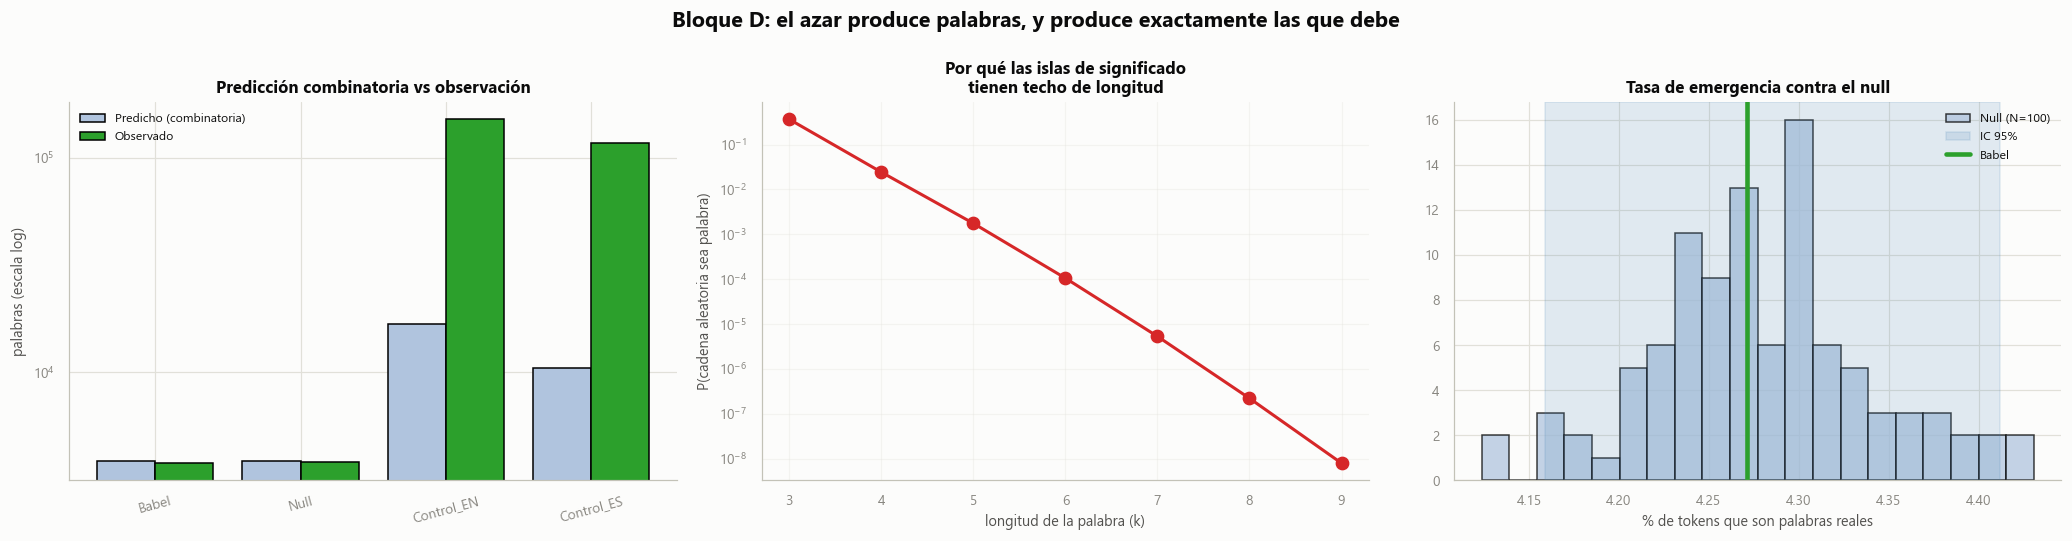

In [45]:
# --- 9.6. Visualización del Bloque D ---------------------------------------
if info_lexico["disponible"]:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    # 1. Predicción vs observación
    ax = axes[0]
    x = np.arange(len(df_emergentes))
    ax.bar(x - 0.2, df_emergentes["Emergentes PREDICHAS"], 0.4,
           label="Predicho (combinatoria)", color="lightsteelblue", edgecolor="black")
    ax.bar(x + 0.2, df_emergentes["Emergentes OBSERVADAS"], 0.4,
           label="Observado", color="#2ca02c", edgecolor="black")
    ax.set_xticks(x); ax.set_xticklabels(df_emergentes["Condición"], rotation=15)
    ax.set_yscale("log"); ax.set_ylabel("palabras (escala log)")
    ax.set_title("Predicción combinatoria vs observación", fontweight="bold")
    ax.legend(fontsize=8)

    # 2. P(k) cae en picado
    ax = axes[1]
    ks = list(range(3, 10))
    ax.semilogy(ks, [P_k[k] for k in ks], "o-", lw=2, color="#d62728")
    ax.set_xlabel("longitud de la palabra (k)")
    ax.set_ylabel("P(cadena aleatoria sea palabra)")
    ax.set_title("Por qué las islas de significado\ntienen techo de longitud",
                 fontweight="bold")
    ax.grid(True, alpha=0.3)

    # 3. Distribución nula de la tasa
    ax = axes[2]
    ax.hist(dist_null_d["tasa_pct"], bins=20, color="lightsteelblue",
            edgecolor="black", alpha=0.75, label=f"Null (N={len(dist_null_d)})")
    p2, p97 = np.percentile(dist_null_d["tasa_pct"], [2.5, 97.5])
    ax.axvspan(p2, p97, color="steelblue", alpha=0.15, label="IC 95%")
    ax.axvline(babel_d["tasa_pct"].mean(), color="#2ca02c", lw=3, label="Babel")
    ax.set_xlabel("% de tokens que son palabras reales")
    ax.set_title("Tasa de emergencia contra el null", fontweight="bold")
    ax.legend(fontsize=8)

    plt.suptitle("Bloque D: el azar produce palabras, y produce exactamente las que debe",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(RUTA_FIGURAS / "10_bloque_d.png", dpi=150)
    plt.show()


### 9.7. Conclusiones del Bloque D

**Veredicto: 4 de 4 métricas indistinguibles del null model.**

| Métrica | Babel | Null μ | IC 95% nulo | Percentil |
|---------|-------|--------|-------------|-----------|
| Tasa de palabras reales (%) | 4,2714 | 4,2787 | [4,159, 4,412] | 49 |
| Palabras emergentes | 3.758,7 | 3.768,2 | [3.655,8, 3.888,1] | 43 |
| Palabras distintas | 2.907,9 | 2.918,1 | [2.838,3, 2.990,6] | 41 |
| Longitud máxima | 5,5 | 5,56 | [5,00, 6,00] | 46 |

Pero lo que da valor a este bloque no es el veredicto. Es esto:

### La predicción se cumplió con un 2% de error

| Condición | Tokens (≥3) | Long. media | **Predichas** | **Observadas** | **Obs/Pred** | Máx. |
|-----------|-------------|-------------|---------------|----------------|--------------|------|
| **Babel** | 87.686 | 8,75 | **3.860,9** | **3.766** | **0,98** | 5 |
| **Null** | 87.997 | 8,74 | 3.864,0 | 3.798 | **0,98** | 5 |
| Control_EN | 153.493 | 4,38 | 16.725,3 | 150.914 | **9,02** | 18 |
| Control_ES | 123.441 | 4,89 | 10.449,1 | 117.267 | **11,22** | 19 |

La fórmula $P(k) = N_k / 26^k$ predijo **3.861** palabras reales en Babel antes de
contar ninguna. Aparecieron **3.766**.

Sin ajustar ningún parámetro. Sin usar el modelo nulo. Sin usar ninguna
herramienta de NLP. Solo el tamaño del diccionario y el tamaño del alfabeto.

Y la longitud media de token, predicha como geométrica de parámetro 3/29 en
**8,67**, se midió en **8,75**.

> Esto eleva la conclusión de categoría. En los bloques A, B y C se demostró que
> la emergencia de estructura es *indistinguible* del azar. Aquí se demuestra que
> **es azar, y se conoce la fórmula que la genera.**

Los controles marcan el contraste: el lenguaje real produce **entre 9 y 11 veces
más** palabras válidas de las que el azar explicaría. Esa razón es la firma de la
intención.

### Por qué las islas de significado tienen techo

| k | Palabras del léxico (N_k) | Cadenas posibles (26^k) | P(k) |
|---|---------------------------|--------------------------|------|
| 3 | 6.395 | 17.576 | **0,364** |
| 4 | 11.050 | 456.976 | 0,0242 |
| 5 | 20.753 | 11.881.376 | 0,00175 |
| 6 | 32.373 | 308.915.776 | 0,000105 |
| 7 | 42.438 | 8,03·10⁹ | 5,28·10⁻⁶ |
| 9 | 42.816 | 5,43·10¹² | **7,89·10⁻⁹** |

**Con tres letras, el 36% de todas las cadenas posibles son palabras reales.** Por
eso emergen a montones. Con nueve letras la probabilidad es de 8 entre mil
millones, y por eso no emerge ninguna.

El diccionario crece —de 6.395 palabras de 3 letras a 42.816 de 9— pero el
espacio de cadenas crece incomparablemente más rápido: por 26 en cada paso. Esa
carrera perdida es toda la explicación.

La palabra más larga que produjo Babel tiene **5 letras**. El español real llega
a 19.

### La distribución entre libros

Los 10 libros dan la misma tasa, con una razón varianza/media compatible con
Poisson: sucesos raros e independientes. Ningún libro concentra significado.

### Búsqueda semántica: la métrica más débil del estudio

| Condición | Similitud máxima media | Máximo absoluto |
|-----------|------------------------|-----------------|
| Babel | 0,4252 | 0,4624 |
| Null | 0,4314 | 0,4633 |
| Control_EN | 0,5108 | 0,5323 |
| Control_ES | 0,4621 | 0,4885 |

Babel alcanza 0,425 de similitud con frases como *"el amor es eterno mientras
dura"*. El español real llega a 0,462. **Un 8% de diferencia.**

Ese número no dice que Babel casi contenga esas ideas. Dice que **la métrica no
sirve para lo que parecía servir**: el espacio de BGE-M3 concentra todo el texto
en un cono estrecho, así que el suelo para ruido puro ya está en 0,42 y el rango
útil es minúsculo. Con 200 fragmentos siempre habrá uno que sea el más cercano.

Dos advertencias más:

1. **Babel y el null coinciden** (0,4252 frente a 0,4314), que es lo único que
   este bloque puede afirmar con solidez.
2. **Hay un confundente en los controles.** El inglés puntúa más alto (0,5108)
   que el español (0,4621) frente a sondas *en español*, lo cual es
   contraintuitivo. La causa probable es el corpus: CESS-ESP es prensa
   económica, temáticamente lejos de sondas sobre el amor, el tiempo y la
   muerte, mientras que Moby Dick es prosa narrativa. La comparación entre
   controles no es limpia.

Se reporta completa porque el resultado negativo también es resultado, pero no
sostiene ninguna conclusión por sí sola.

### Estado del estudio

Con los bloques A, B, C y D, Babel resulta indistinguible de ruido en **24
métricas** independientes. Y en el único caso donde la teoría permite un cálculo
cerrado, la observación coincide con la predicción al 2%.


## 10. Las figuras del v1, revisitadas

El estudio original produjo dos gráficos que el v2 había dejado atrás, y uno de
ellos sostenía su afirmación más llamativa:

- **El mapa de correlación entre palabras**, con sus seis vistas 3D. El v1 lo
  leyó como prueba de que los libros "comparten ADN estadístico", y contó
  **676 picos con correlación superior a 0,5**.
- **La nube de palabras menos frecuentes.**

Se reconstruyen aquí con lo que les faltaba: el null model dentro del gráfico y,
sobre todo, **la distribución teórica de la correlación bajo no-asociación**.

### El detalle que lo decide todo: n = 10

La correlación del v1 se calcula entre **palabras**, a lo largo de los
**10 documentos**. Ese 10 es el tamaño de muestra de cada coeficiente.

Con n=10, el coeficiente de Pearson bajo no-asociación tiene una densidad muy
ancha —desviación típica cercana a 1/3— y

$$P(|r| > 0{,}5) = 0{,}141$$

Sobre las $\binom{100}{2} = 4.950$ parejas de palabras, eso son **699 pares por
puro azar**.

> **El v1 contó 676.** Su hallazgo más vistoso está un 3,2% por debajo de lo que
> predice el ruido.

No es que la métrica esté mal: es que 10 documentos no bastan para estimar 4.950
correlaciones. Con 50 documentos la tasa de falsos picos cae al 0,02%. Y el
control lo confirma — el lenguaje natural sí supera la línea del azar.

### Sobre el sistema visual

Las figuras siguen ahora una paleta única con el color ligado a la entidad:
**Babel es azul en todas**, el null model es el gris de fondo, los controles
llevan aqua y amarillo.

Una corrección concreta respecto al v1: una correlación es una magnitud
**divergente** —el cero significa "nada" y los extremos significan cosas
opuestas—, así que va en azul ↔ gris ↔ rojo. El `viridis` del original es un
arcoíris: tiñe de verde el punto medio, como si el 0,0 tuviera contenido, y sus
extremos no se leen como opuestos.


(1 s)
CORRELACIÓN ENTRE PALABRAS — n = 10 documentos


,Condición,Vocabulario,Media,Máxima,Mínima,Picos |r|>0.5,% de pares,% esperado por azar
0,Babel,152890,-0.0036,0.959,-0.935,683,13.8,14.1
1,Null,152723,0.0018,0.882,-0.894,697,14.1,14.1
2,Moby Dick x10,16389,0.0550,0.915,-0.927,1082,21.9,14.1



El v1 reportó 676 picos sobre 4950 pares.
La teoría predice 699 por puro azar.


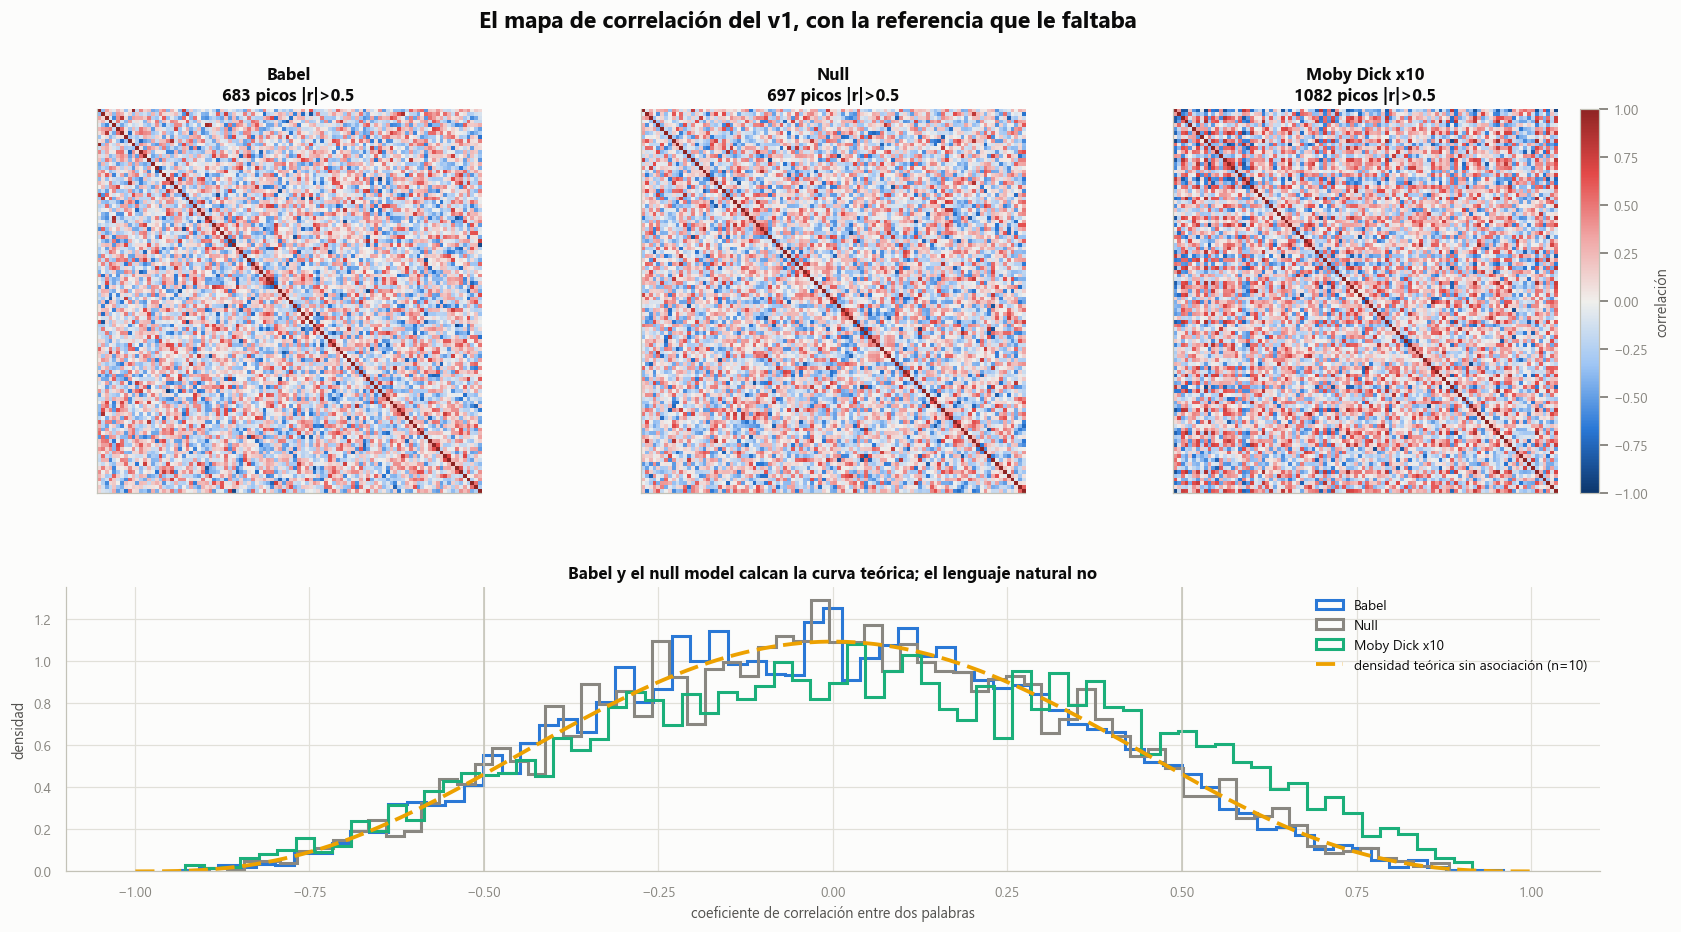

In [46]:
# --- 10.1. El mapa de correlación entre palabras, con su curva nula --------
import babel_viz as bviz
importlib.reload(bviz)
bviz.aplicar_estilo()

TOP_PALABRAS = 100        # el LIMITE_PALABRAS del v1
N_DOC_CORR = 200_000      # la correlación se estabiliza mucho antes de 1,1M

# 10 documentos por condición. Para tener lenguaje natural con n=10 se parte
# Moby Dick en diez trozos: sin eso no habría con qué comparar.
docs_babel = [c.texto[:N_DOC_CORR] for c in corpus_babel]
docs_null = [bc.generar_babel_sintetico(
    N_DOC_CORR, probs_contenido=probs_babel,
    ancho_linea=formato_babel["ancho_linea"],
    lineas_por_pagina=formato_babel["lineas_por_pagina"],
    seed=90_000 + r) for r in range(10)]
_en = CONDICIONES["Control_EN"]
_t = len(_en) // 10
docs_natural = [_en[i * _t:(i + 1) * _t][:N_DOC_CORR] for i in range(10)]

t0 = time.perf_counter()
corr = {"Babel": bviz.correlacion_palabras(docs_babel, TOP_PALABRAS),
        "Null": bviz.correlacion_palabras(docs_null, TOP_PALABRAS),
        "Moby Dick x10": bviz.correlacion_palabras(docs_natural, TOP_PALABRAS)}
print(f"({time.perf_counter()-t0:.0f} s)")

p_teorica = bviz.prob_superar_umbral(10, 0.5)
df_correlacion = pd.DataFrame([{
    "Condición": k,
    "Vocabulario": r["n_vocabulario"],
    "Media": round(r["media"], 4),
    "Máxima": round(r["maxima"], 3),
    "Mínima": round(r["minima"], 3),
    "Picos |r|>0.5": r["n_picos_05"],
    "% de pares": round(100 * r["n_picos_05"] / r["n_pares"], 1),
    "% esperado por azar": round(100 * p_teorica, 1),
} for k, r in corr.items()])
print("CORRELACIÓN ENTRE PALABRAS — n = 10 documentos")
display(df_correlacion)

print(f"\nEl v1 reportó 676 picos sobre {corr['Babel']['n_pares']} pares.")
print(f"La teoría predice {p_teorica*corr['Babel']['n_pares']:.0f} por puro azar.")

fig = plt.figure(figsize=(18, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1.35, 1], hspace=0.28, wspace=0.22)

for j, nombre in enumerate(["Babel", "Null", "Moby Dick x10"]):
    ax = fig.add_subplot(gs[0, j])
    im = ax.imshow(corr[nombre]["matriz"].values, cmap=bviz.cmap_divergente(),
                   vmin=-1, vmax=1)
    ax.set_title(f"{nombre}\n{corr[nombre]['n_picos_05']} picos |r|>0.5")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if j == 2:
        plt.colorbar(im, ax=ax, fraction=0.046, label="correlación")

ax = fig.add_subplot(gs[1, :])
r_grid, dens = bviz.densidad_nula_correlacion(10)
for nombre in ["Babel", "Null", "Moby Dick x10"]:
    color = {"Babel": bviz.COLOR_CONDICION["Babel"],
             "Null": bviz.MUTED,
             "Moby Dick x10": bviz.COLOR_CONDICION["Control_EN"]}[nombre]
    ax.hist(corr[nombre]["correlaciones"], bins=70, density=True, histtype="step",
            linewidth=2, color=color, label=nombre)
ax.plot(r_grid, dens, color=bviz.COLOR_CONDICION["Control_ES"], linewidth=2.5,
        linestyle=(0, (5, 2)), label="densidad teórica sin asociación (n=10)")
ax.axvline(0.5, color=bviz.EJE, linewidth=1)
ax.axvline(-0.5, color=bviz.EJE, linewidth=1)
ax.set_xlabel("coeficiente de correlación entre dos palabras")
ax.set_ylabel("densidad")
ax.set_title("Babel y el null model calcan la curva teórica; el lenguaje natural no")
ax.legend(loc="upper right")

plt.suptitle("El mapa de correlación del v1, con la referencia que le faltaba",
             fontsize=15, fontweight="bold")
plt.savefig(RUTA_FIGURAS / "11_correlacion_palabras.png", dpi=150)
plt.show()


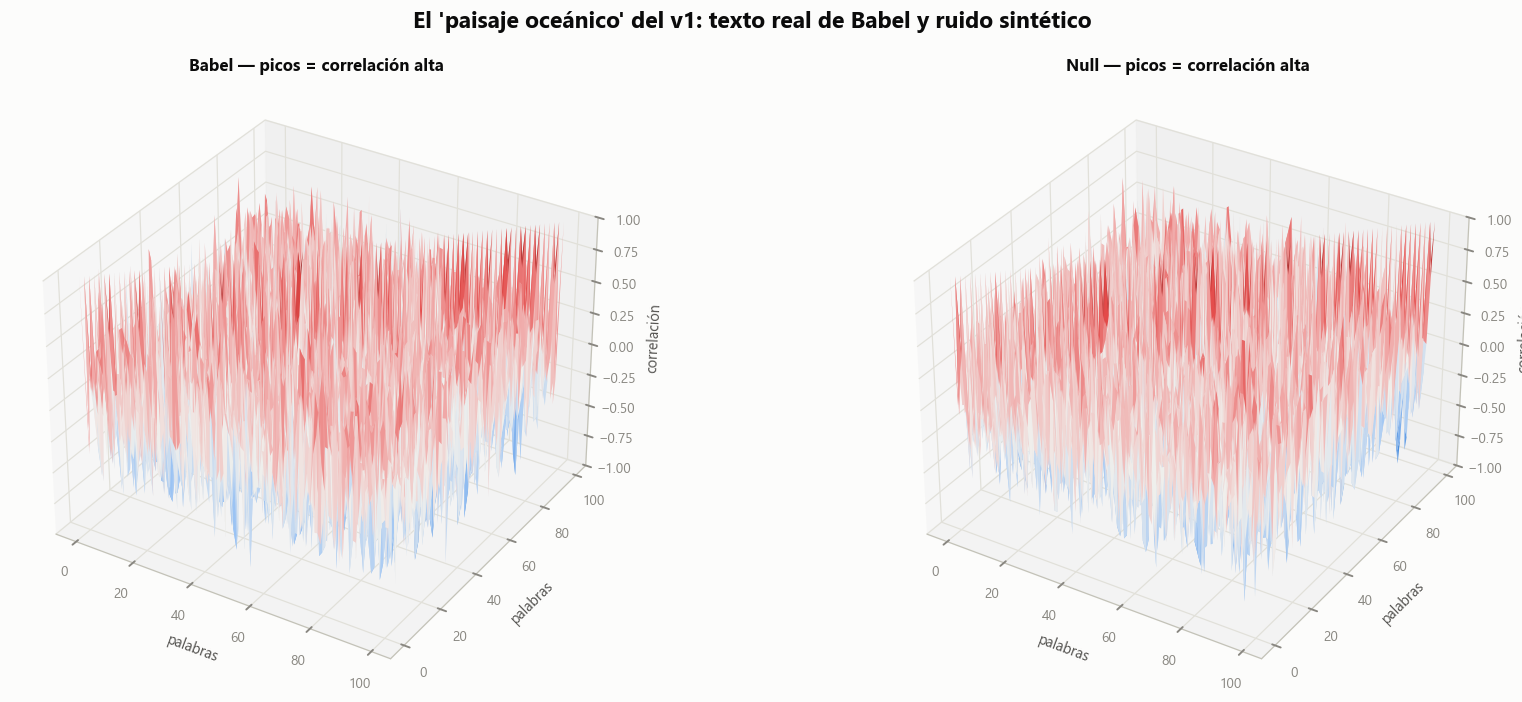

Dos paisajes, mismo relieve. Los 'picos' son el estimador con n=10,
no una propiedad del texto.


In [47]:
# --- 10.2. El paisaje 3D, con su gemelo al lado ----------------------------
# El v1 generó seis vistas 3D de la matriz de correlación (oceánica,
# topográfica, wireframe, contornos, satelital y una animación). Aquí basta una:
# puesta junto a la del null model, la comparación se hace sola.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig = plt.figure(figsize=(17, 6.5))
for j, nombre in enumerate(["Babel", "Null"]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    Z = corr[nombre]["matriz"].values
    X, Y = np.meshgrid(np.arange(Z.shape[0]), np.arange(Z.shape[1]))
    ax.plot_surface(X, Y, Z, cmap=bviz.cmap_divergente(), vmin=-1, vmax=1,
                    linewidth=0, antialiased=True, rcount=100, ccount=100)
    ax.set_title(f"{nombre} — picos = correlación alta")
    ax.set_xlabel("palabras"); ax.set_ylabel("palabras")
    ax.set_zlabel("correlación")
    ax.set_zlim(-1, 1)
    ax.view_init(elev=32, azim=-58)

plt.suptitle("El 'paisaje oceánico' del v1: texto real de Babel y ruido sintético",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "12_paisaje_correlacion_3d.png", dpi=150)
plt.show()

print("Dos paisajes, mismo relieve. Los 'picos' son el estimador con n=10,")
print("no una propiedad del texto.")


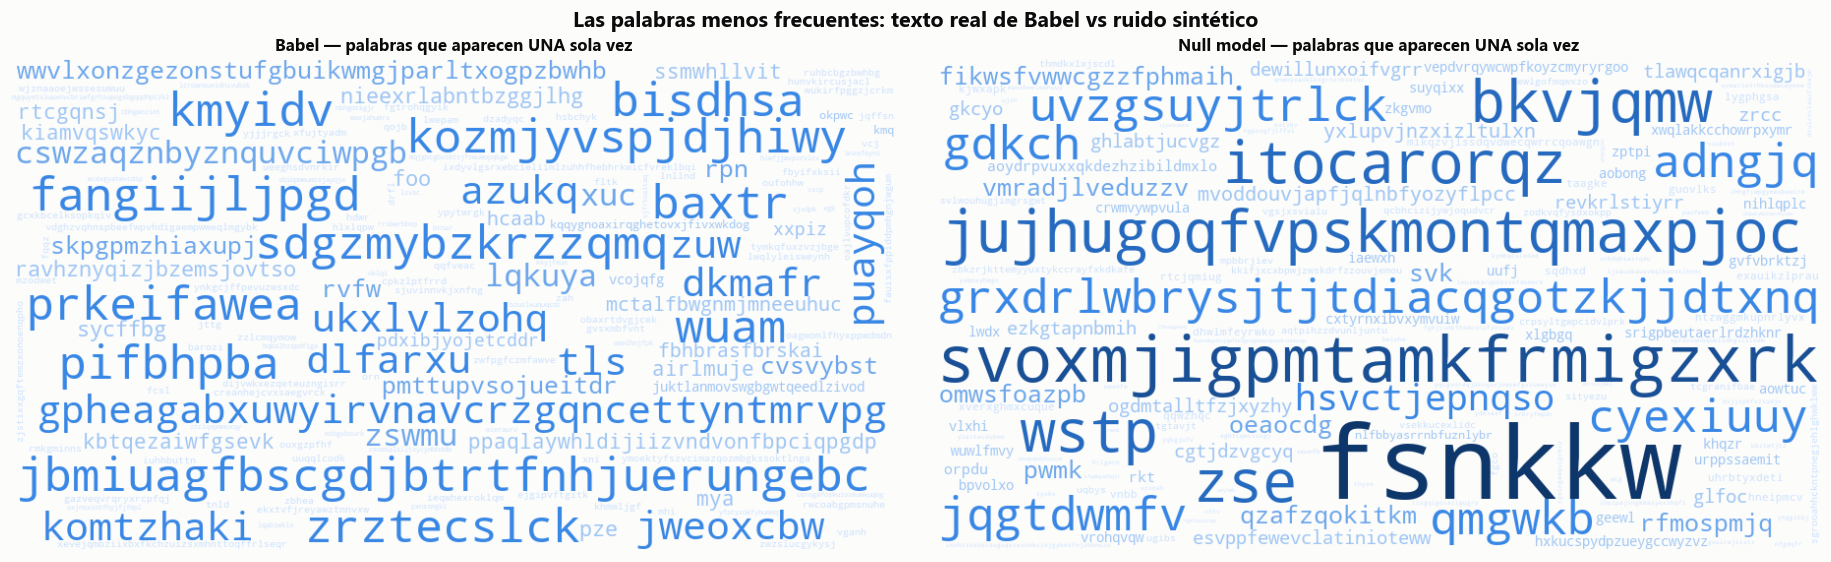


Hapax en Babel: 83,212   ·   en el null model: 83,423
Ni el ojo ni el recuento distinguen cuál es cuál.


In [48]:
# --- 10.3. La nube de palabras menos frecuentes ----------------------------
# El v1 la presentó como hallazgo. Solo significa algo enfrentada a la misma
# nube del null model: dos galimatías indistinguibles dicen más que una tabla.
nube_babel = bviz.nube_de_palabras(tokens_cond["Babel"], solo_hapax=True)
nube_null = bviz.nube_de_palabras(tokens_cond["Null"], solo_hapax=True)

if nube_babel is None:
    print("wordcloud no instalado.  pip install wordcloud")
else:
    fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
    for ax, nube, nombre in ((axes[0], nube_babel, "Babel"),
                             (axes[1], nube_null, "Null model")):
        ax.imshow(nube, interpolation="bilinear")
        ax.axis("off")
        ax.set_title(f"{nombre} — palabras que aparecen UNA sola vez")

    plt.suptitle("Las palabras menos frecuentes: texto real de Babel vs ruido sintético",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(RUTA_FIGURAS / "13_nube_palabras_raras.png", dpi=150)
    plt.show()

    hap_b = sum(1 for t, n in Counter(tokens_cond["Babel"]).items() if n == 1)
    hap_n = sum(1 for t, n in Counter(tokens_cond["Null"]).items() if n == 1)
    print(f"\nHapax en Babel: {hap_b:,}   ·   en el null model: {hap_n:,}")
    print("Ni el ojo ni el recuento distinguen cuál es cuál.")


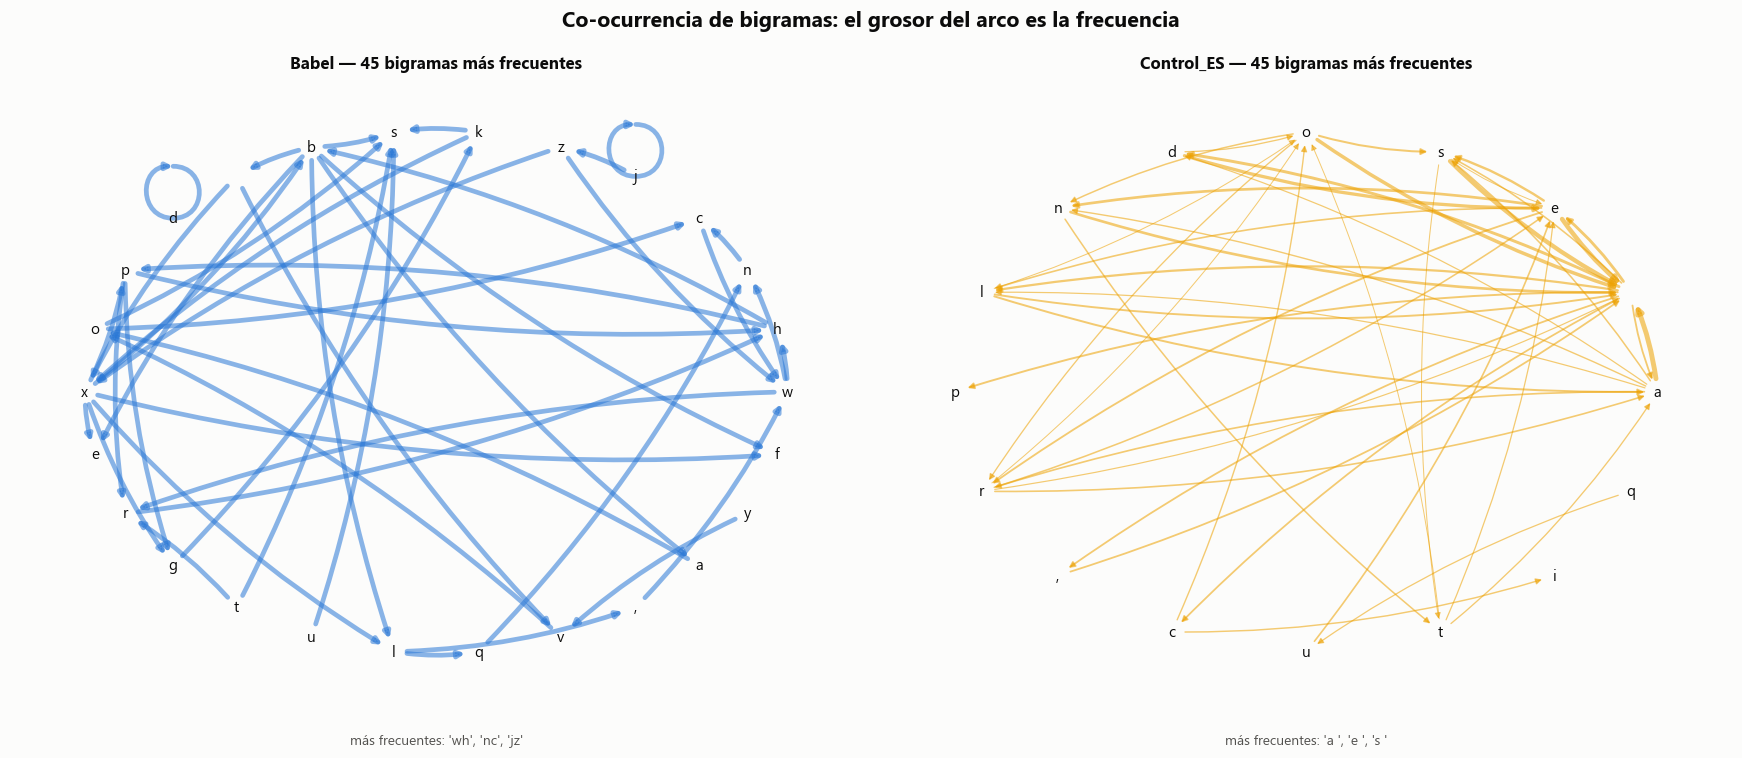

In [49]:
# --- 10.4. Grafo de co-ocurrencia de bigramas (E.2) ------------------------
# Otra vista de la matriz de transición de C.6, más elocuente para un lector no
# técnico: en español unos pocos arcos dominan; en Babel la malla es uniforme.
import networkx as nx

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, nombre in zip(axes, ["Babel", "Control_ES"]):
    G, pesos = bviz.grafo_bigramas(CONDICIONES[nombre], top_n=45)
    pos = nx.circular_layout(G)
    anchos = [3.2 * G[u][v]["weight"] for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, width=anchos, alpha=0.55,
                           edge_color=bviz.COLOR_CONDICION.get(nombre, bviz.MUTED),
                           arrowsize=8, connectionstyle="arc3,rad=0.08")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10,
                            font_color=bviz.TINTA)
    ax.set_title(f"{nombre} — 45 bigramas más frecuentes")
    ax.axis("off")
    ax.grid(False)

    top3 = sorted(pesos.items(), key=lambda x: -x[1])[:3]
    ax.text(0.5, -0.06, "más frecuentes: " +
            ", ".join(f"'{b}'" for b, _ in top3),
            transform=ax.transAxes, ha="center", fontsize=9,
            color=bviz.TINTA_SEC)

plt.suptitle("Co-ocurrencia de bigramas: el grosor del arco es la frecuencia",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS / "14_grafo_bigramas.png", dpi=150)
plt.show()


## 11. Conclusiones del Bloque A

### El veredicto

Con los 10 libros completos (13.288.080 caracteres de cuerpo), normalizados a 1.104.297 caracteres por condición y contrastados contra 100 réplicas Monte Carlo:

**Babel es indistinguible del null model en las 7 métricas.**

| Métrica | Babel | Null μ | IC 95% nulo | Percentil |
|---------|-------|--------|-------------|-----------|
| Entropía relativa (%) | 99,7454 | 99,7454 | [99,745, 99,746] | 53 |
| Compresión gzip | 0,6512 | 0,6513 | [0,651, 0,651] | 49 |
| Pendiente Zipf | −0,9386 | −0,9372 | [−0,949, −0,927] | 34 |
| Heaps β | 0,9697 | 0,9695 | [0,968, 0,974] | 70 |
| χ² p-valor | 0,4687 | 0,3784 | [0,015, 0,952] | 65 |
| Sentimiento (polaridad) | 0,2254 | 0,2051 | [0,085, 0,320] | 60 |
| Sentimiento (subjetividad) | 0,5167 | 0,5214 | [0,438, 0,605] | 46 |

Ninguna cae fuera del intervalo. **No hay señal que explicar.**

### El lenguaje natural sí se separa

| | Babel | Null | Moby Dick | CESS-ESP |
|---|---|---|---|---|
| Entropía relativa | 99,7% | 99,7% | 71,4% | 67,9% |
| Compresión gzip | 0,651 | 0,651 | 0,405 | 0,368 |
| Heaps β | 0,971 | 0,969 | 0,762 | 0,790 |
| **Tipos únicos / tokens** | **0,769** | **0,771** | **0,084** | **0,124** |
| χ² p-valor | 0,47 | 0,38 | ≈ 0 | ≈ 0 |
| % stemming modificado | 8,5% | 8,6% | 32,2% | 80,3% |
| % lematizado | 1,6% | 1,6% | 7,9% | 35,6% |

El separador más crudo no necesita ajuste de curva ninguno: **el 77% de los tokens de Babel son tipos únicos, contra el 8,4% de Moby Dick.**

### Zipf no discrimina, y esa es la lección

Babel: pendiente **−0,940** (R²=0,858). CESS-ESP: **−0,968** (R²=0,988).

La pendiente de Zipf del texto aleatorio es prácticamente la del español real. Es el resultado de Miller (1957) y Mandelbrot (1953) reproducido sobre un corpus concreto: un proceso que genera límites de palabra al azar produce una distribución Zipfiana sin ninguna estructura lingüística detrás.

Lo que sí separa es **Heaps** (0,97 contra 0,76-0,79) y, sobre todo, su comportamiento ante el tramo de ajuste: β es plano en Babel y decreciente en lenguaje natural (§5.3.1). Contrastar ambas leyes es lo que enseña *cuáles* métricas sirven para detectar aleatoriedad.

### Los "hallazgos" del v1, uno por uno

| Afirmación original | Babel | Null model | Veredicto |
|---------------------|-------|------------|-----------|
| "~9% de stopwords" | 7,6% sin filtro · 0,115% con umbral ≥3 | 7,5% · 0,130% | Número **real**, pero el null lo reproduce: combinatoria |
| "Stemming exitoso" | 8,48% modificado | 8,56% | Transformación mecánica de cadenas |
| "Lematización exitosa" | 1,55% | 1,61% | Ídem |
| "Menos frecuentes: siempre 3 caracteres" | mínimo 1 | mínimo 1 | No se sostiene |
| "Sentimiento positivo" | +0,225 | +0,205 | Ver abajo |
| "Los libros comparten ADN estadístico" | — | — | Lo comparten con el null model exactamente igual |

Para referencia, los controles: stopwords reales con umbral ≥3, 30,4% (EN) y 19,0% (ES); stemming 32,2% y 80,3%; lematización 7,9% y 35,6%. Ahí sí hay morfología que encontrar.

### El caso TextBlob merece párrafo aparte

Meter el sentimiento al Monte Carlo cambió lo que se puede afirmar. Babel da polaridad **+0,225** y el null model **+0,205**: la misma. Ninguna diferencia que explicar.

Pero lo interesante está en la comparación con el lenguaje natural. Los controles dan **0,083 (Moby Dick)** y **0,039 (CESS-ESP)** — prácticamente neutros — mientras el ruido promedia **+0,21**, por encima del límite superior de lo que dan los libros reales.

**TextBlob lee más sentimiento positivo en texto aleatorio que en literatura.**

Es lo que justifica haber conservado TextBlob en el estudio en lugar de eliminarlo: no es solo que la herramienta alucine, es que alucina *más* cuanto menos texto real tiene delante.

### Lo que costó llegar aquí

Cuatro de los "hallazgos" de las corridas intermedias resultaron ser defectos del propio aparato de medición, no propiedades de Babel:

1. **Zipf en percentil 99** — el ajuste incluía la cola de hapax, que en texto aleatorio es casi todo el vocabulario y es una recta horizontal en log-log.
2. **χ² en percentil 100** — el null model se calibraba con las frecuencias empíricas de una muestra pequeña, así que heredaba su ruido y luego le sumaba ruido fresco encima.
3. **Entropía en percentil 100** — el null model no replicaba la paginación (410 páginas separadas por línea en blanco), así que su frecuencia de salto era 1/81 en vez de 1/79,06.
4. **Sentimiento de Babel al doble que el del null** (0,486 vs 0,195) — la limpieza borraba comas y puntos en vez de tratarlos como frontera, pegando tokens y dejando a TextBlob sin palabras que reconocer. Corregido, ambos dan ~0,21.

Los cuatro apuntan a la misma moraleja, y es la del proyecto entero: **antes de creerse un hallazgo hay que descartar que lo esté produciendo el instrumento.**

### La respuesta a Borges

> *¿Deja rastros la verdadera aleatoriedad? ¿Puede el caos generar patrones?*

**No los que creíamos.** Lo que el estudio original interpretó como "islas de significado" o "ADN estadístico compartido" es exactamente lo que predice el modelo nulo. El caos de Babel no converge sobre sí mismo: **es ruido, y se comporta como ruido**. La estructura que veíamos era el reflejo de nuestras herramientas lingüísticas proyectándose sobre el vacío — herramientas diseñadas para encontrar lenguaje, encontrando "lenguaje" donde no lo hay.

Paradójicamente, esto es **más** borgeano: la Biblioteca no esconde sentido en su caos; el sentido lo aporta el bibliotecario que lee.

### Próximos pasos (Bloque B y siguientes)

Con el fundamento estadístico sólido, los siguientes bloques pueden explorar herramientas modernas (HuggingFace, embeddings, BERTopic) **sabiendo que cualquier "patrón" que encuentren debe contrastarse contra este null model** para ser creíble.


## 12. Exportación de resultados

In [50]:
# Exportar todas las tablas a CSV
tablas = {
    "01_perfil_alfabeto": df_probs,
    "02_pipeline_clasico": df_pipeline,
    "03_sensibilidad_umbral": df_sensibilidad,
    "04_entropia": df_entropia,
    "05_compresion": df_compresion,
    "06_leyes_zipf_heaps": df_leyes,
    "07_chi2_uniformidad": df_chi,
    "08_veredicto_montecarlo": df_veredicto,
    "09_distribucion_null_mc": dist_null,
    "10_sensibilidad_heaps": df_heaps_sens,
}
if EJECUTAR_BLOQUE_B and dist_tr is not None:
    tablas["11_bloque_b_condiciones"] = df_bloque_b
    tablas["12_bloque_b_veredicto"] = df_veredicto_b
    tablas["13_bloque_b_idiomas"] = df_idiomas
tablas["14_bloque_c_ganancia"] = df_ganancia
tablas["15_bloque_c_veredicto"] = df_veredicto_c
tablas["16_bloque_c_perplejidad"] = df_perplejidad
tablas["17_bloque_c_divergencia"] = df_divergencia
if EJECUTAR_BLOQUE_C2 and embedder is not None:
    tablas["18_bloque_c_nube"] = df_nube
    tablas["19_bloque_c_veredicto_emb"] = df_veredicto_c2
    if filas_top:
        tablas["20_bloque_c_topicos"] = df_topicos
if pares_jaccard:
    tablas["21_bloque_c_jaccard"] = df_jaccard
if info_lexico["disponible"]:
    tablas["22_bloque_d_combinatoria"] = df_combinatoria
    tablas["23_bloque_d_emergentes"] = df_emergentes
    tablas["24_bloque_d_veredicto"] = df_veredicto_d
    tablas["25_bloque_d_por_libro"] = df_por_libro
if resultado_semantico:
    tablas["26_bloque_d_semantica"] = df_semantica
tablas["27_correlacion_palabras"] = df_correlacion

for nombre, df in tablas.items():
    ruta = RUTA_OUTPUTS / f"{nombre}.csv"
    df.to_csv(ruta, index=False, encoding="utf-8-sig")
    print(f"  OK {ruta.name}")

print(f"\n{len(tablas)} tablas exportadas a {RUTA_OUTPUTS}")
print(f"6 figuras exportadas a {RUTA_FIGURAS}")

n_ok = (df_veredicto["¿Indistinguible?"].str.startswith("✓")).sum()
print("\n" + "=" * 62)
print(f"BLOQUE A COMPLETADO — {n_ok}/{len(df_veredicto)} métricas indistinguibles del null model")
print("=" * 62)


  OK 01_perfil_alfabeto.csv
  OK 02_pipeline_clasico.csv
  OK 03_sensibilidad_umbral.csv
  OK 04_entropia.csv
  OK 05_compresion.csv
  OK 06_leyes_zipf_heaps.csv
  OK 07_chi2_uniformidad.csv
  OK 08_veredicto_montecarlo.csv
  OK 09_distribucion_null_mc.csv
  OK 10_sensibilidad_heaps.csv
  OK 11_bloque_b_condiciones.csv
  OK 12_bloque_b_veredicto.csv
  OK 13_bloque_b_idiomas.csv
  OK 14_bloque_c_ganancia.csv
  OK 15_bloque_c_veredicto.csv
  OK 16_bloque_c_perplejidad.csv
  OK 17_bloque_c_divergencia.csv
  OK 18_bloque_c_nube.csv
  OK 19_bloque_c_veredicto_emb.csv
  OK 20_bloque_c_topicos.csv
  OK 21_bloque_c_jaccard.csv
  OK 22_bloque_d_combinatoria.csv
  OK 23_bloque_d_emergentes.csv
  OK 24_bloque_d_veredicto.csv
  OK 25_bloque_d_por_libro.csv
  OK 26_bloque_d_semantica.csv
  OK 27_correlacion_palabras.csv

27 tablas exportadas a C:\Users\diego.perezp\Documents\GitHub\Mining the Random - Library of Babel\Babel_V2\outputs
6 figuras exportadas a C:\Users\diego.perezp\Documents\GitHub\Mi